# ST1504 Deep Learning CA2 - Part A

## Image Generation Using GANs and a VAE on CIFAR-10

This notebook uses the CIFAR-10 dataset to build and compare several image-generation models. 

- Eaint Chu Nay Chi
- Phyu Sin Lynn

# 1. Data Preparation

## 1.1 Importing the Required Libraries

In [1]:
import os
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from scipy.linalg import sqrtm
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.inception_v3 import (
    InceptionV3,
    preprocess_input
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.10.0


## 1.2 Setting the Random Seed

A fixed seed is used to make the data split and generated samples more reproducible. GAN results can still vary slightly because some GPU operations are not fully deterministic.

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


## 1.3 Checking the Available Hardware

Training generative models is much faster with a GPU. This cell shows whether TensorFlow can detect one.

In [3]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU detected:", gpus)
else:
    print("No GPU detected. Training will run on the CPU.")

GPU detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1.4 Loading the CIFAR-10 Dataset

CIFAR-10 contains 32 × 32 colour images from 10 classes. Only the dataset provided through TensorFlow is used for model training.

In [4]:
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = (
    keras.datasets.cifar10.load_data()
)

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

y_train_raw = y_train_raw.flatten()
y_test_raw = y_test_raw.flatten()

print("Training images:", x_train_raw.shape)
print("Training labels:", y_train_raw.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test_raw.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)


# 2. Exploring and Preparing the Dataset

## 2.1 Checking the Image Values and Classes

The dataset is checked before model building so that problems such as unexpected image shapes, missing values or invalid labels can be found early.

In [5]:
print("Image dtype:", x_train_raw.dtype)
print("Minimum pixel value:", x_train_raw.min())
print("Maximum pixel value:", x_train_raw.max())
print("Number of classes:", len(np.unique(y_train_raw)))
print("Class labels:", np.unique(y_train_raw))

Image dtype: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Number of classes: 10
Class labels: [0 1 2 3 4 5 6 7 8 9]


## 2.2 Checking Missing Values, Image Shapes and Constant Images

Image datasets normally do not contain missing values, but these checks confirm that the supplied data is suitable for training.

In [6]:
missing_images = np.isnan(x_train_raw).sum()
missing_labels = np.isnan(y_train_raw).sum()

unique_shapes = np.unique(
    [image.shape for image in x_train_raw],
    axis=0
)

image_std = np.std(
    x_train_raw.astype("float32"),
    axis=(1, 2, 3)
)

constant_images = np.sum(image_std == 0)

print("Missing image values:", missing_images)
print("Missing label values:", missing_labels)
print("Unique image shapes:", unique_shapes)
print("Constant images:", constant_images)

Missing image values: 0
Missing label values: 0
Unique image shapes: [[32 32  3]]
Constant images: 0


## 2.3 Checking Duplicate Images

Duplicate images are identified by flattening each image and comparing the resulting rows. The images are not removed because CIFAR-10 is a fixed benchmark dataset and the check is mainly used to understand the data.

In [7]:
flattened_images = x_train_raw.reshape(
    x_train_raw.shape[0],
    -1
)

unique_image_count = np.unique(
    flattened_images,
    axis=0
).shape[0]

duplicate_count = x_train_raw.shape[0] - unique_image_count

print("Unique training images:", unique_image_count)
print("Duplicate training images:", duplicate_count)

Unique training images: 50000
Duplicate training images: 0


## 2.4 Checking the Class Distribution

The class distribution was checked to determine whether any CIFAR-10 class was underrepresented before model training. This is especially important for the Conditional GAN (CGAN), as the model learns to generate images based on class labels.

In [8]:
class_counts = np.bincount(
    y_train_raw,
    minlength=len(class_names)
)

class_distribution = pd.DataFrame({
    "Class ID": range(len(class_names)),
    "Class": class_names,
    "Training Images": class_counts
})

display(class_distribution)

,Class ID,Class,Training Images
0,0,airplane,5000
1,1,automobile,5000
2,2,bird,5000
3,3,cat,5000
4,4,deer,5000
5,5,dog,5000
6,6,frog,5000
7,7,horse,5000
8,8,ship,5000
9,9,truck,5000


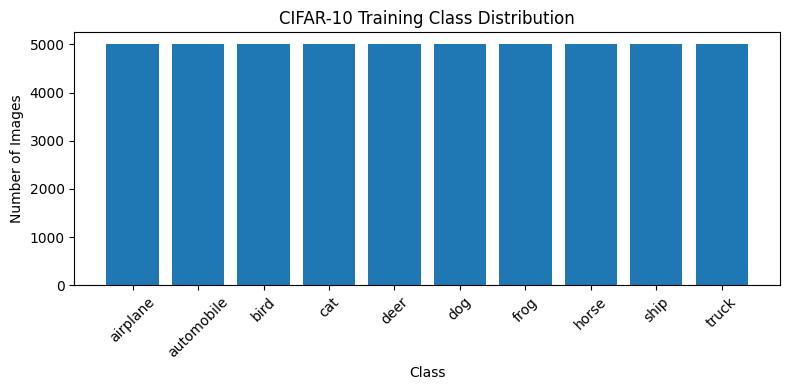

In [9]:
plt.figure(figsize=(8, 4))

plt.bar(
    class_names,
    class_counts
)

plt.title("CIFAR-10 Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

## 2.5 Sample Images from Each Class

Three training images from each CIFAR-10 class are displayed to examine the visual characteristics and variation within the dataset. Showing multiple examples per class gives a better representation than a single image, as objects from the same class can differ in colour, shape, orientation and background.

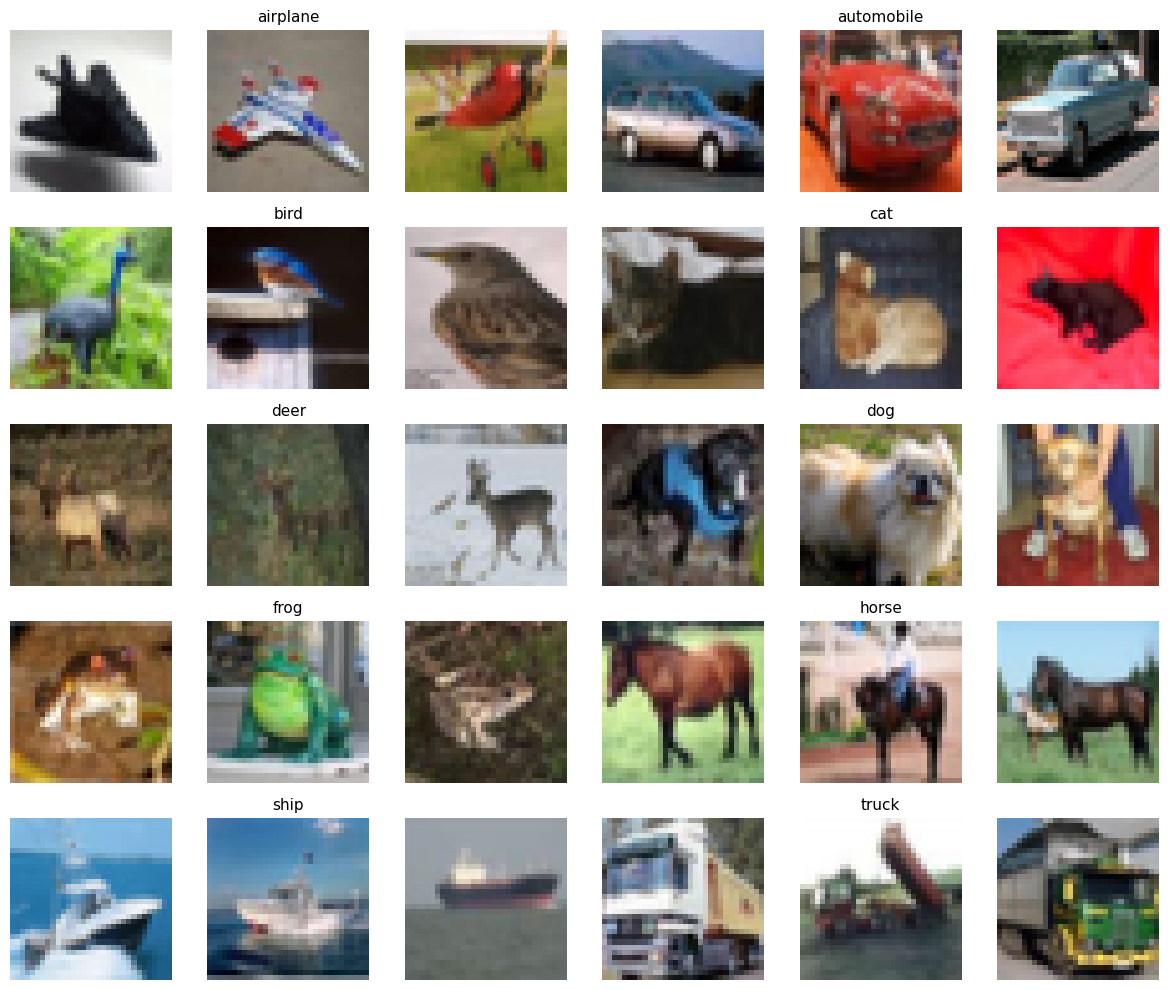

In [10]:
plt.figure(figsize=(12, 10))

images_per_class = 3

for class_id, class_name in enumerate(class_names):

    class_indices = np.where(
        y_train_raw == class_id
    )[0][:images_per_class]

    for image_number, image_index in enumerate(
        class_indices
    ):

        plot_position = (
            class_id * images_per_class
            + image_number
            + 1
        )

        plt.subplot(
            5,
            6,
            plot_position
        )

        plt.imshow(
            x_train_raw[image_index]
        )

        if image_number == 1:
            plt.title(
                class_name,
                fontsize=11
            )

        plt.axis("off")

plt.tight_layout()
plt.show()

**Observation:**  
The samples show clear variation within each CIFAR-10 class. Images from the same class differ in colour, orientation, object size and background, while some classes such as cats, dogs, deer and horses share similar visual features. The low 32 × 32 resolution also makes some objects less distinct.

This suggests that generating realistic CIFAR-10 images may be more challenging for visually similar classes, as the model needs to learn both the general features of each class and the variation within them.

## 2.6 Creating Training and Validation Sets

A validation set is kept for evaluation and visual checks(FID). The split is stratified so that all classes maintain a similar proportion.

In [11]:
(
    x_train_split,
    x_validation,
    y_train_split,
    y_validation
) = train_test_split(
    x_train_raw,
    y_train_raw,
    test_size=0.1,
    random_state=SEED,
    stratify=y_train_raw
)

print("Training split:", x_train_split.shape)
print("Validation split:", x_validation.shape)

Training split: (45000, 32, 32, 3)
Validation split: (5000, 32, 32, 3)


## 2.7 Pixel Value Distribution

The distribution of pixel intensities is examined before preprocessing to understand the original scale of the CIFAR-10 images.

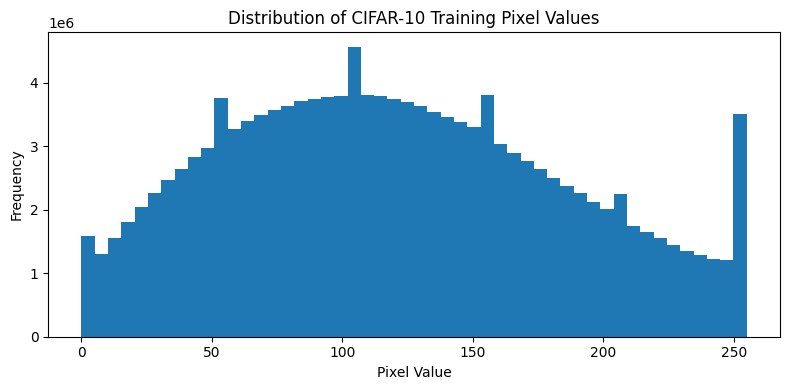

Minimum: 0
Maximum: 255
Mean: 120.67428969907408


In [12]:
plt.figure(figsize=(8, 4))

plt.hist(
    x_train_split.flatten(),
    bins=50
)

plt.title("Distribution of CIFAR-10 Training Pixel Values")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Minimum:", x_train_split.min())
print("Maximum:", x_train_split.max())
print("Mean:", x_train_split.mean())

**Observation:**  
The CIFAR-10 training images use the full pixel range from 0 to 255, with a mean intensity of approximately 120.67. The histogram also shows that the images contain a broad range of pixel intensities rather than being concentrated around a small range.

Before GAN training, these pixel values will be scaled to [-1, 1] to match the `tanh` output range of the generator. This ensures that the real and generated images are represented on the same scale during training.

## 2.8 Normalising the Images

GAN images are normalised to the range [-1, 1] because the generators use `tanh` in their output layer. VAE images are separately scaled to [0, 1] because reconstruction loss is calculated in that range.

In [13]:
x_train_gan = (
    x_train_split.astype("float32") - 127.5
) / 127.5

x_validation_gan = (
    x_validation.astype("float32") - 127.5
) / 127.5

x_train_vae = (
    x_train_split.astype("float32") / 255.0
)

x_validation_vae = (
    x_validation.astype("float32") / 255.0
)

print("GAN range:", x_train_gan.min(), "to", x_train_gan.max())
print("VAE range:", x_train_vae.min(), "to", x_train_vae.max())

GAN range: -1.0 to 1.0
VAE range: 0.0 to 1.0


# 3. Shared Setup
## 3.1 Shared Settings and Dataset Helper

The common settings are kept together. The dataset helper avoids repeating the same shuffle, batch and prefetch code in every experiment.

In [14]:
IMAGE_SHAPE = (32, 32, 3)
NUM_CLASSES = 10
BATCH_SIZE = 128
BUFFER_SIZE = len(x_train_gan)
BASE_EPOCHS = 50
LEARNING_RATE = 0.0002
BETA_1 = 0.5

OUTPUT_ROOT = Path("part_a_outputs")
OUTPUT_ROOT.mkdir(exist_ok=True)


def create_dataset(
    images,
    labels=None,
    batch_size=BATCH_SIZE,
    augment_fn=None,
    shuffle=True
):
    if labels is None:
        dataset = tf.data.Dataset.from_tensor_slices(images)
    else:
        dataset = tf.data.Dataset.from_tensor_slices(
            (images, labels)
        )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(images),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    if augment_fn is not None:
        dataset = dataset.map(
            augment_fn,
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(
        batch_size,
        drop_remainder=True
    )

    return dataset.prefetch(tf.data.AUTOTUNE)


dcgan_dataset = create_dataset(x_train_gan)
cgan_dataset = create_dataset(
    x_train_gan,
    y_train_split
)

print("DCGAN batches:", tf.data.experimental.cardinality(dcgan_dataset).numpy())
print("CGAN batches:", tf.data.experimental.cardinality(cgan_dataset).numpy())

DCGAN batches: 351
CGAN batches: 351


## 3.2 Shared Visualisation and Saving Functions

These functions are used across the models so that generated samples are displayed and saved in a consistent way.

In [15]:
def denormalise_gan_images(images):
    images = (images + 1.0) / 2.0
    return tf.clip_by_value(images, 0.0, 1.0)


def show_image_grid(
    images,
    titles=None,
    rows=4,
    columns=4,
    figure_title=None
):
    images = np.asarray(images)
    total = min(len(images), rows * columns)

    plt.figure(figsize=(columns * 2, rows * 2))

    if figure_title:
        plt.suptitle(figure_title, fontsize=14)

    for index in range(total):
        plt.subplot(rows, columns, index + 1)
        plt.imshow(np.clip(images[index], 0.0, 1.0))

        if titles is not None:
            plt.title(str(titles[index]))

        plt.axis("off")

    plt.tight_layout()
    plt.show()


def plot_training_losses(
    generator_losses,
    discriminator_losses,
    title
):
    plt.figure(figsize=(8, 5))
    plt.plot(generator_losses, label="Generator loss")
    plt.plot(discriminator_losses, label="Discriminator loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def save_image_array(image, file_path):
    image = np.clip(image, 0.0, 1.0)
    keras.utils.save_img(
        file_path,
        image,
        scale=True
    )

## 3.3 Shared FID Functions

FID compares feature distributions from real and generated images. Lower values indicate that the generated image distribution is closer to the real image distribution.

The CIFAR-10 images are resized to 299 × 299 because InceptionV3 expects larger inputs.

In [16]:
# -------------------------------------------------
# Shared FID Setup
# -------------------------------------------------

fid_feature_model = InceptionV3(
    include_top=False,
    weights="imagenet",
    pooling="avg",
    input_shape=(299, 299, 3)
)


def prepare_images_for_fid(images):

    images = tf.convert_to_tensor(
        images,
        dtype=tf.float32
    )

    # If GAN images are in [-1, 1],
    # convert them back to [0, 1]
    if tf.reduce_min(images) < 0:

        images = denormalise_gan_images(
            images
        )

    # Resize CIFAR-10 images from
    # 32 × 32 to 299 × 299
    images = tf.image.resize(
        images,
        (299, 299)
    )

    # Convert [0, 1] to [0, 255]
    images = images * 255.0

    # Apply InceptionV3 preprocessing
    images = preprocess_input(
        images
    )

    return images


def extract_fid_features(
    images,
    batch_size=64
):

    feature_batches = []

    dataset = (
        tf.data.Dataset
        .from_tensor_slices(images)
        .batch(batch_size)
    )

    for image_batch in dataset:

        prepared_batch = prepare_images_for_fid(
            image_batch
        )

        features = fid_feature_model(
            prepared_batch,
            training=False
        )

        feature_batches.append(
            features.numpy()
        )

    return np.concatenate(
        feature_batches,
        axis=0
    )


def calculate_fid_from_features(
    real_features,
    generated_features
):

    # Mean feature vectors
    real_mean = np.mean(
        real_features,
        axis=0
    )

    generated_mean = np.mean(
        generated_features,
        axis=0
    )

    # Covariance matrices
    real_covariance = np.cov(
        real_features,
        rowvar=False
    )

    generated_covariance = np.cov(
        generated_features,
        rowvar=False
    )

    # Difference between means
    mean_difference = (
        real_mean - generated_mean
    )

    # Matrix square root
    covariance_mean = sqrtm(
        real_covariance
        @ generated_covariance
    )

    # Remove very small imaginary values
    # caused by numerical calculation
    if np.iscomplexobj(
        covariance_mean
    ):
        covariance_mean = (
            covariance_mean.real
        )

    # FID calculation
    fid = (
        mean_difference.dot(
            mean_difference
        )
        + np.trace(
            real_covariance
            + generated_covariance
            - 2.0 * covariance_mean
        )
    )

    return float(fid)


# -------------------------------------------------
# Create Balanced Real FID Reference Set
# -------------------------------------------------

FID_IMAGES_PER_CLASS = 500

FID_SAMPLE_SIZE = (
    FID_IMAGES_PER_CLASS
    * NUM_CLASSES
)

fid_real_images = []
fid_real_labels = []


for class_id in range(
    NUM_CLASSES
):

    # Find all validation images
    # belonging to this class
    class_indices = np.where(
        y_validation == class_id
    )[0]

    # Select exactly 500 images
    selected_indices = (
        class_indices[
            :FID_IMAGES_PER_CLASS
        ]
    )

    # Get the selected images
    class_images = x_validation[
        selected_indices
    ].astype(
        "float32"
    ) / 255.0

    fid_real_images.append(
        class_images
    )

    fid_real_labels.extend(
        [class_id]
        * FID_IMAGES_PER_CLASS
    )


# Combine all classes
fid_real_images = np.concatenate(
    fid_real_images,
    axis=0
)

fid_real_labels = np.array(
    fid_real_labels
)


# -------------------------------------------------
# Check the Real FID Dataset
# -------------------------------------------------

print(
    "Real FID images:",
    fid_real_images.shape
)

print(
    "Real FID labels:",
    fid_real_labels.shape
)

print(
    "Images per class:",
    np.bincount(
        fid_real_labels,
        minlength=NUM_CLASSES
    )
)


# -------------------------------------------------
# Extract Real Image Features Once
# -------------------------------------------------

real_fid_features = (
    extract_fid_features(
        fid_real_images
    )
)

print(
    "Real FID features:",
    real_fid_features.shape
)

Real FID images: (5000, 32, 32, 3)
Real FID labels: (5000,)
Images per class: [500 500 500 500 500 500 500 500 500 500]
Real FID features: (5000, 2048)


# 4. Baseline Models

## 4.1 Baseline DCGAN

### 4.1.1 Model Settings

The DCGAN uses random noise with 100 values as its input. It is unconditional, so the generator cannot be asked to create a particular CIFAR-10 class.

In [17]:
DCGAN_LATENT_DIM = 100
DCGAN_EPOCHS = BASE_EPOCHS

### 4.1.2 Building the DCGAN Generator

The generator starts from a small 4 × 4 feature map and gradually upsamples it to a 32 × 32 RGB image.

In [18]:
def build_dcgan_generator(
    latent_dim=DCGAN_LATENT_DIM
):
    model = keras.Sequential(
        [
            layers.Input(shape=(latent_dim,)),
            layers.Dense(
                4 * 4 * 256,
                use_bias=False
            ),
            layers.BatchNormalization(),
            layers.ReLU(),
            layers.Reshape((4, 4, 256)),

            layers.Conv2DTranspose(
                128,
                kernel_size=4,
                strides=2,
                padding="same",
                use_bias=False
            ),
            layers.BatchNormalization(),
            layers.ReLU(),

            layers.Conv2DTranspose(
                64,
                kernel_size=4,
                strides=2,
                padding="same",
                use_bias=False
            ),
            layers.BatchNormalization(),
            layers.ReLU(),

            layers.Conv2DTranspose(
                3,
                kernel_size=4,
                strides=2,
                padding="same",
                activation="tanh"
            )
        ],
        name="dcgan_generator"
    )

    return model


dcgan_generator = build_dcgan_generator()
dcgan_generator.summary()

Model: "dcgan_generator"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 4096)              409600    
                                                                 
 batch_normalization_94 (Bat  (None, 4096)             16384     
 chNormalization)                                                
                                                                 
 re_lu (ReLU)                (None, 4096)              0         
                                                                 
 reshape (Reshape)           (None, 4, 4, 256)         0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 8, 8, 128)        524288    
 nspose)                                                         
                                                                 
 batch_normalization_95 (Bat  (None, 8, 8, 128)    

**Baseline DCGAN Generator Architecture:**  
The generator starts by transforming the 100-dimensional latent vector into a 4 × 4 × 256 feature representation. It then progressively increases the spatial size through transposed convolution layers:

**4 × 4 × 256 → 8 × 8 × 128 → 16 × 16 × 64 → 32 × 32 × 3**

Batch normalization and ReLU activation are used between the upsampling layers to support stable training and allow the generator to learn more complex features. The final layer produces a 32 × 32 RGB image, matching the size of the CIFAR-10 images.

The final output uses `tanh`, which produces values between -1 and 1 and therefore matches the normalization applied to the real training images.

### 4.1.3 Building the DCGAN Discriminator

The discriminator reduces the image size through convolutional layers and returns one logit indicating whether the image appears real or generated.

In [19]:
def build_dcgan_discriminator():
    model = keras.Sequential(
        [
            layers.Input(shape=IMAGE_SHAPE),

            layers.Conv2D(
                64,
                kernel_size=4,
                strides=2,
                padding="same"
            ),
            layers.LeakyReLU(alpha=0.2),

            layers.Conv2D(
                128,
                kernel_size=4,
                strides=2,
                padding="same",
                use_bias=False
            ),
            layers.BatchNormalization(),
            layers.LeakyReLU(alpha=0.2),

            layers.Conv2D(
                256,
                kernel_size=4,
                strides=2,
                padding="same",
                use_bias=False
            ),
            layers.BatchNormalization(),
            layers.LeakyReLU(alpha=0.2),

            layers.Flatten(),
            layers.Dense(1)
        ],
        name="dcgan_discriminator"
    )

    return model


dcgan_discriminator = build_dcgan_discriminator()
dcgan_discriminator.summary()

Model: "dcgan_discriminator"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_94 (Conv2D)          (None, 16, 16, 64)        3136      
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 16, 16, 64)        0         
                                                                 
 conv2d_95 (Conv2D)          (None, 8, 8, 128)         131072    
                                                                 
 batch_normalization_97 (Bat  (None, 8, 8, 128)        512       
 chNormalization)                                                
                                                                 
 leaky_re_lu_1 (LeakyReLU)   (None, 8, 8, 128)         0         
                                                                 
 conv2d_96 (Conv2D)          (None, 4, 4, 256)         524288    
                                               

**Baseline DCGAN Discriminator Architecture:**

The discriminator takes a **32 × 32 × 3 RGB image** and progressively reduces its spatial dimensions using convolutional layers:

**32 × 32 × 3 → 16 × 16 × 64 → 8 × 8 × 128 → 4 × 4 × 256 → 1 output**

As the image becomes smaller, the number of feature maps increases from **64 to 128 to 256**, allowing the discriminator to learn increasingly detailed features for distinguishing real CIFAR-10 images from generated images.

LeakyReLU is used after each convolutional layer to maintain gradient flow during training, while batch normalization is applied in the deeper layers to support more stable learning.

Finally, the **4 × 4 × 256** feature representation is flattened and passed to a single output neuron, which produces the discriminator's real-or-fake prediction.

### 4.1.4 Training the DCGAN

A reusable trainer is used for the baseline. The generator and discriminator are updated once for every batch.

In [22]:
binary_cross_entropy = keras.losses.BinaryCrossentropy(
    from_logits=True
)


def generator_loss(fake_output):
    return binary_cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )


def discriminator_loss(
    real_output,
    fake_output,
    real_label_value=1.0
):
    real_labels = (
        tf.ones_like(real_output)
        * real_label_value
    )

    real_loss = binary_cross_entropy(
        real_labels,
        real_output
    )

    fake_loss = binary_cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss


dcgan_generator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

dcgan_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)


@tf.function(reduce_retracing=True)
def dcgan_train_step(real_images):
    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal(
        (batch_size, DCGAN_LATENT_DIM)
    )

    with tf.GradientTape() as generator_tape,          tf.GradientTape() as discriminator_tape:

        generated_images = dcgan_generator(
            noise,
            training=True
        )

        real_output = dcgan_discriminator(
            real_images,
            training=True
        )

        fake_output = dcgan_discriminator(
            generated_images,
            training=True
        )

        generator_loss_value = generator_loss(
            fake_output
        )

        discriminator_loss_value = discriminator_loss(
            real_output,
            fake_output
        )

    generator_gradients = generator_tape.gradient(
        generator_loss_value,
        dcgan_generator.trainable_variables
    )

    discriminator_gradients = discriminator_tape.gradient(
        discriminator_loss_value,
        dcgan_discriminator.trainable_variables
    )

    dcgan_generator_optimizer.apply_gradients(
        zip(
            generator_gradients,
            dcgan_generator.trainable_variables
        )
    )

    dcgan_discriminator_optimizer.apply_gradients(
        zip(
            discriminator_gradients,
            dcgan_discriminator.trainable_variables
        )
    )

    return (
        generator_loss_value,
        discriminator_loss_value
    )


def train_dcgan(dataset, epochs):
    generator_losses = []
    discriminator_losses = []

    for epoch in range(epochs):
        epoch_generator_losses = []
        epoch_discriminator_losses = []

        for real_images in dataset:
            (
                generator_loss_value,
                discriminator_loss_value
            ) = dcgan_train_step(real_images)

            epoch_generator_losses.append(
                generator_loss_value
            )

            epoch_discriminator_losses.append(
                discriminator_loss_value
            )

        mean_generator_loss = float(
            tf.reduce_mean(
                epoch_generator_losses
            ).numpy()
        )

        mean_discriminator_loss = float(
            tf.reduce_mean(
                epoch_discriminator_losses
            ).numpy()
        )

        generator_losses.append(
            mean_generator_loss
        )

        discriminator_losses.append(
            mean_discriminator_loss
        )

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Generator: {mean_generator_loss:.4f} "
            f"- Discriminator: {mean_discriminator_loss:.4f}"
        )

    return generator_losses, discriminator_losses

### 4.1.5 Training and Saving the DCGAN

This cell performs the full training and saves the generator weights. Change the number of epochs only when carrying out a separate trial.

In [23]:
dcgan_generator_losses, dcgan_discriminator_losses = (
    train_dcgan(
        dcgan_dataset,
        DCGAN_EPOCHS
    )
)

dcgan_generator.save_weights(
    OUTPUT_ROOT / "dcgan_generator.weights.h5"
)

Epoch 1/50 - Generator: 3.9298 - Discriminator: 0.1183
Epoch 2/50 - Generator: 3.2924 - Discriminator: 0.3047
Epoch 3/50 - Generator: 3.4445 - Discriminator: 0.2046
Epoch 4/50 - Generator: 2.9028 - Discriminator: 0.3827
Epoch 5/50 - Generator: 2.9815 - Discriminator: 0.2975
Epoch 6/50 - Generator: 3.1885 - Discriminator: 0.2349
Epoch 7/50 - Generator: 3.2211 - Discriminator: 0.3180
Epoch 8/50 - Generator: 3.0707 - Discriminator: 0.3115
Epoch 9/50 - Generator: 2.8046 - Discriminator: 0.3747
Epoch 10/50 - Generator: 2.6100 - Discriminator: 0.4264
Epoch 11/50 - Generator: 2.5451 - Discriminator: 0.4662
Epoch 12/50 - Generator: 2.4440 - Discriminator: 0.4676
Epoch 13/50 - Generator: 2.4852 - Discriminator: 0.4863
Epoch 14/50 - Generator: 2.4550 - Discriminator: 0.4500
Epoch 15/50 - Generator: 2.4447 - Discriminator: 0.4848
Epoch 16/50 - Generator: 2.5385 - Discriminator: 0.4112
Epoch 17/50 - Generator: 2.5041 - Discriminator: 0.4907
Epoch 18/50 - Generator: 2.4828 - Discriminator: 0.4847
E

### 4.1.6 DCGAN Results

The generated samples and loss curves are used to check whether the model learned meaningful colours and shapes and whether either network became too dominant.

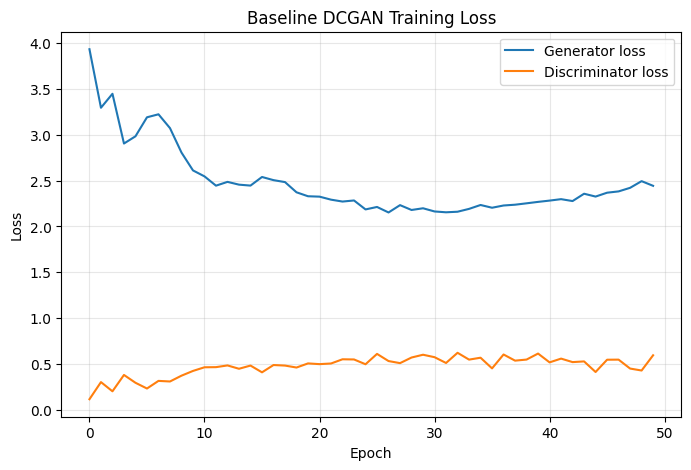

In [24]:
plot_training_losses(
    dcgan_generator_losses,
    dcgan_discriminator_losses,
    "Baseline DCGAN Training Loss"
)

### Baseline DCGAN — Model Training Results

* **Generator loss:** decreased substantially from **3.9298 to around 2.15–2.30** during the first 30–40 epochs, showing that the generator gradually improved its ability to fool the discriminator.
* **Discriminator loss:** increased from **0.1183 to around 0.5–0.6**, indicating that distinguishing real from generated images became more difficult as the generator improved.
* **Training behaviour:** the two losses became relatively stable around **epochs 25–40**, suggesting a more balanced competition between the generator and discriminator during this period.
* **Later epochs:** generator loss began increasing slightly after around epoch 35, reaching **2.4423** at epoch 50, while discriminator loss continued to fluctuate around **0.4–0.6**.
* **Interpretation:** training did not collapse, but the slight increase in generator loss towards the end suggests that further training may not necessarily continue improving the generated images.

**Conclusion:** The baseline DCGAN successfully learned the general CIFAR-10 image distribution, but because it is **unconditional**, it cannot control which CIFAR-10 class is generated. This provides a useful baseline for evaluating whether the Conditional GAN can produce more class-specific and recognisable images.


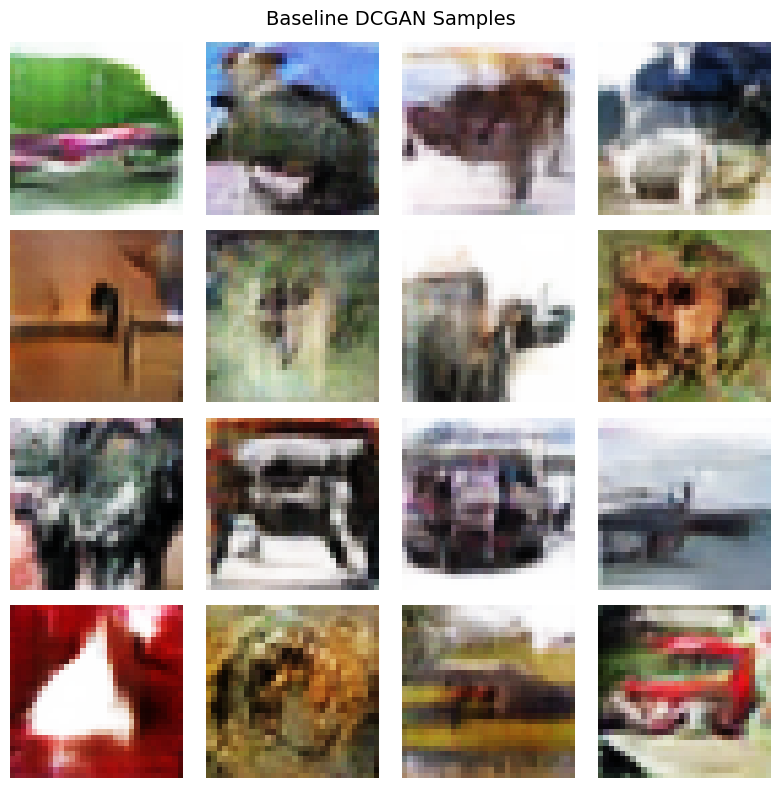

In [25]:
dcgan_noise = tf.random.normal(
    (16, DCGAN_LATENT_DIM),
    seed=SEED
)

dcgan_samples = dcgan_generator(
    dcgan_noise,
    training=False
)

dcgan_samples = denormalise_gan_images(
    dcgan_samples
).numpy()

show_image_grid(
    dcgan_samples,
    rows=4,
    columns=4,
    figure_title="Baseline DCGAN Samples"
)

### 4.1.7 Baseline DCGAN FID Evaluation

The Fréchet Inception Distance (FID) is used to compare the feature distribution of real CIFAR-10 images with the images generated by the DCGAN. A lower FID score means the generated images are closer to the real image distribution.

For a fair comparison with the later models, **5,000 generated images** are used together with **5,000 real validation images**.

In [26]:
# Generate 5,000 DCGAN images for FID evaluation
dcgan_fid_noise = tf.random.normal(
    shape=(
        FID_SAMPLE_SIZE,
        DCGAN_LATENT_DIM
    ),
    seed=SEED
)

dcgan_fid_images = dcgan_generator(
    dcgan_fid_noise,
    training=False
)

# Convert from [-1, 1] to [0, 1]
dcgan_fid_images = denormalise_gan_images(
    dcgan_fid_images
).numpy()

print(
    "Generated DCGAN images:",
    dcgan_fid_images.shape
)

Generated DCGAN images: (5000, 32, 32, 3)


In [27]:
# Extract InceptionV3 features
dcgan_fid_features = extract_fid_features(
    dcgan_fid_images
)

print(
    "Real features:",
    real_fid_features.shape
)

print(
    "Generated features:",
    dcgan_fid_features.shape
)

Real features: (5000, 2048)
Generated features: (5000, 2048)


In [28]:
dcgan_fid = calculate_fid_from_features(
    real_fid_features,
    dcgan_fid_features
)

print(
    f"Baseline DCGAN FID: "
    f"{dcgan_fid:.4f}"
)

Baseline DCGAN FID: 47.7103


### Baseline DCGAN — Model Evaluation Results (FID)

* **Sample quality:** The generated samples contain recognisable **object-like shapes, colours and backgrounds**, showing that the DCGAN learned meaningful visual patterns from CIFAR-10.
* Some samples resemble **vehicles and animals**, while others remain **blurry or ambiguous**, which is expected given the low **32×32 CIFAR-10 resolution**.
* Since DCGAN is **unconditional**, the generated class cannot be controlled. This limits its usefulness when the goal is to generate images from a specific CIFAR-10 class.
* **FID Score: 47.7103** — this provides the quantitative baseline for comparing the later models. A **lower FID is better**, so subsequent experiments will be evaluated based on whether they can reduce this score while maintaining visually recognisable outputs.

**Conclusion:** The baseline DCGAN can generate meaningful CIFAR-10-like images, but it lacks **class control** and some outputs are still unclear. Therefore, the next model uses a **Conditional DCGAN (cDCGAN)** to investigate whether adding class-label information can produce more controlled and class-specific images.


## 4.2 Baseline Conditional DCGAN

### 4.2.1 Building Reusable Conditional DCGAN Models

The Conditional GAN receives both random noise and a class label. This makes it possible to generate images for a requested CIFAR-10 class.

The builder functions are reused later, but each experiment creates fresh model instances with new weights.

In [29]:
def build_cgan_generator(
    latent_dim=100,
    improved=False,
    model_name="cgan_generator"
):
    noise_input = keras.Input(
        shape=(latent_dim,),
        name="noise_input"
    )

    label_input = keras.Input(
        shape=(1,),
        dtype="int32",
        name="label_input"
    )

    label_embedding = layers.Embedding(
        input_dim=NUM_CLASSES,
        output_dim=latent_dim
    )(label_input)

    label_embedding = layers.Flatten()(
        label_embedding
    )

    combined_input = layers.Concatenate()(
        [noise_input, label_embedding]
    )

    x = layers.Dense(
        4 * 4 * 256,
        use_bias=False
    )(combined_input)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Reshape((4, 4, 256))(x)

    first_filters = 256 if improved else 128
    second_filters = 128 if improved else 64

    x = layers.Conv2DTranspose(
        first_filters,
        kernel_size=4,
        strides=2,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2DTranspose(
        second_filters,
        kernel_size=4,
        strides=2,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    if improved:
        x = layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            use_bias=False
        )(x)

        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)

    output = layers.Conv2DTranspose(
        3,
        kernel_size=4,
        strides=2,
        padding="same",
        activation="tanh"
    )(x)

    return keras.Model(
        inputs=[noise_input, label_input],
        outputs=output,
        name=model_name
    )


def build_cgan_discriminator(
    model_name="cgan_discriminator"
):
    image_input = keras.Input(
        shape=IMAGE_SHAPE,
        name="image_input"
    )

    label_input = keras.Input(
        shape=(1,),
        dtype="int32",
        name="label_input"
    )

    label_map = layers.Embedding(
        input_dim=NUM_CLASSES,
        output_dim=32 * 32
    )(label_input)

    label_map = layers.Flatten()(label_map)
    label_map = layers.Reshape((32, 32, 1))(
        label_map
    )

    combined_input = layers.Concatenate(
        axis=-1
    )([image_input, label_map])

    x = layers.Conv2D(
        64,
        kernel_size=4,
        strides=2,
        padding="same"
    )(combined_input)

    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2D(
        128,
        kernel_size=4,
        strides=2,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2D(
        256,
        kernel_size=4,
        strides=2,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Flatten()(x)
    output = layers.Dense(1)(x)

    return keras.Model(
        inputs=[image_input, label_input],
        outputs=output,
        name=model_name
    )

### 4.2.2 Shared Conditional DCGAN Training Functions

The training-step factory creates a separate compiled training function for each experiment. This keeps the code reusable while ensuring that every experiment uses its own models and optimizers.

In [30]:
def create_cgan_train_step(
    generator,
    discriminator,
    generator_optimizer,
    discriminator_optimizer,
    latent_dim,
    real_label_value=1.0
):
    @tf.function(reduce_retracing=True)
    def train_step(real_images, labels):
        batch_size = tf.shape(real_images)[0]

        noise = tf.random.normal(
            (batch_size, latent_dim)
        )

        labels_reshaped = tf.reshape(
            tf.cast(labels, tf.int32),
            (-1, 1)
        )

        with tf.GradientTape() as generator_tape,              tf.GradientTape() as discriminator_tape:

            generated_images = generator(
                [noise, labels_reshaped],
                training=True
            )

            real_output = discriminator(
                [real_images, labels_reshaped],
                training=True
            )

            fake_output = discriminator(
                [generated_images, labels_reshaped],
                training=True
            )

            generator_loss_value = generator_loss(
                fake_output
            )

            discriminator_loss_value = discriminator_loss(
                real_output,
                fake_output,
                real_label_value=real_label_value
            )

        generator_gradients = generator_tape.gradient(
            generator_loss_value,
            generator.trainable_variables
        )

        discriminator_gradients = discriminator_tape.gradient(
            discriminator_loss_value,
            discriminator.trainable_variables
        )

        generator_optimizer.apply_gradients(
            zip(
                generator_gradients,
                generator.trainable_variables
            )
        )

        discriminator_optimizer.apply_gradients(
            zip(
                discriminator_gradients,
                discriminator.trainable_variables
            )
        )

        return (
            generator_loss_value,
            discriminator_loss_value
        )

    return train_step


def train_cgan(
    dataset,
    epochs,
    train_step,
    experiment_name
):
    generator_losses = []
    discriminator_losses = []

    for epoch in range(epochs):
        epoch_generator_losses = []
        epoch_discriminator_losses = []

        for real_images, labels in dataset:
            (
                generator_loss_value,
                discriminator_loss_value
            ) = train_step(
                real_images,
                labels
            )

            epoch_generator_losses.append(
                generator_loss_value
            )

            epoch_discriminator_losses.append(
                discriminator_loss_value
            )

        mean_generator_loss = float(
            tf.reduce_mean(
                epoch_generator_losses
            ).numpy()
        )

        mean_discriminator_loss = float(
            tf.reduce_mean(
                epoch_discriminator_losses
            ).numpy()
        )

        generator_losses.append(
            mean_generator_loss
        )

        discriminator_losses.append(
            mean_discriminator_loss
        )

        print(
            f"{experiment_name} | "
            f"Epoch {epoch + 1}/{epochs} "
            f"- Generator: {mean_generator_loss:.4f} "
            f"- Discriminator: {mean_discriminator_loss:.4f}"
        )

    return generator_losses, discriminator_losses

### 4.2.3 Shared Conditional Image Generation Functions

Exactly 500 images are generated for each class when creating the 5,000-image submission set.

In [31]:
def generate_conditional_images(
    generator,
    latent_dim,
    images_per_class=500,
    seed=SEED
):
    generator_rng = tf.random.Generator.from_seed(
        seed
    )

    generated_images = []
    generated_labels = []

    for class_id in range(NUM_CLASSES):
        noise = generator_rng.normal(
            shape=(
                images_per_class,
                latent_dim
            )
        )

        labels = tf.fill(
            (images_per_class, 1),
            class_id
        )

        labels = tf.cast(
            labels,
            tf.int32
        )

        images = generator(
            [noise, labels],
            training=False
        )

        images = denormalise_gan_images(
            images
        ).numpy()

        generated_images.append(images)

        generated_labels.extend(
            [class_id] * images_per_class
        )

    return (
        np.concatenate(
            generated_images,
            axis=0
        ),
        np.asarray(generated_labels)
    )


def show_generated_images_per_class(
    generator,
    latent_dim,
    images_per_class=3,
    title="Generated Images",
    seed=SEED
):

    generator_rng = tf.random.Generator.from_seed(
        seed
    )

    generated_images = []
    generated_titles = []

    for class_id, class_name in enumerate(
        class_names
    ):

        noise = generator_rng.normal(
            shape=(
                images_per_class,
                latent_dim
            )
        )

        labels = tf.fill(
            (
                images_per_class,
                1
            ),
            class_id
        )

        labels = tf.cast(
            labels,
            tf.int32
        )

        images = generator(
            [noise, labels],
            training=False
        )

        images = denormalise_gan_images(
            images
        ).numpy()

        generated_images.extend(
            images
        )

        generated_titles.extend(
            [class_name] * images_per_class
        )

    generated_images = np.array(
        generated_images
    )

    show_image_grid(
        generated_images,
        titles=generated_titles,
        rows=5,
        columns=6,
        figure_title=title
    )


def save_generated_images(
    images,
    labels,
    output_directory
):
    output_directory = Path(output_directory)

    if output_directory.exists():
        shutil.rmtree(output_directory)

    output_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    for index, (image, label) in enumerate(
        zip(images, labels)
    ):
        class_directory = (
            output_directory
            / f"{label}_{class_names[label]}"
        )

        class_directory.mkdir(
            exist_ok=True
        )

        file_path = (
            class_directory
            / f"{index:04d}.png"
        )

        save_image_array(
            image,
            file_path
        )

    print(
        f"Saved {len(images)} images to "
        f"{output_directory.resolve()}"
    )

### 4.2.4 Creating and Testing the Baseline CDCGAN

The baseline uses a latent dimension of 100, the standard generator and normal real labels of 1.0.

In [32]:
BASELINE_CGAN_LATENT_DIM = 100
BASELINE_CGAN_EPOCHS = BASE_EPOCHS

baseline_cgan_generator = build_cgan_generator(
    latent_dim=BASELINE_CGAN_LATENT_DIM,
    improved=False,
    model_name="baseline_cgan_generator"
)

baseline_cgan_discriminator = build_cgan_discriminator(
    model_name="baseline_cgan_discriminator"
)

baseline_cgan_generator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

baseline_cgan_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

baseline_cgan_train_step = create_cgan_train_step(
    generator=baseline_cgan_generator,
    discriminator=baseline_cgan_discriminator,
    generator_optimizer=baseline_cgan_generator_optimizer,
    discriminator_optimizer=baseline_cgan_discriminator_optimizer,
    latent_dim=BASELINE_CGAN_LATENT_DIM,
    real_label_value=1.0
)

In [33]:
baseline_cgan_generator.summary()

Model: "baseline_cgan_generator"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 label_input (InputLayer)       [(None, 1)]          0           []                               
                                                                                                  
 embedding (Embedding)          (None, 1, 100)       1000        ['label_input[0][0]']            
                                                                                                  
 noise_input (InputLayer)       [(None, 100)]        0           []                               
                                                                                                  
 flatten_1 (Flatten)            (None, 100)          0           ['embedding[0][0]']              
                                                                            

In [34]:
baseline_cgan_discriminator.summary()

Model: "baseline_cgan_discriminator"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 label_input (InputLayer)       [(None, 1)]          0           []                               
                                                                                                  
 embedding_1 (Embedding)        (None, 1, 1024)      10240       ['label_input[0][0]']            
                                                                                                  
 flatten_2 (Flatten)            (None, 1024)         0           ['embedding_1[0][0]']            
                                                                                                  
 image_input (InputLayer)       [(None, 32, 32, 3)]  0           []                               
                                                                        

**Baseline Conditional DCGAN Generator Architecture:**

- **Two inputs:** The generator receives a **100-dimensional noise vector** and a **class label**.
- **Class conditioning:** The class label is converted into a **100-dimensional embedding** and combined with the noise vector. This allows the generator to use both random variation and information about which CIFAR-10 class it should generate.
- **Initial feature representation:** The combined **200-dimensional vector** is expanded through a dense layer and reshaped into a **4 × 4 × 256** feature representation.
- **Upsampling:** Transposed convolution layers progressively increase the spatial dimensions while reducing the number of feature channels.
- **Batch normalization and ReLU:** These are used between the upsampling layers to support more stable training and feature learning.
- **Output:** The final layer produces a **32 × 32 × 3 RGB image**, matching the CIFAR-10 image dimensions.
- **Output activation:** `tanh` produces pixel values between **-1 and 1**, matching the normalization used for the real training images.

**Generator flow:**

**Noise (100) + Class Embedding (100) → 200 → 4 × 4 × 256 → 8 × 8 × 128 → 16 × 16 × 64 → 32 × 32 × 3**

**Baseline Conditional DCGAN Discriminator Architecture:**

- **Two inputs:** The discriminator receives a **32 × 32 × 3 image** together with its **class label**.
- **Class conditioning:** The label is embedded into **1,024 values** and reshaped into a **32 × 32 × 1** feature map.
- **Combining image and label:** The label feature map is concatenated with the RGB image, producing a **32 × 32 × 4** input. This allows the discriminator to evaluate the image together with its class information.
- **Feature extraction:** Convolutional layers progressively reduce the spatial dimensions while increasing the number of feature channels.
- **LeakyReLU:** LeakyReLU activations are used after the convolutional layers to retain gradients for negative inputs during discriminator training.
- **Batch normalization:** Batch normalization is applied in the deeper convolutional layers to support more stable training.
- **Output:** The final features are flattened and passed to a single output neuron to determine whether the image-label combination is real or generated.

**Discriminator flow:**

**Image (32 × 32 × 3) + Label Map (32 × 32 × 1) → 32 × 32 × 4 → 16 × 16 × 64 → 8 × 8 × 128 → 4 × 4 × 256 → 4096 → 1**

### 4.2.5 Training and Evaluating the Baseline Conditional DCGAN

In [35]:
(
    baseline_cgan_generator_losses,
    baseline_cgan_discriminator_losses
) = train_cgan(
    dataset=cgan_dataset,
    epochs=BASELINE_CGAN_EPOCHS,
    train_step=baseline_cgan_train_step,
    experiment_name="Baseline CGAN"
)

Baseline CGAN | Epoch 1/50 - Generator: 3.9576 - Discriminator: 0.1323
Baseline CGAN | Epoch 2/50 - Generator: 3.7366 - Discriminator: 0.2372
Baseline CGAN | Epoch 3/50 - Generator: 3.1789 - Discriminator: 0.2589
Baseline CGAN | Epoch 4/50 - Generator: 3.0394 - Discriminator: 0.3362
Baseline CGAN | Epoch 5/50 - Generator: 2.8366 - Discriminator: 0.3327
Baseline CGAN | Epoch 6/50 - Generator: 2.9152 - Discriminator: 0.3631
Baseline CGAN | Epoch 7/50 - Generator: 2.9922 - Discriminator: 0.3546
Baseline CGAN | Epoch 8/50 - Generator: 2.8402 - Discriminator: 0.3160
Baseline CGAN | Epoch 9/50 - Generator: 2.8754 - Discriminator: 0.4086
Baseline CGAN | Epoch 10/50 - Generator: 3.0106 - Discriminator: 0.3484
Baseline CGAN | Epoch 11/50 - Generator: 2.8039 - Discriminator: 0.3825
Baseline CGAN | Epoch 12/50 - Generator: 2.6510 - Discriminator: 0.3793
Baseline CGAN | Epoch 13/50 - Generator: 2.5588 - Discriminator: 0.4427
Baseline CGAN | Epoch 14/50 - Generator: 2.4426 - Discriminator: 0.4898
B

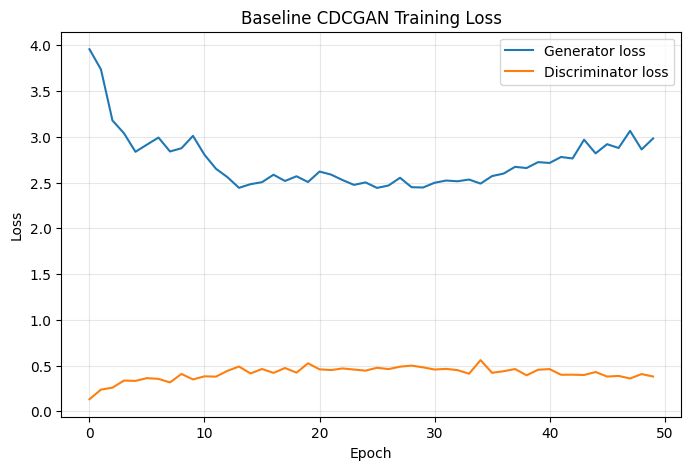

In [36]:
plot_training_losses(
    baseline_cgan_generator_losses,
    baseline_cgan_discriminator_losses,
    "Baseline CDCGAN Training Loss"
)

### Baseline Conditional GAN — Model Training Results

* **Generator loss:** decreased from **3.9576** to its lowest region of around **2.44–2.50** between epochs 14–30, showing that the generator initially improved.
* **Discriminator loss:** increased from **0.1323** and generally stabilised around **0.4–0.5**, indicating that generated images became more challenging for the discriminator to distinguish.
* **Most stable period:** approximately **epochs 14–33**, where both losses remained relatively steady with only small fluctuations.
* **Later epochs:** after around epoch 35, generator loss gradually increased, reaching **2.9825** at epoch 50, while discriminator loss decreased to **0.3804**.
* This suggests the **discriminator began gaining an advantage again** toward the end of training, so the GAN was becoming less balanced.

**Conclusion:** The baseline Conditional GAN successfully trained and incorporated **class-label conditioning**, allowing class-specific generation. However, the increasing generator loss in the later epochs suggests that the generator could be improved further. This baseline therefore provides the starting point for the following cGAN experiments, where modifications are tested to improve generation quality and training behaviour.


### Baseline cDCGAN: Samples

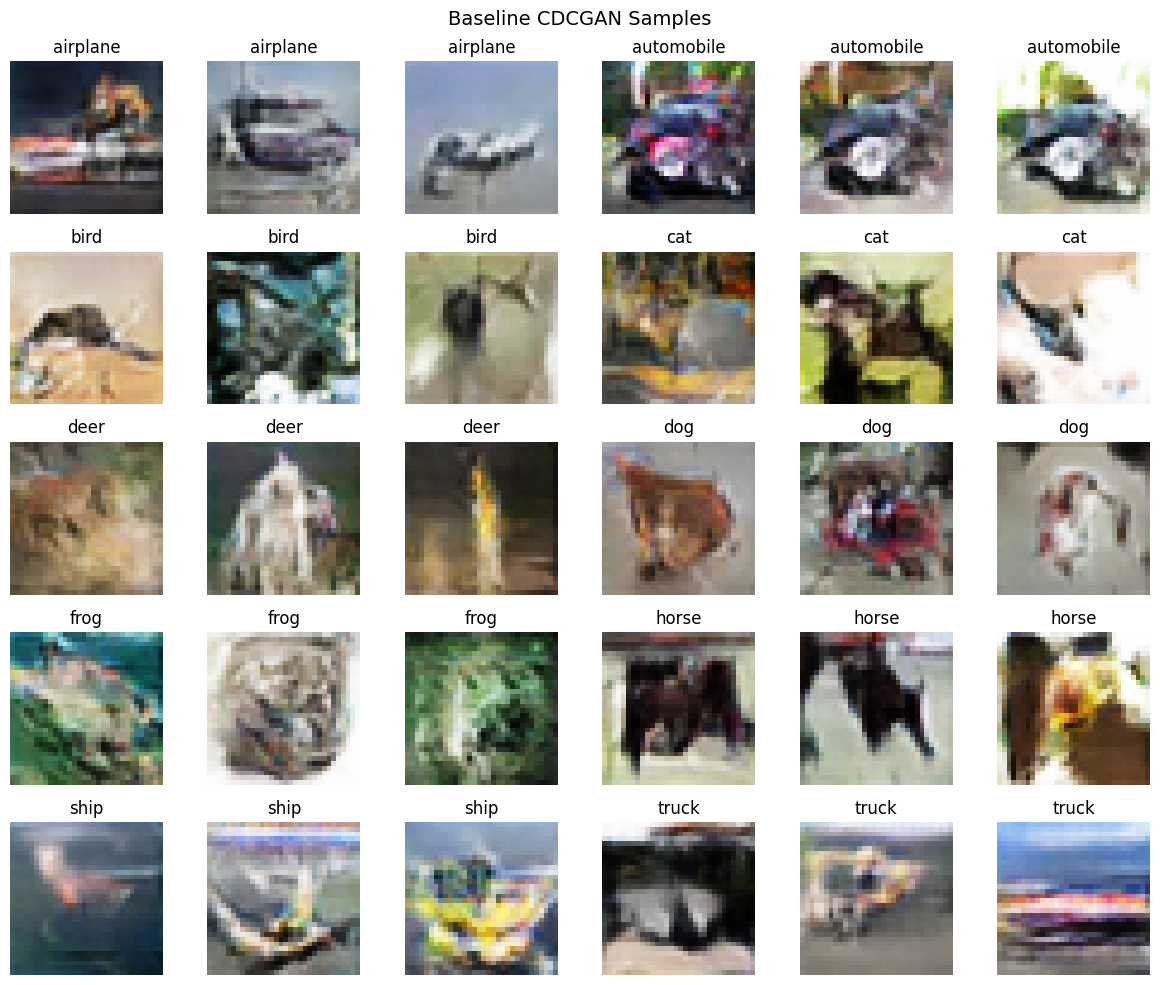

In [37]:
(
    baseline_generated_images,
    baseline_generated_labels
) = generate_conditional_images(
    baseline_cgan_generator,
    BASELINE_CGAN_LATENT_DIM,
    images_per_class=500,
    seed=SEED
)

baseline_cgan_generator.save_weights(
    OUTPUT_ROOT
    / "baseline_cgan_generator.weights.h5"
)

show_generated_images_per_class(
    generator=baseline_cgan_generator,
    latent_dim=BASELINE_CGAN_LATENT_DIM,
    images_per_class=3,
    title="Baseline CDCGAN Samples"
)

### Baseline cDCGAN: FID Score

In [38]:
baseline_generated_features = extract_fid_features(
    baseline_generated_images
)

baseline_cgan_fid = calculate_fid_from_features(
    real_fid_features,
    baseline_generated_features
)

print(
    f"Baseline CDCGAN FID: "
    f"{baseline_cgan_fid:.4f}"
)

Baseline CDCGAN FID: 55.1430


### Baseline Conditional DCGAN — Model Evaluation Results (FID)

* **Sample quality:** The model generates images with visible **class-related features**. Several automobiles, airplanes and animal-like shapes can be recognised from the samples.
* **Class conditioning:** Unlike the DCGAN, the model can generate images according to a **specified CIFAR-10 class**, confirming that the conditioning mechanism is working.
* **Limitations:** Image quality is inconsistent. Some samples match their requested classes reasonably well, while others are **blurry, distorted or difficult to recognise**.
* **FID Score: 55.1430** — this is **higher than the DCGAN's 47.7103**, meaning the baseline conditional model has worse overall distributional similarity to the real images according to FID.
* However, the cGAN provides an important capability that DCGAN does not: **controlled class-specific generation**. Therefore, the higher FID does not mean that conditioning failed.

**Conclusion:** The baseline cGAN successfully introduces **class control**, but its FID score and visual quality show that conditioning alone does not automatically improve image quality. 

## 4.3 Baseline Variational Autoencoder

### 4.3.1 Building the VAE

The VAE provides a different baseline because it reconstructs images through a probabilistic latent space instead of using adversarial training.

In [39]:
VAE_LATENT_DIM = 128
VAE_EPOCHS = BASE_EPOCHS


class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_variance = inputs

        batch_size = tf.shape(z_mean)[0]
        latent_size = tf.shape(z_mean)[1]

        epsilon = tf.random.normal(
            shape=(batch_size, latent_size)
        )

        return (
            z_mean
            + tf.exp(0.5 * z_log_variance)
            * epsilon
        )


def build_vae_encoder(
    latent_dim=VAE_LATENT_DIM
):
    inputs = keras.Input(
        shape=IMAGE_SHAPE
    )

    x = layers.Conv2D(
        32,
        kernel_size=3,
        strides=2,
        padding="same",
        activation="relu"
    )(inputs)

    x = layers.Conv2D(
        64,
        kernel_size=3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)

    z_mean = layers.Dense(
        latent_dim,
        name="z_mean"
    )(x)

    z_log_variance = layers.Dense(
        latent_dim,
        name="z_log_variance"
    )(x)

    z = Sampling()(
        [z_mean, z_log_variance]
    )

    return keras.Model(
        inputs,
        [z_mean, z_log_variance, z],
        name="vae_encoder"
    )


def build_vae_decoder(
    latent_dim=VAE_LATENT_DIM
):
    latent_inputs = keras.Input(
        shape=(latent_dim,)
    )

    x = layers.Dense(
        8 * 8 * 64,
        activation="relu"
    )(latent_inputs)

    x = layers.Reshape((8, 8, 64))(x)

    x = layers.Conv2DTranspose(
        64,
        kernel_size=3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    x = layers.Conv2DTranspose(
        32,
        kernel_size=3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    outputs = layers.Conv2D(
        3,
        kernel_size=3,
        padding="same",
        activation="sigmoid"
    )(x)

    return keras.Model(
        latent_inputs,
        outputs,
        name="vae_decoder"
    )


class VAE(keras.Model):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = keras.metrics.Mean(
            name="total_loss"
        )

        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )

        self.kl_loss_tracker = keras.metrics.Mean(
            name="kl_loss"
        )

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            (
                z_mean,
                z_log_variance,
                z
            ) = self.encoder(
                data,
                training=True
            )

            reconstruction = self.decoder(
                z,
                training=True
            )

            pixel_loss = keras.losses.binary_crossentropy(
                data,
                reconstruction
            )

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    pixel_loss,
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1
                    + z_log_variance
                    - tf.square(z_mean)
                    - tf.exp(z_log_variance),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_weights
            )
        )

        self.total_loss_tracker.update_state(
            total_loss
        )

        self.reconstruction_loss_tracker.update_state(
            reconstruction_loss
        )

        self.kl_loss_tracker.update_state(
            kl_loss
        )

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": (
                self.reconstruction_loss_tracker.result()
            ),
            "kl_loss": self.kl_loss_tracker.result()
        }


vae_encoder = build_vae_encoder()
vae_decoder = build_vae_decoder()

vae = VAE(
    vae_encoder,
    vae_decoder
)

vae.compile(
    optimizer=keras.optimizers.Adam()
)

vae_encoder.summary()
vae_decoder.summary()

Model: "vae_encoder"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_4 (InputLayer)           [(None, 32, 32, 3)]  0           []                               
                                                                                                  
 conv2d_100 (Conv2D)            (None, 16, 16, 32)   896         ['input_4[0][0]']                
                                                                                                  
 conv2d_101 (Conv2D)            (None, 8, 8, 64)     18496       ['conv2d_100[0][0]']             
                                                                                                  
 flatten_4 (Flatten)            (None, 4096)         0           ['conv2d_101[0][0]']             
                                                                                        

**VAE Encoder Architecture:**

- **Input:** The encoder receives a **32 × 32 × 3 RGB CIFAR-10 image**.
- **Feature extraction:** Two convolutional layers progressively reduce the image from **32 × 32 × 3 → 16 × 16 × 32 → 8 × 8 × 64**, allowing the encoder to extract important visual features while reducing spatial dimensions.
- **Feature representation:** The **8 × 8 × 64** output is flattened into **4,096 features** and reduced to a **256-dimensional representation**.
- **Latent representation:** Two separate dense layers produce `z_mean` and `z_log_variance`, each containing **128 values**. These describe the distribution of the image in the latent space.
- **Sampling:** The Sampling layer uses `z_mean` and `z_log_variance` to generate a **128-dimensional latent vector** that is passed to the decoder.

**Encoder flow:**

**32 × 32 × 3 → 16 × 16 × 32 → 8 × 8 × 64 → 4096 → 256 → 128-dimensional latent space**

**VAE Decoder Architecture:**

- **Input:** The decoder receives the sampled **128-dimensional latent vector** from the encoder.
- **Feature expansion:** A dense layer expands the latent vector into **4,096 values**, which are reshaped into an **8 × 8 × 64** feature representation.
- **Upsampling:** Transposed convolution layers progressively increase the spatial dimensions from **8 × 8 × 64 → 16 × 16 × 64 → 32 × 32 × 32**.
- **Image reconstruction:** The final convolutional layer produces a **32 × 32 × 3 RGB image**, matching the original CIFAR-10 image dimensions.

**Decoder flow:**

**128 → 8 × 8 × 64 → 16 × 16 × 64 → 32 × 32 × 32 → 32 × 32 × 3**

### 4.3.2 Training and Evaluating the VAE

In [40]:
vae_dataset = create_dataset(
    x_train_vae,
    labels=None
)

vae_history = vae.fit(
    vae_dataset,
    epochs=VAE_EPOCHS
)

Epoch 1/50
351/351 [==============================] - 6s 14ms/step - loss: 686.6487 - reconstruction_loss: 662.7094 - kl_loss: 7.2978
Epoch 2/50
351/351 [==============================] - 5s 14ms/step - loss: 651.7802 - reconstruction_loss: 636.6064 - kl_loss: 12.6806
Epoch 3/50
351/351 [==============================] - 5s 14ms/step - loss: 641.9754 - reconstruction_loss: 625.9141 - kl_loss: 13.7092
Epoch 4/50
351/351 [==============================] - 5s 14ms/step - loss: 635.8587 - reconstruction_loss: 620.9739 - kl_loss: 13.9422
Epoch 5/50
351/351 [==============================] - 5s 14ms/step - loss: 633.2694 - reconstruction_loss: 618.2519 - kl_loss: 14.5466
Epoch 6/50
351/351 [==============================] - 5s 14ms/step - loss: 631.8753 - reconstruction_loss: 616.3894 - kl_loss: 15.1087
Epoch 7/50
351/351 [==============================] - 5s 14ms/step - loss: 631.2023 - reconstruction_loss: 615.1686 - kl_loss: 15.3546
Epoch 8/50
351/351 [==============================] - 5s

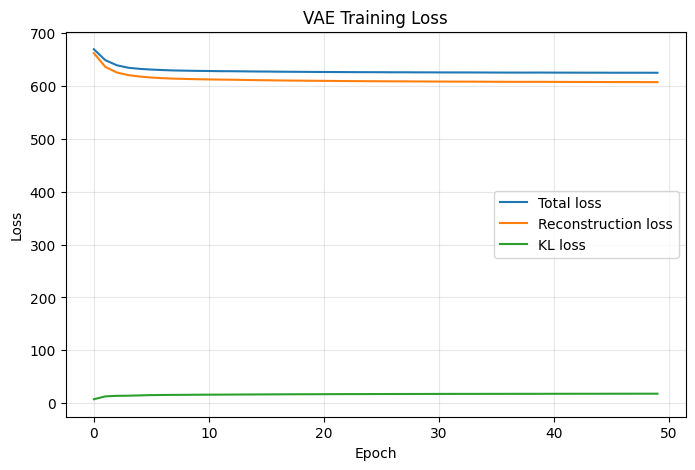

In [80]:
plt.figure(figsize=(8, 5))
plt.plot(
    vae_history.history["loss"],
    label="Total loss"
)
plt.plot(
    vae_history.history["reconstruction_loss"],
    label="Reconstruction loss"
)
plt.plot(
    vae_history.history["kl_loss"],
    label="KL loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Baseline VAE — Model Training Results

* **Total loss:** decreased sharply during the first few epochs, from about **686.65** at Epoch 1 to around **630** by Epoch 8–10, showing that the VAE learned the main image structure quickly.
* **Reconstruction loss:** also decreased steadily from **662.71** to **607.70** by Epoch 50, indicating gradual improvement in how well the decoder reconstructed the input images.
* **KL loss:** increased from **7.30** to about **17.75**. This means the latent distribution became more structured and regularised as training progressed.
* **Training behaviour:** after roughly **10–15 epochs**, all three loss components changed much more slowly, showing that the model had largely converged.
* **Later epochs:** only small improvements were observed after the middle of training, so additional epochs produced diminishing returns rather than major gains.

**Conclusion:** The VAE trained stably and converged smoothly. Most of the improvement occurred early, while later epochs mainly refined the reconstructions and latent representation rather than producing large further reductions in total loss.


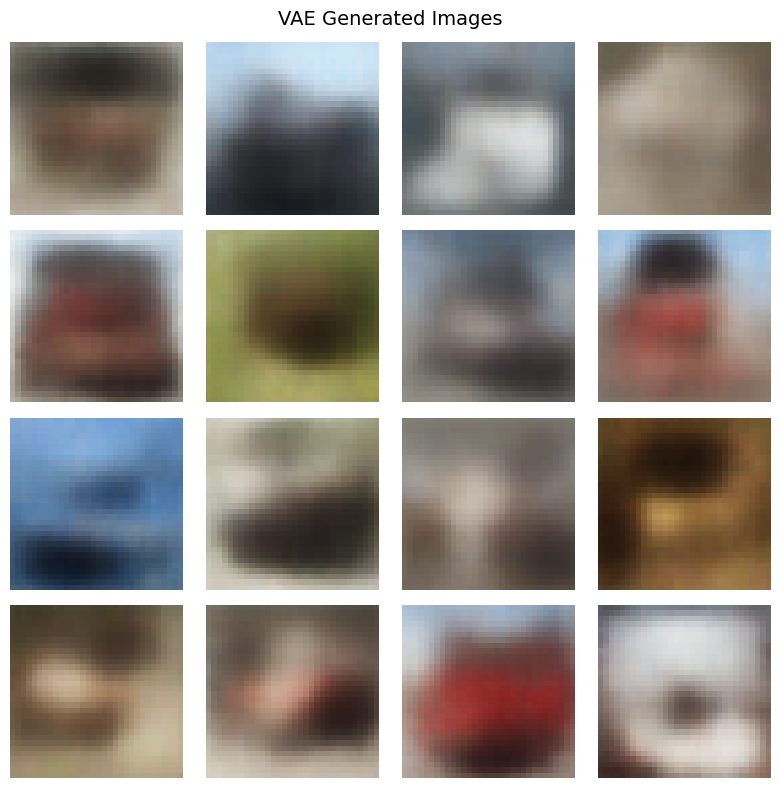

In [81]:
vae.save_weights(
    OUTPUT_ROOT / "vae.weights.h5"
)

vae_noise = tf.random.normal(
    (16, VAE_LATENT_DIM),
    seed=SEED
)

vae_generated_images = vae_decoder(
    vae_noise,
    training=False
).numpy()

show_image_grid(
    vae_generated_images,
    rows=4,
    columns=4,
    figure_title="VAE Generated Images"
)

### 4.3.3 VAE Reconstruction MAE

Since the VAE learns to reconstruct input images, Mean Absolute Error (MAE) is used to measure the average pixel difference between the original validation images and their reconstructed versions.

For a consistent evaluation, the latent mean (`z_mean`) is used for reconstruction instead of a randomly sampled latent vector. A **lower MAE** indicates that the reconstructed images are closer to the original images.

In [42]:
# Prepare validation images
vae_eval_images = (
    x_validation.astype("float32")
    / 255.0
)

# Encode validation images
z_mean, z_log_variance, z = vae_encoder.predict(
    vae_eval_images,
    batch_size=128
)

# Reconstruct the same images
vae_reconstructed_images = vae_decoder.predict(
    z_mean,
    batch_size=128
)

# Calculate MAE
vae_mae = np.mean(
    np.abs(
        vae_eval_images
        - vae_reconstructed_images
    )
)

print(
    f"VAE Reconstruction MAE: "
    f"{vae_mae:.4f}"
)

40/40 [==============================] - 0s 6ms/step
VAE Reconstruction MAE: 0.0928


### 4.3.4 VAE FID Evaluation

In [43]:
# VAE FID Evaluation
# Generate 5,000 images in smaller batches to avoid GPU OOM

VAE_FID_BATCH_SIZE = 100

vae_fid_noise = tf.random.normal(
    shape=(
        FID_SAMPLE_SIZE,
        VAE_LATENT_DIM
    ),
    seed=SEED
)

vae_fid_image_batches = []

for start_index in range(
    0,
    FID_SAMPLE_SIZE,
    VAE_FID_BATCH_SIZE
):

    end_index = min(
        start_index + VAE_FID_BATCH_SIZE,
        FID_SAMPLE_SIZE
    )

    noise_batch = vae_fid_noise[
        start_index:end_index
    ]

    generated_batch = vae_decoder(
        noise_batch,
        training=False
    )

    vae_fid_image_batches.append(
        generated_batch.numpy()
    )

vae_fid_images = np.concatenate(
    vae_fid_image_batches,
    axis=0
)

print(
    "VAE generated images:",
    vae_fid_images.shape
)

vae_fid_features = extract_fid_features(
    vae_fid_images
)

print(
    "VAE generated features:",
    vae_fid_features.shape
)

vae_fid = calculate_fid_from_features(
    real_fid_features,
    vae_fid_features
)

print(
    f"Baseline VAE FID: "
    f"{vae_fid:.4f}"
)

VAE generated images: (5000, 32, 32, 3)
VAE generated features: (5000, 2048)
Baseline VAE FID: 204.4845


### Baseline VAE — Model Evaluation Results (FID & MAE)

* **Generated samples:** The VAE captures the general **colours, backgrounds and rough shapes** of CIFAR-10 images, but most outputs are noticeably **smooth and blurry**. A few samples suggest recognisable objects such as vehicles, but fine details and object boundaries are weak.
* **Reconstruction MAE = 0.0928:** The relatively small reconstruction error shows that the VAE can reconstruct the overall visual information of the input images reasonably well. However, a low reconstruction error does **not necessarily mean sharp generated images**, which is consistent with the blurry samples observed.
* **FID = 204.4845:** This is a **high FID score**, indicating a large difference between the distribution of the 5,000 generated images and the real CIFAR-10 images.
* **Overall:** The VAE demonstrates **stable reconstruction and latent-space learning**, but its generated image quality is considerably limited by blurriness and lack of fine detail. This makes it less suitable when the main objective is producing realistic and visually clear CIFAR-10 images.


## 4.4 Comparison of Baseline Models

The three baseline models are compared before selecting one for further experimentation. Since all three models can generate new images, **FID is used as the main common metric**, where a lower score indicates that the generated image distribution is closer to the real CIFAR-10 distribution.

The VAE is additionally evaluated using **reconstruction MAE**, since unlike the GAN models, it also learns to encode and reconstruct input images.

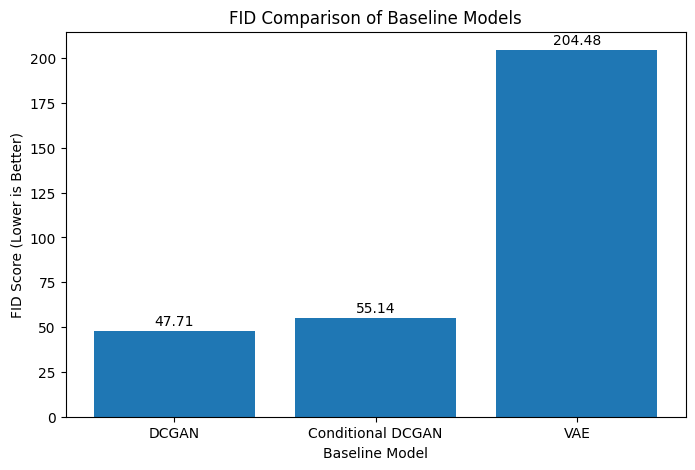

In [44]:
baseline_model_names = [
    "DCGAN",
    "Conditional DCGAN",
    "VAE"
]

baseline_fid_scores = [
    dcgan_fid,
    baseline_cgan_fid,
    vae_fid
]

plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    baseline_model_names,
    baseline_fid_scores
)

plt.title(
    "FID Comparison of Baseline Models"
)

plt.xlabel(
    "Baseline Model"
)

plt.ylabel(
    "FID Score (Lower is Better)"
)

for bar, score in zip(
    bars,
    baseline_fid_scores
):
    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height() + 3,
        f"{score:.2f}",
        ha="center"
    )

plt.show()

# Baseline Model Comparison and Final Model Selection

* **DCGAN — FID: 47.71**

  * Achieved the **lowest FID**, indicating the closest overall distribution to the real CIFAR-10 images.
  * Generated images showed recognisable structures and relatively good visual quality.
  * However, DCGAN is **unconditional**, so it cannot control which CIFAR-10 class is generated.


* **Conditional DCGAN — FID: 55.14**

  * FID is slightly worse than DCGAN, but still **far better than the VAE**.
  * Unlike DCGAN, it allows generation based on a **specified class label**.
  * This is important for the project because individual CIFAR-10 classes can be generated and evaluated separately.


* **VAE — FID: 204.48**

  * Produced by far the **highest FID**.
  * Generated images were noticeably blurry with weaker object details.
  * Although the VAE trained stably, its generation quality was substantially weaker than both GAN models.

# Final Baseline Model Selected: Conditional DCGAN (cDCGAN)

Although **DCGAN achieved the best FID (47.71)**, the **Conditional DCGAN was selected for further experimentation** because it provides class-controlled generation while maintaining much better image quality than the VAE.

This also allows later experiments to investigate whether modifications can **improve the Conditional DCGAN's initial FID of 55.14 while preserving its ability to generate all 10 CIFAR-10 classes**.

**Therefore, Conditional DCGAN provides the best starting point for further experiments because it balances image quality with class control, rather than being selected purely based on the lowest FID.**

# 5. Experiment 1: Increasing the Latent Dimension

## 5.1 What Was Changed

The baseline CDCCGAN uses a latent dimension of 100. Experiment 1 increases it to 128 while keeping the standard generator, discriminator and loss settings unchanged.

This tests whether a slightly larger random input gives the generator enough extra capacity to produce more varied or clearer images.

In [45]:
EXP1_LATENT_DIM = 128
EXP1_EPOCHS = BASE_EPOCHS

exp1_generator = build_cgan_generator(
    latent_dim=EXP1_LATENT_DIM,
    improved=False,
    model_name="exp1_generator"
)

exp1_discriminator = build_cgan_discriminator(
    model_name="exp1_discriminator"
)

exp1_generator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

exp1_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

exp1_train_step = create_cgan_train_step(
    generator=exp1_generator,
    discriminator=exp1_discriminator,
    generator_optimizer=exp1_generator_optimizer,
    discriminator_optimizer=exp1_discriminator_optimizer,
    latent_dim=EXP1_LATENT_DIM,
    real_label_value=1.0
)

## 5.2 Testing, Training and Evaluating Experiment 1

In [46]:
(
    exp1_generator_losses,
    exp1_discriminator_losses
) = train_cgan(
    dataset=cgan_dataset,
    epochs=EXP1_EPOCHS,
    train_step=exp1_train_step,
    experiment_name="Experiment 1"
)

Experiment 1 | Epoch 1/50 - Generator: 4.1518 - Discriminator: 0.1206
Experiment 1 | Epoch 2/50 - Generator: 3.8011 - Discriminator: 0.2053
Experiment 1 | Epoch 3/50 - Generator: 3.3680 - Discriminator: 0.2566
Experiment 1 | Epoch 4/50 - Generator: 3.2915 - Discriminator: 0.2458
Experiment 1 | Epoch 5/50 - Generator: 3.1461 - Discriminator: 0.3361
Experiment 1 | Epoch 6/50 - Generator: 3.0706 - Discriminator: 0.3169
Experiment 1 | Epoch 7/50 - Generator: 3.2665 - Discriminator: 0.2482
Experiment 1 | Epoch 8/50 - Generator: 3.2017 - Discriminator: 0.2579
Experiment 1 | Epoch 9/50 - Generator: 3.2382 - Discriminator: 0.2955
Experiment 1 | Epoch 10/50 - Generator: 3.1154 - Discriminator: 0.3165
Experiment 1 | Epoch 11/50 - Generator: 3.2773 - Discriminator: 0.3055
Experiment 1 | Epoch 12/50 - Generator: 3.2967 - Discriminator: 0.2466
Experiment 1 | Epoch 13/50 - Generator: 3.3703 - Discriminator: 0.3175
Experiment 1 | Epoch 14/50 - Generator: 3.3868 - Discriminator: 0.2314
Experiment 1 | 

### Experiment 1: Training Loss

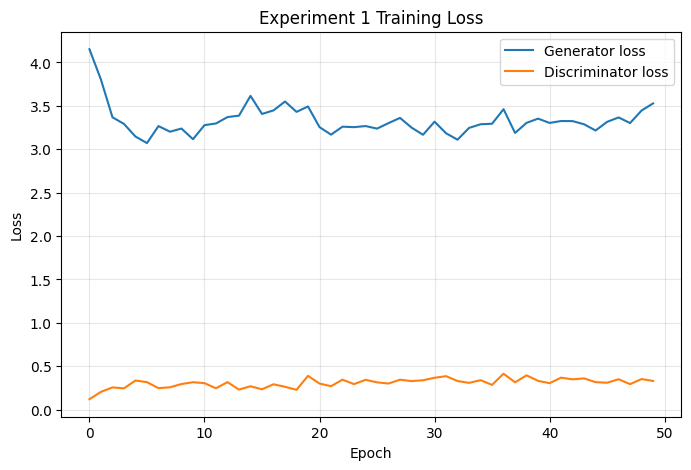

In [47]:
plot_training_losses(
    exp1_generator_losses,
    exp1_discriminator_losses,
    "Experiment 1 Training Loss"
)

### Experiment 1 — Model Training Results

* **Generator loss:** decreased quickly from **4.1518** to around **3.1** during the early epochs, showing initial learning. However, it then remained relatively high at around **3.1–3.5** and ended at **3.5277**.
* **Discriminator loss:** remained very low throughout training, mostly around **0.2–0.4**, ending at **0.3313**.
* **Loss balance:** the large gap between generator and discriminator losses suggests that the **discriminator was considerably stronger than the generator**.
* **Training behaviour:** after the initial improvement, the generator loss did not continue decreasing and fluctuated without a clear downward trend.
* **Overall:** Experiment 1 appears **imbalanced in favour of the discriminator**. The generator struggled to fool the discriminator consistently, suggesting that this modification did not improve the adversarial training balance compared with the baseline.

**Conclusion:** Experiment 1 did not produce the intended improvement in training behaviour. The strong discriminator may have provided less useful learning opportunity for the generator, so the next experiment should aim for a **better balance between the generator and discriminator**.


### Experiment 1: Samples

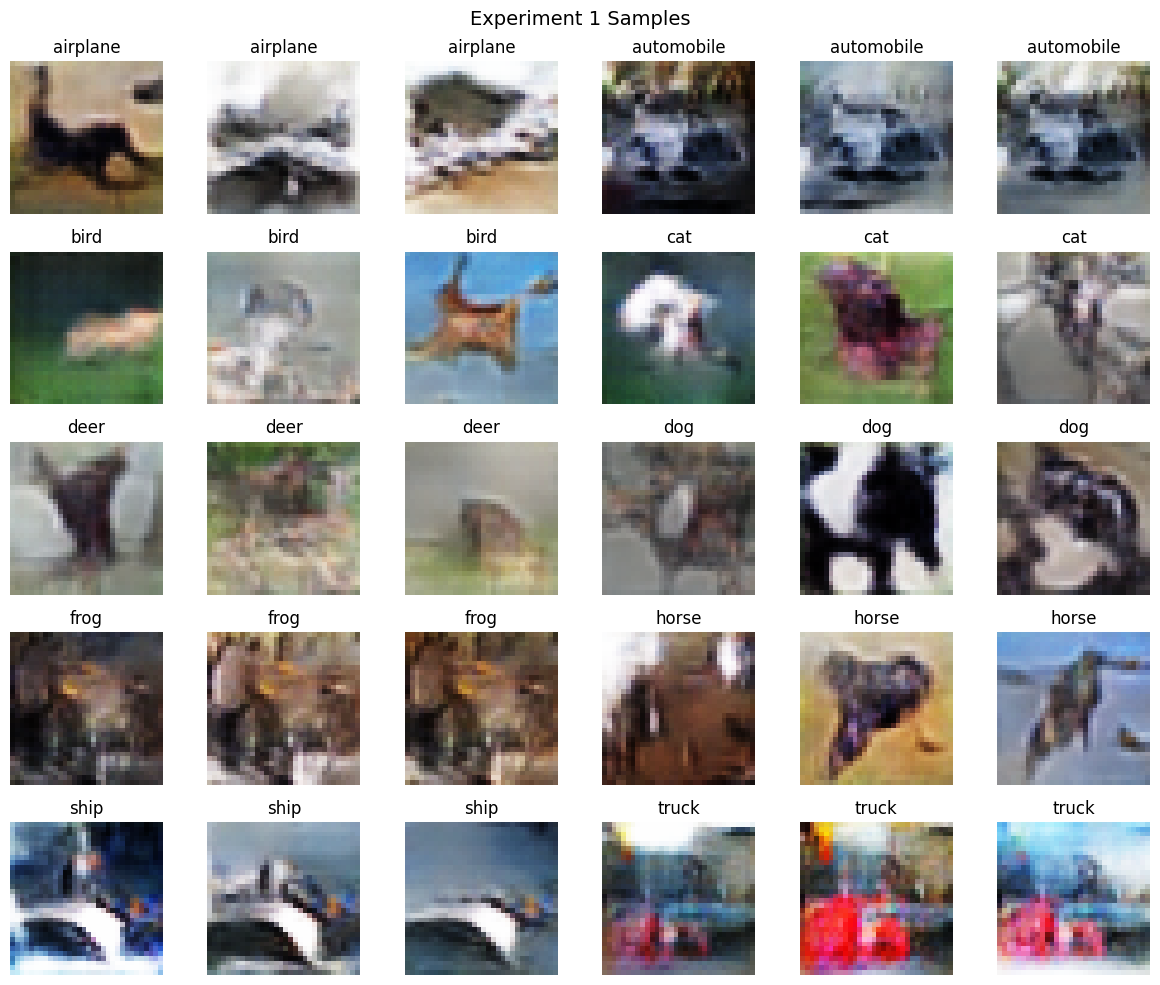

In [48]:
exp1_generator.save_weights(
    OUTPUT_ROOT / "exp1_generator.weights.h5"
)

show_generated_images_per_class(
    generator=exp1_generator,
    latent_dim=EXP1_LATENT_DIM,
    images_per_class=3,
    title="Experiment 1 Samples"
)

### Experiment 1: FID Score

In [49]:
(
    exp1_generated_images,
    exp1_generated_labels
) = generate_conditional_images(
    exp1_generator,
    EXP1_LATENT_DIM,
    images_per_class=500,
    seed=SEED
)

exp1_generated_features = extract_fid_features(
    exp1_generated_images
)

exp1_fid = calculate_fid_from_features(
    real_fid_features,
    exp1_generated_features
)

print(f"Experiment 1 FID: {exp1_fid:.4f}")

Experiment 1 FID: 79.9207


### Experiment 1 — Model Evaluation Results (FID)

* **Generated samples:** Some images show recognisable class features, especially for **automobiles and ships**, while several animal classes remain blurry or difficult to identify.
* **FID score:** Experiment 1 achieved an FID of **79.9207**, compared with **55.1430** for the baseline Conditional DCGAN.
* Since **lower FID is better**, the increase of **24.7777** indicates that Experiment 1 performed **worse than the baseline** in terms of similarity to the real CIFAR-10 image distribution.
* **Overall:** The modification in Experiment 1 did not improve the model as expected. Although class-specific characteristics are visible in some generated images, the higher FID suggests that the overall generated image quality became less realistic compared with the baseline.


| **Model / Change**                                            |   **FID ↓** |
| ------------------------------------------------------------- | ----------: |
| **Baseline Conditional DCGAN**                                |     55.1430 |
| Experiment 1 — Latent Dimension Increased                |     79.9207 |


### Experiment 1: Generating 20 images for each class

In [50]:
# Generate 20 images for each CIFAR-10 class
(
    exp1_20_images,
    exp1_20_labels
) = generate_conditional_images(
    generator=exp1_generator,
    latent_dim=EXP1_LATENT_DIM,
    images_per_class=20,
    seed=2026
)

print("Generated images shape:", exp1_20_images.shape)
print("Generated labels shape:", exp1_20_labels.shape)

print(
    "Images per class:",
    np.bincount(
        exp1_20_labels,
        minlength=NUM_CLASSES
    )
)

Generated images shape: (200, 32, 32, 3)
Generated labels shape: (200,)
Images per class: [20 20 20 20 20 20 20 20 20 20]


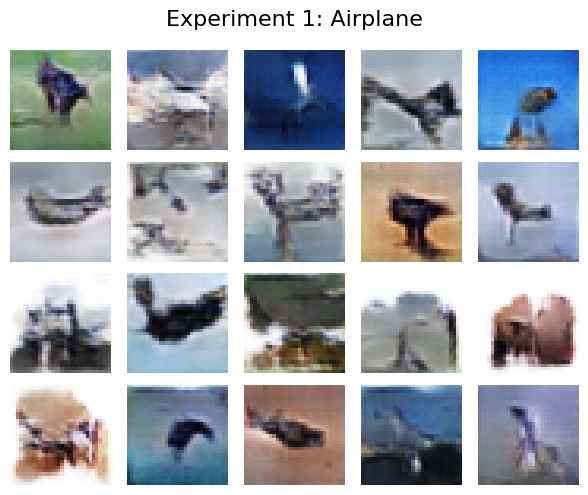

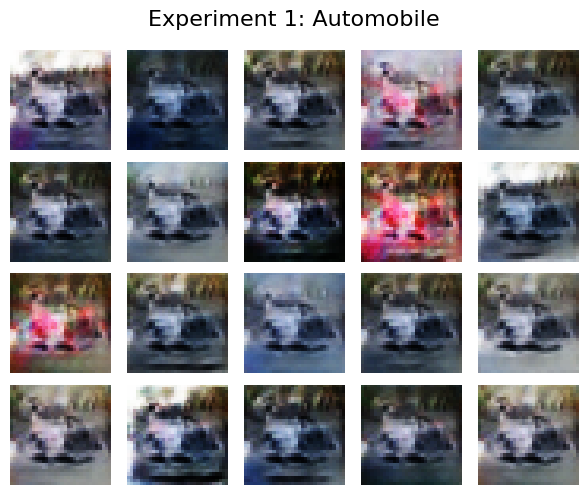

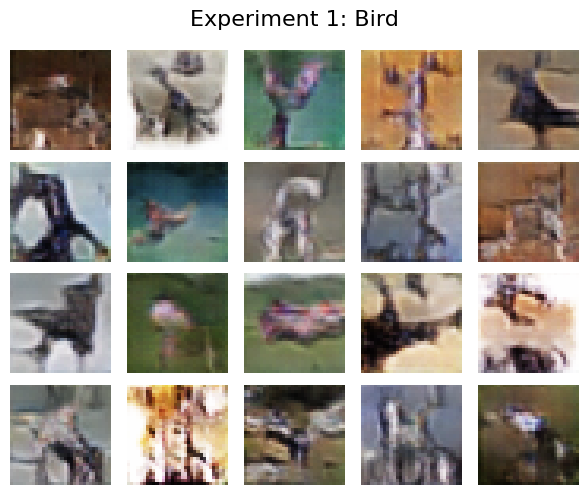

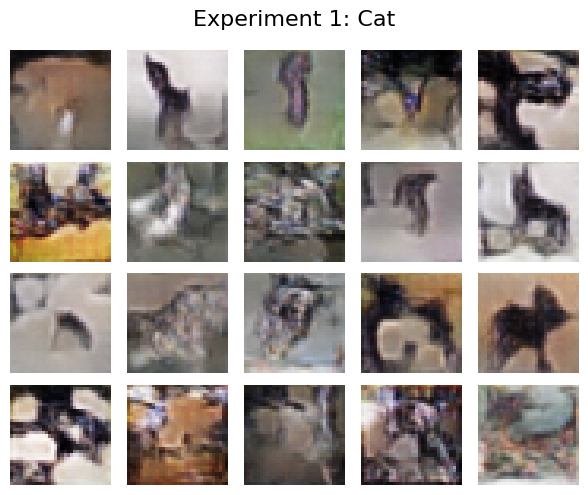

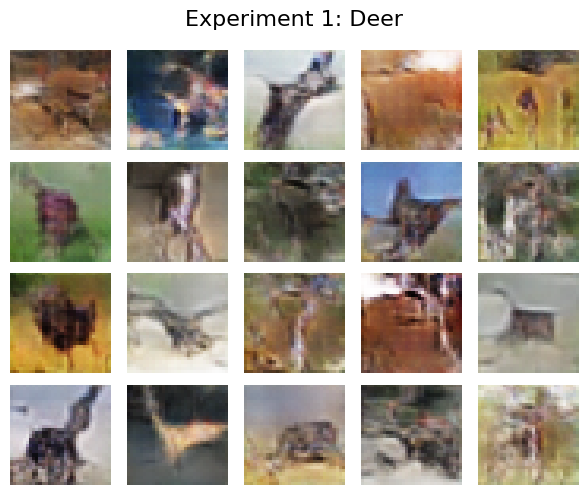

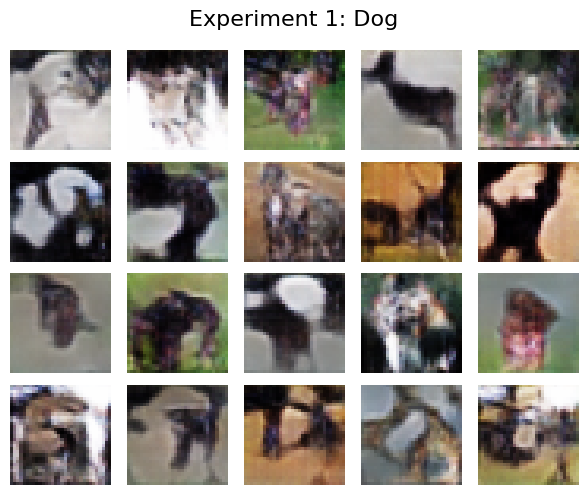

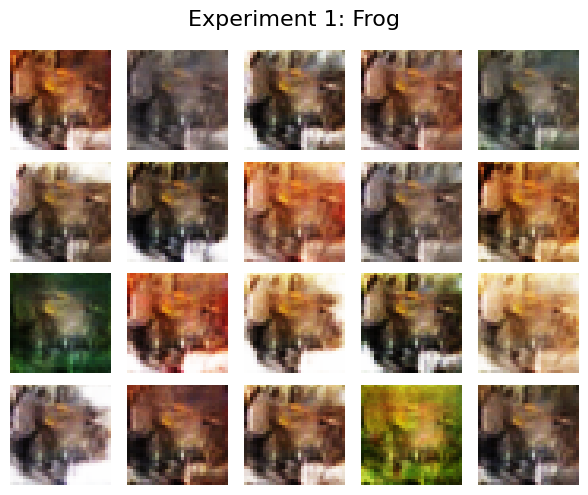

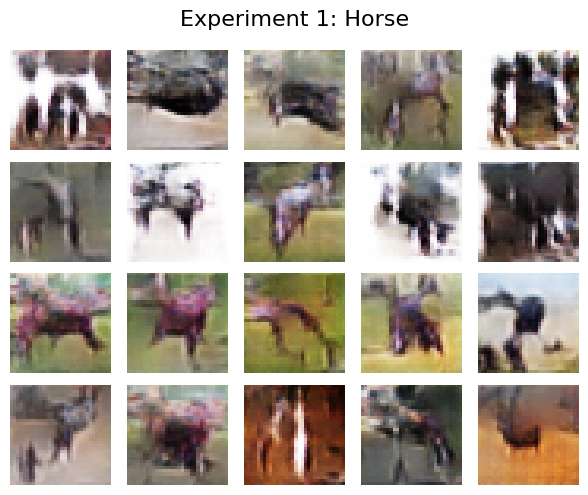

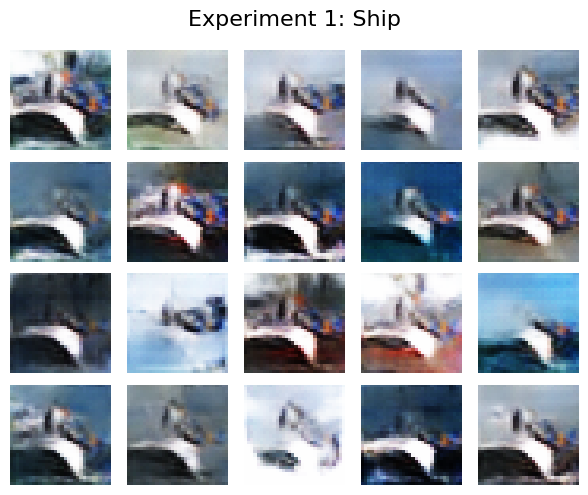

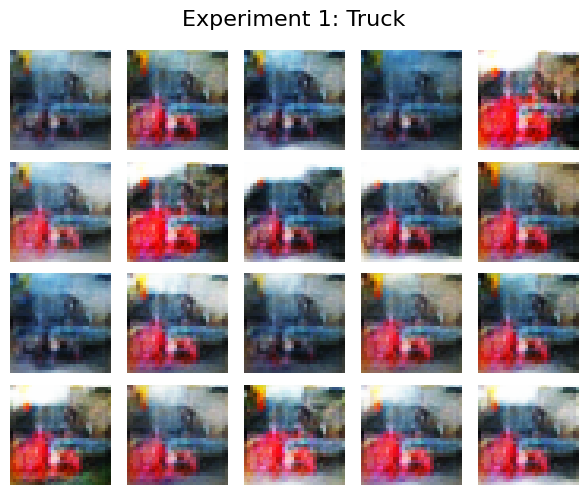

Saved 10 class grids to: C:\Users\User\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\experiment_1_grids


In [51]:
# Folder for the 10 grid images
exp1_grid_directory = (
    OUTPUT_ROOT / "experiment_1_grids"
)

exp1_grid_directory.mkdir(
    parents=True,
    exist_ok=True
)

for class_id, class_name in enumerate(class_names):

    # Select the 20 generated images belonging to this class
    class_images = exp1_20_images[
        exp1_20_labels == class_id
    ]

    # Create a 4 × 5 grid
    figure, axes = plt.subplots(
        4,
        5,
        figsize=(6, 5)
    )

    for image_index, axis in enumerate(
        axes.flatten()
    ):
        axis.imshow(
            np.clip(
                class_images[image_index],
                0.0,
                1.0
            )
        )

        axis.axis("off")

    figure.suptitle(
        f"Experiment 1: {class_name.capitalize()}",
        fontsize=16
    )

    plt.tight_layout()

    grid_file_path = (
        exp1_grid_directory
        / f"exp1_{class_id}_{class_name}_grid.png"
    )

    plt.savefig(
        grid_file_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(figure)

print(
    "Saved 10 class grids to:",
    exp1_grid_directory.resolve()
)

### Experiment 1 — Visual Evaluation

| CIFAR-10 Class |  Clear | Marginal | Nonsense |   Total |
| -------------- | -----: | -------: | -------: | ------: |
| Airplane       |      6 |        7 |        7 |      20 |
| Automobile     | **17** |        3 |        0 |      20 |
| Bird           |      6 |        8 |        6 |      20 |
| Cat            |      4 |        7 |    **9** |      20 |
| Deer           |      8 |        8 |        4 |      20 |
| Dog            |      6 |        8 |        6 |      20 |
| Frog           |      9 |        7 |        4 |      20 |
| Horse          |     11 |        7 |        2 |      20 |
| Ship           | **13** |        6 |        1 |      20 |
| Truck          |     11 |        6 |        3 |      20 |
| **TOTAL**      | **91** |   **67** |   **42** | **200** |


- Clear: 45.5% 
- Marginal: 33.5%
- Nonsense: 21.0%

Main pattern: automobile, ship, horse and truck are among the more recognisable classes, while cat, airplane, bird and dog contain more ambiguous or unsuccessful images. Experiment 1 also shows obvious repetition in several classes, which should be mentioned separately from recognisability.

# 6. Experiment 2: Improved Generator and Label Smoothing

## 6.1 What Was Changed

Experiment 2 returns the latent dimension to 100. The generator uses more filters and an additional convolutional refinement layer at 16 × 16 resolution.

One-sided label smoothing is also applied by changing real labels from 1.0 to 0.8. This may reduce discriminator overconfidence and make adversarial training more stable.

In [52]:
EXP2_LATENT_DIM = 100
EXP2_EPOCHS = BASE_EPOCHS
EXP2_REAL_LABEL_VALUE = 0.8

exp2_generator = build_cgan_generator(
    latent_dim=EXP2_LATENT_DIM,
    improved=True,
    model_name="exp2_generator"
)

exp2_discriminator = build_cgan_discriminator(
    model_name="exp2_discriminator"
)

exp2_generator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

exp2_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

exp2_train_step = create_cgan_train_step(
    generator=exp2_generator,
    discriminator=exp2_discriminator,
    generator_optimizer=exp2_generator_optimizer,
    discriminator_optimizer=exp2_discriminator_optimizer,
    latent_dim=EXP2_LATENT_DIM,
    real_label_value=EXP2_REAL_LABEL_VALUE
)

## 6.2 Testing, Training and Evaluating Experiment 2

In [53]:
(
    exp2_generator_losses,
    exp2_discriminator_losses
) = train_cgan(
    dataset=cgan_dataset,
    epochs=EXP2_EPOCHS,
    train_step=exp2_train_step,
    experiment_name="Experiment 2"
)

Experiment 2 | Epoch 1/50 - Generator: 2.5542 - Discriminator: 0.7672
Experiment 2 | Epoch 2/50 - Generator: 2.1967 - Discriminator: 0.7897
Experiment 2 | Epoch 3/50 - Generator: 2.2001 - Discriminator: 0.8399
Experiment 2 | Epoch 4/50 - Generator: 1.9444 - Discriminator: 0.9099
Experiment 2 | Epoch 5/50 - Generator: 2.0234 - Discriminator: 0.9022
Experiment 2 | Epoch 6/50 - Generator: 2.0308 - Discriminator: 0.9081
Experiment 2 | Epoch 7/50 - Generator: 2.0766 - Discriminator: 0.8725
Experiment 2 | Epoch 8/50 - Generator: 2.0908 - Discriminator: 0.8878
Experiment 2 | Epoch 9/50 - Generator: 2.0364 - Discriminator: 0.9050
Experiment 2 | Epoch 10/50 - Generator: 1.9525 - Discriminator: 0.9377
Experiment 2 | Epoch 11/50 - Generator: 1.8376 - Discriminator: 0.9776
Experiment 2 | Epoch 12/50 - Generator: 1.6715 - Discriminator: 1.0179
Experiment 2 | Epoch 13/50 - Generator: 1.6418 - Discriminator: 1.0251
Experiment 2 | Epoch 14/50 - Generator: 1.6231 - Discriminator: 1.0311
Experiment 2 | 

### Experiment 2: Training Loss

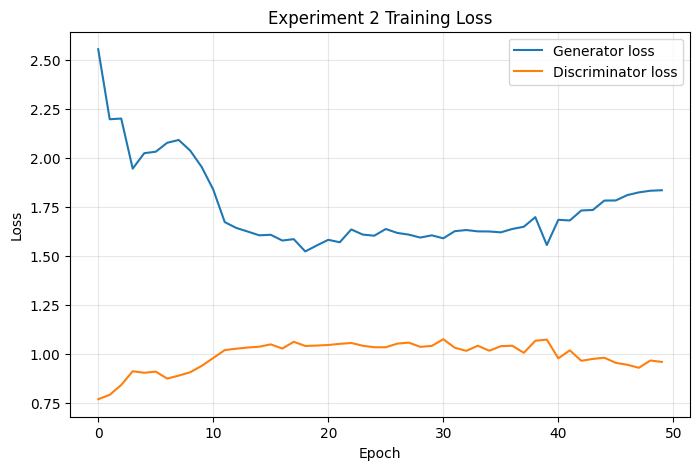

In [54]:
plot_training_losses(
    exp2_generator_losses,
    exp2_discriminator_losses,
    "Experiment 2 Training Loss"
)

### Experiment 2 — Model Training Results

* **Generator loss:** Decreased strongly from **2.5542 to around 1.6** during the first 20 epochs, showing that the generator improved its ability to fool the discriminator.
* **Discriminator loss:** Increased from **0.7672 to around 1.0**, suggesting that distinguishing real from generated images became more difficult as the generator improved.
* **Middle training:** From approximately **epochs 15–38**, both losses were relatively stable, with generator loss around **1.5–1.7** and discriminator loss around **1.0–1.1**. This indicates a more balanced competition between the two networks.
* **Later training:** After around **epoch 40**, generator loss gradually increased while discriminator loss decreased slightly. This suggests the discriminator was beginning to gain an advantage again.
* **Overall:** Compared with Experiment 1, the losses are **closer together and more stable**, indicating a better balance between the generator and discriminator during training.


### Experiment 2: Samples

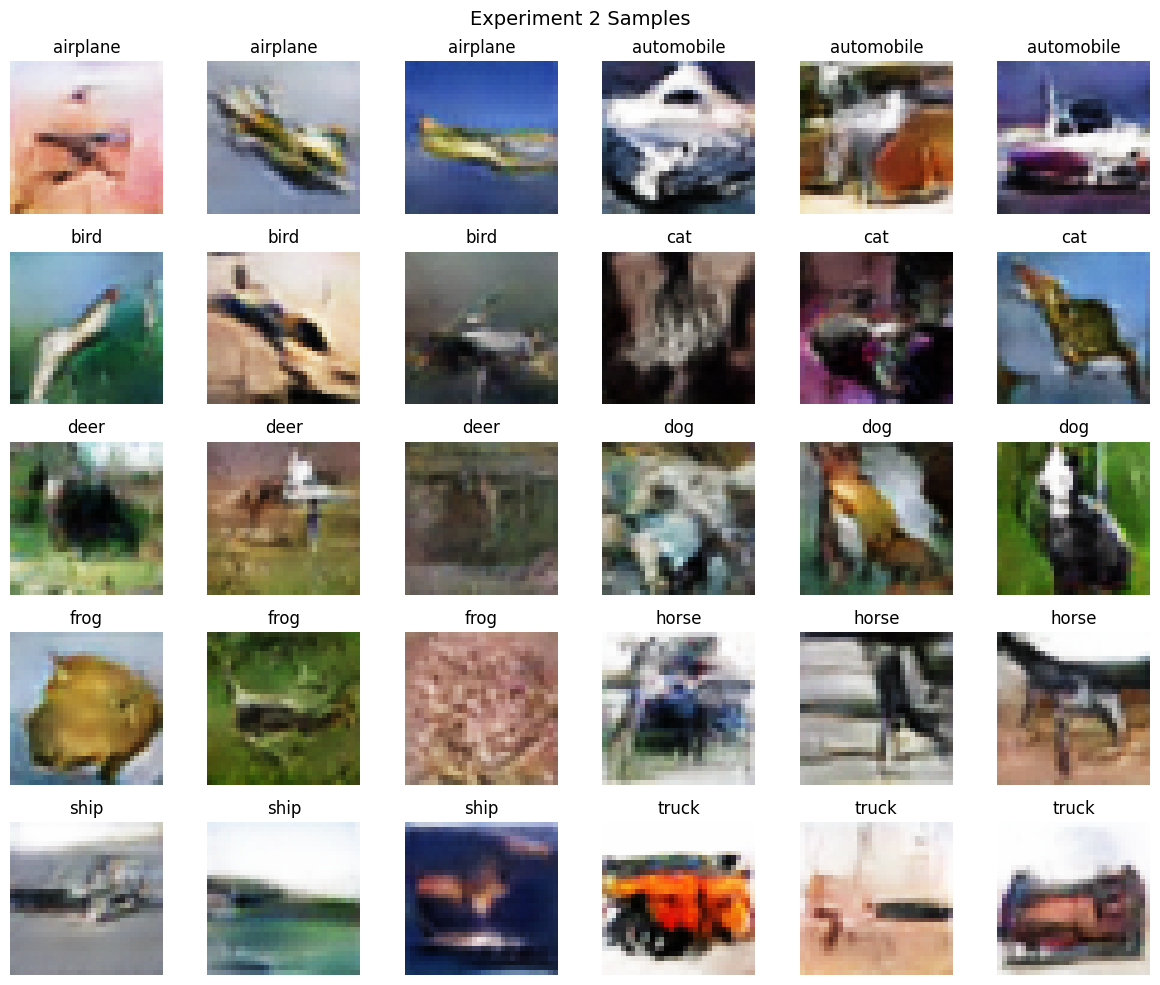

In [55]:
exp2_generator.save_weights(
    OUTPUT_ROOT / "exp2_generator.weights.h5"
)

show_generated_images_per_class(
    generator=exp2_generator,
    latent_dim=EXP2_LATENT_DIM,
    images_per_class=3,
    title="Experiment 2 Samples"
)

### Experiment 2: FID Score

In [56]:
(
    exp2_generated_images,
    exp2_generated_labels
) = generate_conditional_images(
    exp2_generator,
    EXP2_LATENT_DIM,
    images_per_class=500,
    seed=SEED
)

exp2_generated_features = extract_fid_features(
    exp2_generated_images
)

exp2_fid = calculate_fid_from_features(
    real_fid_features,
    exp2_generated_features
)

print(f"Experiment 2 FID: {exp2_fid:.4f}")

Experiment 2 FID: 48.7743


### Experiment 2 — Model Evaluation Results (FID)

* **Generated samples:** The images show **good class consistency overall**. Airplanes, automobiles, deer, dogs, ships and trucks generally contain recognizable features matching their requested labels.
* **Image quality:** Compared with Experiment 1, many objects have **clearer shapes and more suitable backgrounds**, although some samples remain blurry or ambiguous, particularly for visually similar animal classes.
* **FID score:** Experiment 2 achieved an FID of **48.7743**, compared with the baseline Conditional DCGAN's **55.1430**.
* **Improvement:** This is a decrease of about **6.37 FID points (11.6%)**. Since **lower FID is better**, Experiment 2 provides a measurable improvement over the baseline.
* **Overall:** The combination of improved FID and generally recognizable class-conditioned samples suggests that the changes in Experiment 2 improved the model's generated image quality while maintaining control over the requested classes.


| **Model / Change**                                            |   **FID ↓** |
| ------------------------------------------------------------- | ----------: |
| Baseline Conditional DCGAN                                |     55.1430 |
| Experiment 1 — Latent Dimension Increased               |     79.9207 |
| **Experiment 2 — Improved Generator + Label Smoothing (0.8)** | **48.7743** |



### Experiment 2: Generating 20 images for each class

In [57]:
# Generate 20 images for each CIFAR-10 class
(
    exp2_20_images,
    exp2_20_labels
) = generate_conditional_images(
    generator=exp2_generator,
    latent_dim=EXP2_LATENT_DIM,
    images_per_class=20,
    seed=2026
)

print("Generated images shape:", exp2_20_images.shape)
print("Generated labels shape:", exp2_20_labels.shape)

print(
    "Images per class:",
    np.bincount(
        exp2_20_labels,
        minlength=NUM_CLASSES
    )
)

Generated images shape: (200, 32, 32, 3)
Generated labels shape: (200,)
Images per class: [20 20 20 20 20 20 20 20 20 20]


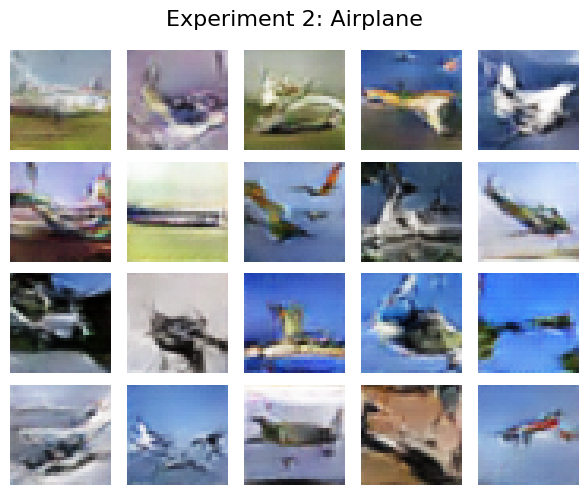

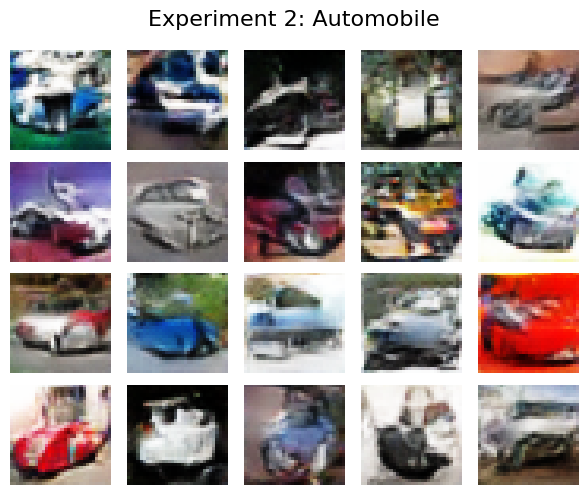

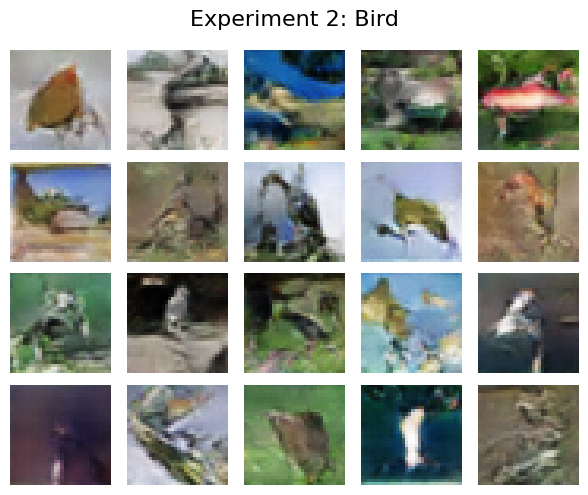

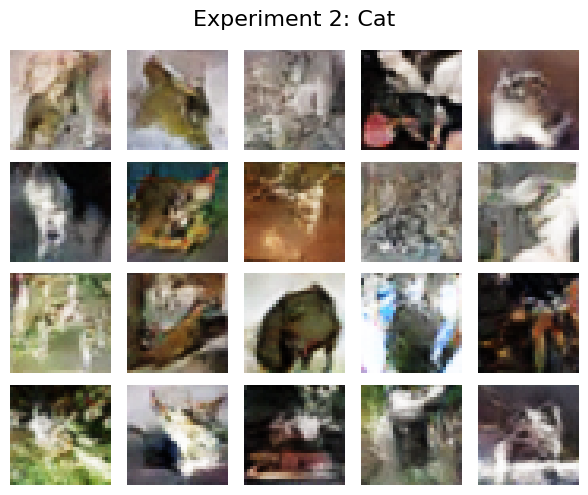

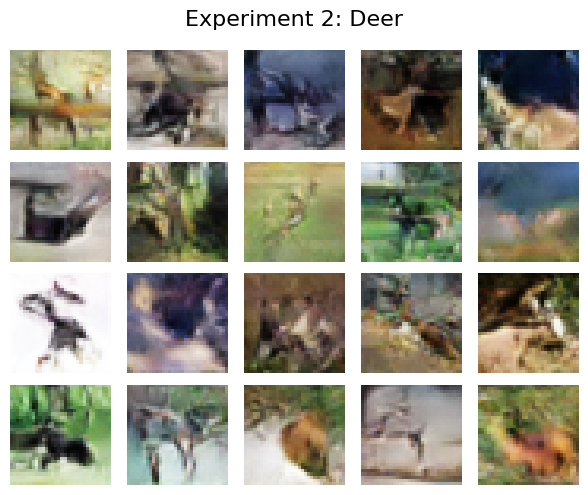

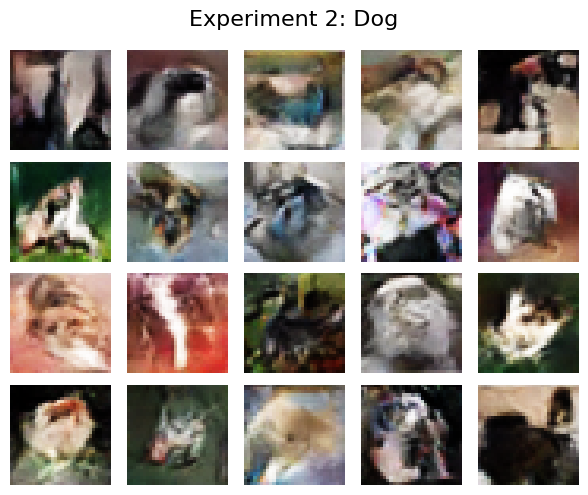

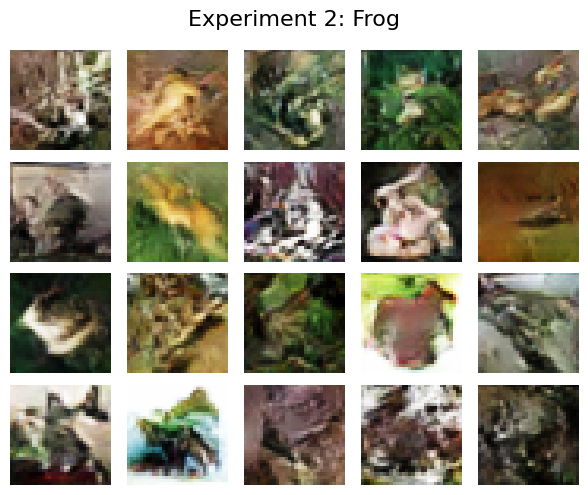

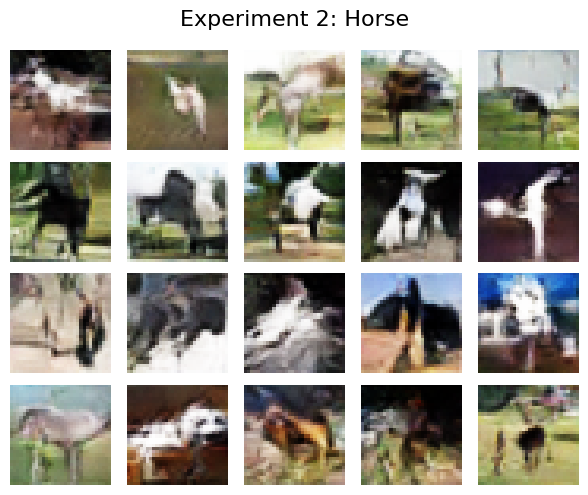

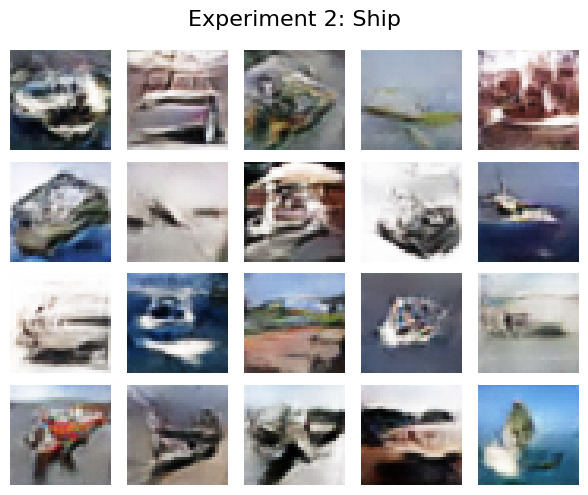

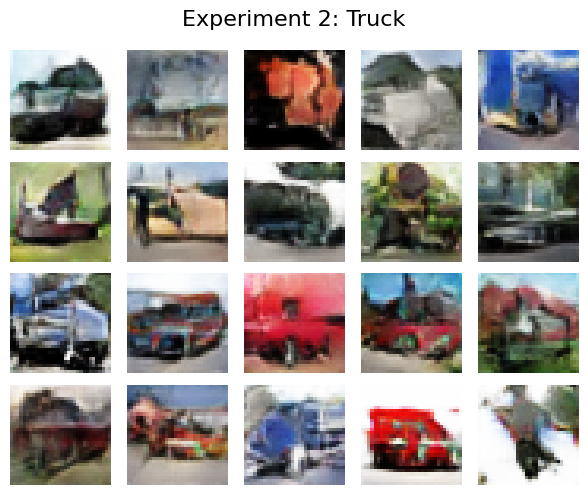

Saved 10 class grids to: C:\Users\User\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\experiment_2_grids


In [58]:
# Folder for the 10 grid images
exp2_grid_directory = (
    OUTPUT_ROOT / "experiment_2_grids"
)

exp2_grid_directory.mkdir(
    parents=True,
    exist_ok=True
)

for class_id, class_name in enumerate(class_names):

    # Select the 20 generated images belonging to this class
    class_images = exp2_20_images[
        exp2_20_labels == class_id
    ]

    # Create a 4 × 5 grid
    figure, axes = plt.subplots(
        4,
        5,
        figsize=(6, 5)
    )

    for image_index, axis in enumerate(
        axes.flatten()
    ):
        axis.imshow(
            np.clip(
                class_images[image_index],
                0.0,
                1.0
            )
        )

        axis.axis("off")

    figure.suptitle(
        f"Experiment 2: {class_name.capitalize()}",
        fontsize=16
    )

    plt.tight_layout()

    # Save one grid image for this class
    grid_file_path = (
        exp2_grid_directory
        / f"exp2_{class_id}_{class_name}_grid.png"
    )

    plt.savefig(
        grid_file_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(figure)

print(
    "Saved 10 class grids to:",
    exp2_grid_directory.resolve()
)

### Experiment 2 — Visual Evaluation

| CIFAR-10 Class |   Clear | Marginal | Nonsense |   Total |
| -------------- | ------: | -------: | -------: | ------: |
| Airplane       |  **15** |        4 |        1 |      20 |
| Automobile     |  **15** |        4 |        1 |      20 |
| Bird           |      11 |        7 |        2 |      20 |
| Cat            |       8 |        8 |        4 |      20 |
| Deer           |      12 |        6 |        2 |      20 |
| Dog            |      10 |        7 |        3 |      20 |
| Frog           |       9 |        8 |        3 |      20 |
| Horse          |  **13** |        6 |        1 |      20 |
| Ship           |      12 |        6 |        2 |      20 |
| Truck          |      11 |        5 |        4 |      20 |
| **TOTAL**      | **116** |   **61** |   **23** | **200** |


- Clear: 58.0%
- Marginal: 30.5%
- Nonsense: 11.5%

Main pattern: Experiment 2 is more consistent across classes. Airplane and automobile are particularly strong, while horse, deer and ship also perform well. Cat remains one of the hardest classes, but there are substantially fewer completely unsuccessful images overall.

# 7. Experiment 3: Adjusting the Discriminator Learning Rate

## 7.1 What Was Changed

Experiment 3 keeps the improved generator architecture, latent dimension of 100 and one-sided label smoothing from Experiment 2.

The only new change is the discriminator learning rate. The generator continues using a learning rate of **0.0002**, while the discriminator learning rate is reduced from **0.0002 to 0.0001**.

This tests whether slowing down discriminator learning can create a better training balance and give the generator more opportunity to improve.

In [59]:
EXP3_LATENT_DIM = EXP2_LATENT_DIM
EXP3_EPOCHS = BASE_EPOCHS
EXP3_REAL_LABEL_VALUE = EXP2_REAL_LABEL_VALUE

EXP3_GENERATOR_LEARNING_RATE = LEARNING_RATE
EXP3_DISCRIMINATOR_LEARNING_RATE = 0.0001

exp3_generator = build_cgan_generator(
    latent_dim=EXP3_LATENT_DIM,
    improved=True,
    model_name="exp3_generator"
)

exp3_discriminator = build_cgan_discriminator(
    model_name="exp3_discriminator"
)

exp3_generator_optimizer = keras.optimizers.Adam(
    learning_rate=EXP3_GENERATOR_LEARNING_RATE,
    beta_1=BETA_1
)

exp3_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=EXP3_DISCRIMINATOR_LEARNING_RATE,
    beta_1=BETA_1
)

exp3_train_step = create_cgan_train_step(
    generator=exp3_generator,
    discriminator=exp3_discriminator,
    generator_optimizer=exp3_generator_optimizer,
    discriminator_optimizer=exp3_discriminator_optimizer,
    latent_dim=EXP3_LATENT_DIM,
    real_label_value=EXP3_REAL_LABEL_VALUE
)

## 7.2 Checking Experiment 3 Settings

The model architecture and label smoothing remain unchanged from Experiment 2. Only the discriminator learning rate is reduced, allowing the effect of this training change to be compared more directly.

In [60]:
print(
    "Generator learning rate:",
    EXP3_GENERATOR_LEARNING_RATE
)

print(
    "Discriminator learning rate:",
    EXP3_DISCRIMINATOR_LEARNING_RATE
)

print(
    "Latent dimension:",
    EXP3_LATENT_DIM
)

print(
    "Real label value:",
    EXP3_REAL_LABEL_VALUE
)

Generator learning rate: 0.0002
Discriminator learning rate: 0.0001
Latent dimension: 100
Real label value: 0.8


## 7.3 Testing, Training and Evaluating Experiment 3

In [61]:
(
    exp3_generator_losses,
    exp3_discriminator_losses
) = train_cgan(
    dataset=cgan_dataset,
    epochs=EXP3_EPOCHS,
    train_step=exp3_train_step,
    experiment_name="Experiment 3"
)

Experiment 3 | Epoch 1/50 - Generator: 1.1414 - Discriminator: 1.4944
Experiment 3 | Epoch 2/50 - Generator: 1.2742 - Discriminator: 1.2461
Experiment 3 | Epoch 3/50 - Generator: 0.9588 - Discriminator: 1.3681
Experiment 3 | Epoch 4/50 - Generator: 0.9156 - Discriminator: 1.4017
Experiment 3 | Epoch 5/50 - Generator: 0.9006 - Discriminator: 1.3937
Experiment 3 | Epoch 6/50 - Generator: 0.9089 - Discriminator: 1.3775
Experiment 3 | Epoch 7/50 - Generator: 0.9190 - Discriminator: 1.3662
Experiment 3 | Epoch 8/50 - Generator: 0.9195 - Discriminator: 1.3631
Experiment 3 | Epoch 9/50 - Generator: 0.9214 - Discriminator: 1.3600
Experiment 3 | Epoch 10/50 - Generator: 0.9274 - Discriminator: 1.3551
Experiment 3 | Epoch 11/50 - Generator: 0.9280 - Discriminator: 1.3524
Experiment 3 | Epoch 12/50 - Generator: 0.9349 - Discriminator: 1.3471
Experiment 3 | Epoch 13/50 - Generator: 0.9366 - Discriminator: 1.3465
Experiment 3 | Epoch 14/50 - Generator: 0.9468 - Discriminator: 1.3424
Experiment 3 | 

### Experiment 3: Training Loss

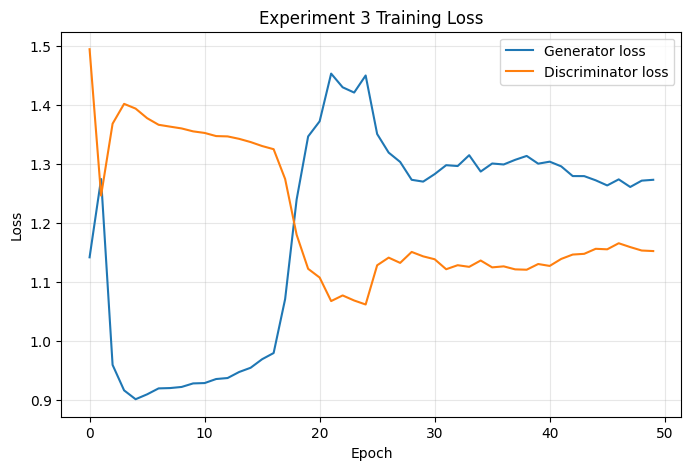

In [62]:
plot_training_losses(
    exp3_generator_losses,
    exp3_discriminator_losses,
    "Experiment 3 Training Loss"
)

### Experiment 3 — Model Training Results

* **Early training (Epochs 1–5):** The losses change dramatically because the **generator and discriminator are initially adapting to each other**. Generator loss drops quickly from **1.14 to 0.90**, while discriminator loss remains relatively high at around **1.4**.
* **Epochs 5–17:** Generator loss stays very low at around **0.90–0.98**, while discriminator loss remains around **1.3–1.4**. This suggests the **generator temporarily has an advantage**, making it harder for the discriminator to distinguish generated from real images.
* **Major shift (Epochs 18–25):** Generator loss suddenly rises from about **0.98 to 1.45**, while discriminator loss falls from about **1.32 to 1.06**. This happens because **GAN training is adversarial**: as the discriminator becomes better at detecting fake images, the generator's task becomes harder, causing its loss to increase.
* **After Epoch 26:** Both losses begin to settle. Generator loss stabilises around **1.27–1.31**, while discriminator loss stays around **1.12–1.16** with only small fluctuations.
* **Overall:** The dramatic movement does **not automatically mean the model failed**. It shows the changing balance between the two competing networks. By the later epochs, the much smaller fluctuations indicate that training reached a **more stable adversarial balance**.

**Key takeaway:** Unlike a normal model, we should **not expect both GAN losses to continuously decrease**. When one network improves, it can make the other network's loss increase, which explains the almost opposite movement seen around Epochs 18–25.


### Experiment 3: Samples

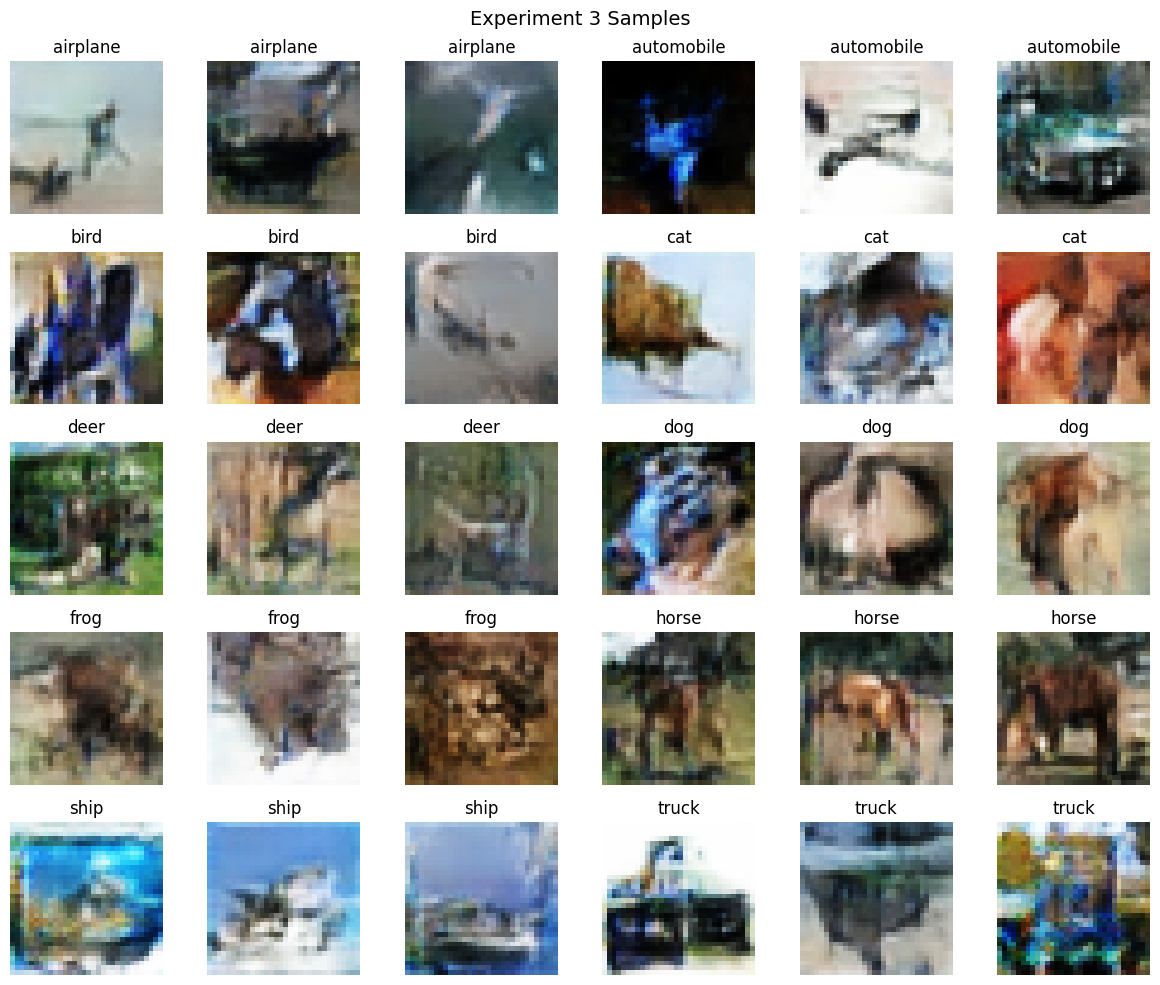

In [63]:
exp3_generator.save_weights(
    OUTPUT_ROOT / "exp3_generator.weights.h5"
)

show_generated_images_per_class(
    generator=exp3_generator,
    latent_dim=EXP3_LATENT_DIM,
    images_per_class=3,
    title="Experiment 3 Samples"
)

### Experiment 3: FID Score

In [64]:
(
    exp3_generated_images,
    exp3_generated_labels
) = generate_conditional_images(
    exp3_generator,
    EXP3_LATENT_DIM,
    images_per_class=500,
    seed=SEED
)

exp3_generated_features = extract_fid_features(
    exp3_generated_images
)

exp3_fid = calculate_fid_from_features(
    real_fid_features,
    exp3_generated_features
)

print(
    f"Experiment 3 FID: "
    f"{exp3_fid:.4f}"
)

Experiment 3 FID: 52.1133


### Experiment 3 — Model Evaluation Results (FID)

* **Generated samples:** The model generally follows the requested class labels. **Horses, deer, ships and some automobiles** are relatively recognizable, showing that the conditional information is being learned.
* **Image quality:** Quality is **mixed across classes**. Several images contain suitable colours, backgrounds and rough object shapes, but some objects remain blurry or difficult to identify, especially among **birds, cats, dogs and frogs**.
* **FID score:** Experiment 3 achieved an FID of **52.1133**.
* Compared with the **Baseline Conditional DCGAN (55.1430)**, the FID improved by about **3.03 points (5.5%)**.
* However, it is higher than **Experiment 2 (48.7743)**, meaning Experiment 3 did not improve the overall image distribution as much as Experiment 2.
* **Overall:** Experiment 3 still improves over the baseline according to FID, and the samples demonstrate successful conditional generation, but the visual quality remains inconsistent across classes.


| **Model / Change**                                            |   **FID ↓** |
| ------------------------------------------------------------- | ----------: |
| Baseline Conditional DCGAN                                    |     55.1430 |
| Experiment 1 — Latent Dimension Increased                     |     79.9207 |
| **Experiment 2 — Improved Generator + Label Smoothing (0.8)** | **48.7743** |
| Experiment 3 — Improved Discriminator                         |     52.1133 |

### Experiment 3: Generating 20 images for each class

In [65]:
# Generate 20 images for each CIFAR-10 class
(
    exp3_20_images,
    exp3_20_labels
) = generate_conditional_images(
    generator=exp3_generator,
    latent_dim=EXP3_LATENT_DIM,
    images_per_class=20,
    seed=2026
)

print("Generated images shape:", exp3_20_images.shape)
print("Generated labels shape:", exp3_20_labels.shape)

print(
    "Images per class:",
    np.bincount(
        exp3_20_labels,
        minlength=NUM_CLASSES
    )
)

Generated images shape: (200, 32, 32, 3)
Generated labels shape: (200,)
Images per class: [20 20 20 20 20 20 20 20 20 20]


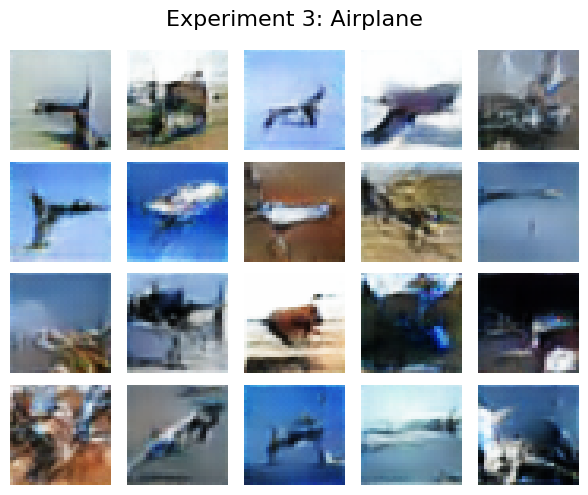

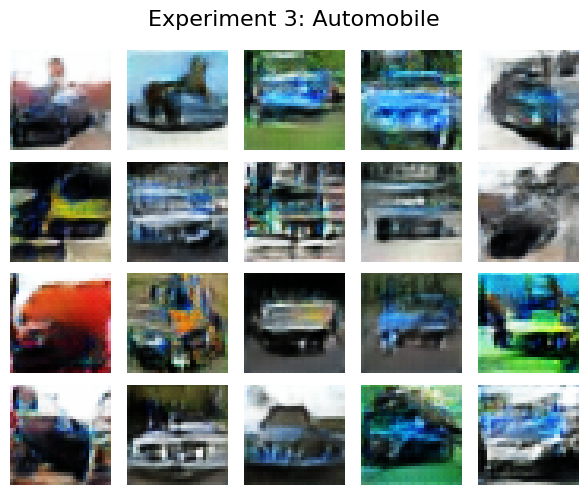

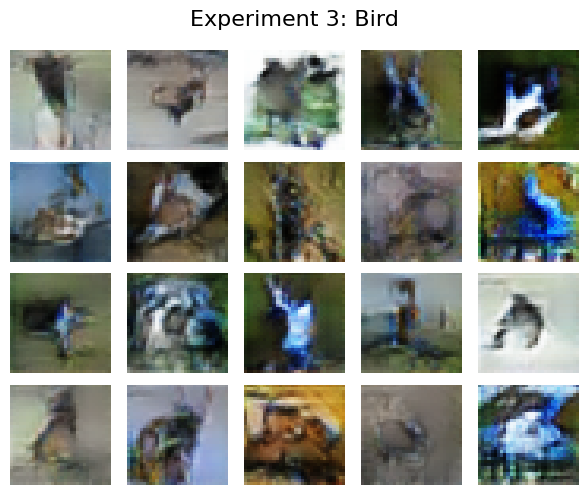

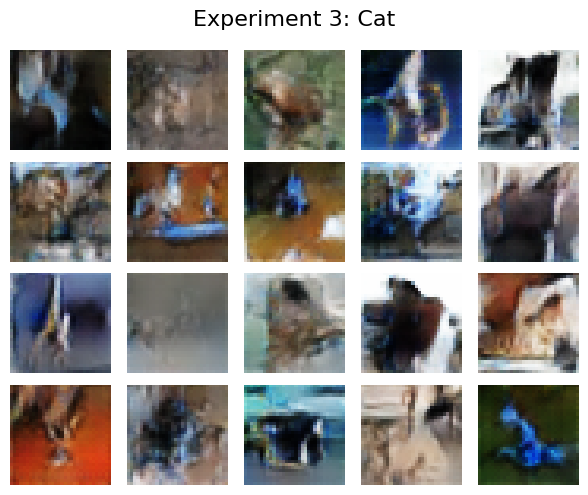

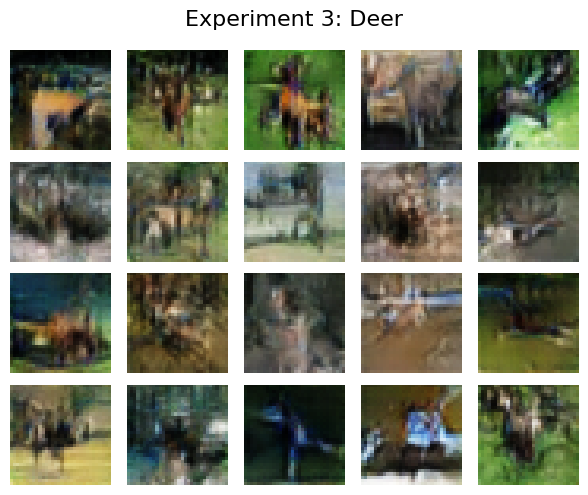

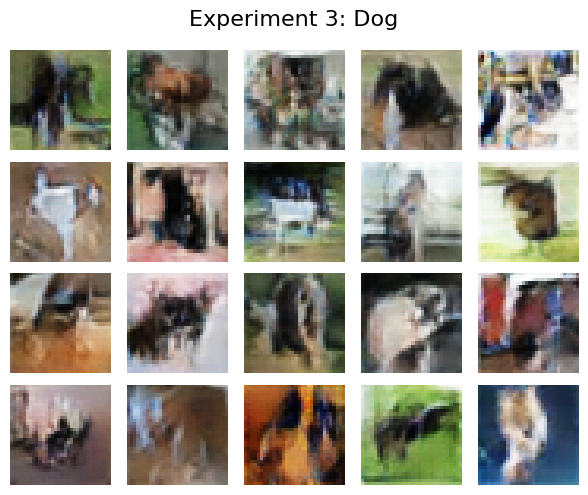

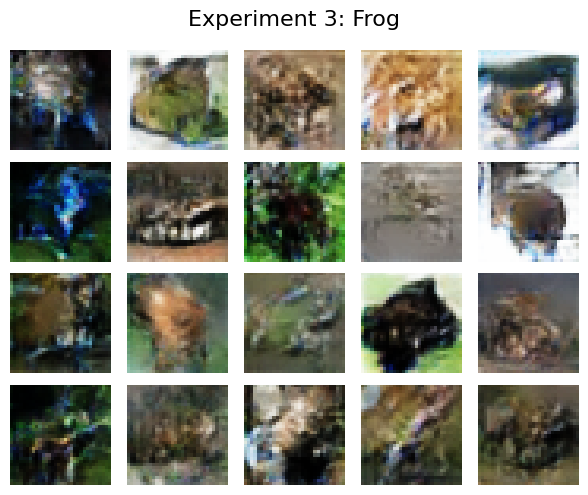

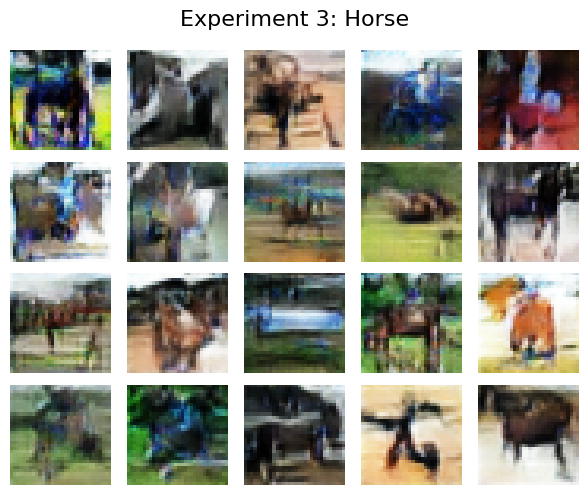

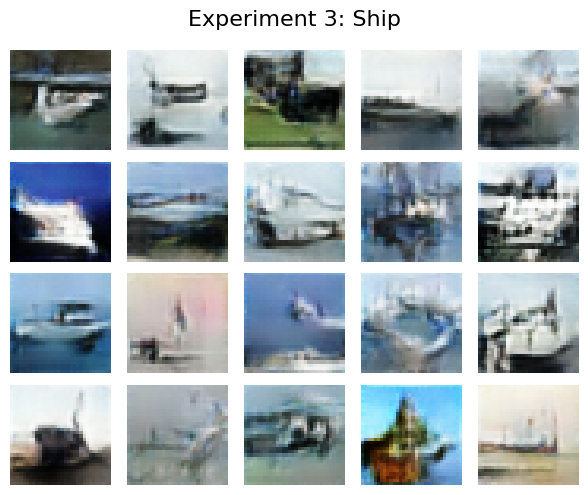

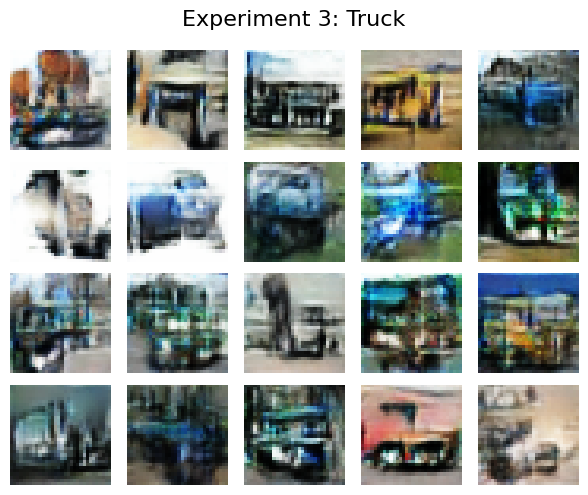

Saved 10 class grids to: C:\Users\User\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\experiment_3_grids


In [66]:
# Folder for the 10 grid images
exp3_grid_directory = (
    OUTPUT_ROOT / "experiment_3_grids"
)

exp3_grid_directory.mkdir(
    parents=True,
    exist_ok=True
)

for class_id, class_name in enumerate(class_names):

    # Select the 20 generated images belonging to this class
    class_images = exp3_20_images[
        exp3_20_labels == class_id
    ]

    # Create a 4 × 5 grid
    figure, axes = plt.subplots(
        4,
        5,
        figsize=(6, 5)
    )

    for image_index, axis in enumerate(
        axes.flatten()
    ):
        axis.imshow(
            np.clip(
                class_images[image_index],
                0.0,
                1.0
            )
        )

        axis.axis("off")

    figure.suptitle(
        f"Experiment 3: {class_name.capitalize()}",
        fontsize=16
    )

    plt.tight_layout()

    grid_file_path = (
        exp3_grid_directory
        / f"exp3_{class_id}_{class_name}_grid.png"
    )

    plt.savefig(
        grid_file_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(figure)

print(
    "Saved 10 class grids to:",
    exp3_grid_directory.resolve()
)

### Experiment 3 — Visual Evaluation

| CIFAR-10 Class |   Clear | Marginal | Nonsense |   Total |
| -------------- | ------: | -------: | -------: | ------: |
| Airplane       |      10 |        6 |        4 |      20 |
| Automobile     |  **15** |        4 |        1 |      20 |
| Bird           |       8 |        7 |        5 |      20 |
| Cat            |       6 |        7 |    **7** |      20 |
| Deer           |  **14** |        5 |        1 |      20 |
| Dog            |       8 |        7 |        5 |      20 |
| Frog           |       6 |        8 |        6 |      20 |
| Horse          |      11 |        7 |        2 |      20 |
| Ship           |      12 |        6 |        2 |      20 |
| Truck          |      11 |        8 |        1 |      20 |
| **TOTAL**      | **101** |   **65** |   **34** | **200** |


- Clear: 50.5%
- Marginal: 32.5%
- Nonsense: 17.0%

Main pattern: deer and automobile are especially strong, with reasonable results for ship, horse and truck. However, cat, frog, bird and dog contain noticeably more ambiguous or unsuccessful images than Experiment 2.

# Comparison of Experiments 1,2,3

| Model                                                         |   Clear ↑ |  Marginal | Nonsense ↓ |       FID ↓ |
| ------------------------------------------------------------- | --------: | --------: | ---------: | ----------: |
| Experiment 1 — Latent Dimension Increased                     |     45.5% |     33.5% |      21.0% |     79.9207 |
| **Experiment 2 — Improved Generator + Label Smoothing (0.8)** | **58.0%** | **30.5%** |  **11.5%** | **48.7743** |
| Experiment 3 — Improved Discriminator                         |     50.5% |     32.5% |      17.0% |     52.1133 |



| Experiment                                                    | Visual Evaluation                                                                                                                                                                                                                                                                                                                                                          |
| ------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Experiment 1 — Increased Latent Dimension**                 | Some classes are recognisable, especially **automobile, horse and ship**. However, there is strong repetition within several classes. Automobile, frog, ship and truck contain many images with very similar appearance, suggesting **limited diversity**. Several animal classes are also difficult to distinguish clearly.                                               |
| **Experiment 2 — Improved Generator + Label Smoothing (0.8)** | Shows noticeably **greater variation within classes**. Airplanes and automobiles are generally recognisable, while horse and deer also show reasonable class characteristics. However, difficult animal classes such as **cat, dog and frog remain blurry and sometimes ambiguous**. Overall, it produces a wider range of outputs than Experiment 1.                      |
| **Experiment 3 — Improved Discriminator**                     | Several classes show strong recognisable characteristics, particularly **automobile, deer, ship and truck**. The generated images also show good variation. However, **cat, dog and frog remain difficult**, with considerable overlap between animal-like shapes. Overall visual quality is competitive with Experiment 2 but not consistently better across every class. |

## Final Model Selection - Experiment 2 (Improved Generator + Label Smoothing (0.8))

### Why Experiment 2 was selected

* **Best visual recognisability:** Experiment 2 achieved the **highest Clear rate of 58.0%**, compared with 45.5% for Experiment 1 and 50.5% for Experiment 3.
* **Fewest failed outputs:** It also achieved the **lowest Nonsense rate of 11.5%**, showing that fewer generated images were completely unrecognisable.
* **Better consistency across classes:** Experiment 2 produced recognisable outputs across both vehicle and animal classes, while Experiment 1 showed more repetition and Experiment 3 contained more ambiguous/distorted images.
* **Best FID score:** Experiment 2 achieved the **lowest FID of 48.7743**, compared with 79.9207 for Experiment 1 and 52.1133 for Experiment 3.
* **Both evaluation methods agree:** The manual visual evaluation and FID independently identify Experiment 2 as the strongest model, making the selection more reliable than relying on only one metric.

### Conclusion

**Experiment 2 — Improved Generator + Label Smoothing (0.8)** was selected as the best model from Experiments 1–3 because it achieved the **best overall balance of image recognisability, class consistency, diversity and distribution similarity**. It produced the highest proportion of clear images, the fewest nonsense outputs, and the lowest FID score. Therefore, Experiment 2 was used as the base model for the next stage, where **data augmentation was tested in Experiment 4**.


# 8. Experiment 4: Data Augmentation

## 8.1 What Was Changed

Experiment 4 uses the same configuration as Experiment 2, which currently achieved the best FID score.

The following settings are kept unchanged:

- **Latent dimension:** 100
- **Improved generator architecture**
- **One-sided label smoothing:** real labels = 0.8
- **Generator learning rate:** 0.0002
- **Discriminator learning rate:** 0.0002
- **Training epochs:** 50

The only new change is **data augmentation applied to the real training images**.

Horizontal flipping and small translations are used to introduce additional variation while keeping the images realistic for CIFAR-10. Fresh generator and discriminator models are created so that no trained Experiment 2 weights are reused.

This allows the effect of data augmentation to be compared directly with Experiment 2.

## 8.2 Define the augmentation

In [67]:
def augment_cifar_image(
    image,
    label
):

    # Random horizontal flip
    image = tf.image.random_flip_left_right(
        image
    )

    # Add a small reflected border
    image = tf.pad(
        image,
        paddings=[
            [2, 2],
            [2, 2],
            [0, 0]
        ],
        mode="REFLECT"
    )

    # Randomly crop back to CIFAR-10 size
    image = tf.image.random_crop(
        image,
        size=[32, 32, 3]
    )

    return image, label

**Augmentation Used:**

- **Horizontal flip:** Provides a different left-right orientation of the same object.
- **Small translation:** Reflective padding followed by random cropping slightly shifts the object within the image.
- **Image size remains unchanged:** All augmented images remain **32 × 32 × 3**.
- **Training only:** Augmentation is applied only to the training dataset. The validation images used for FID remain unchanged so that evaluation stays consistent.

### 8.3 Create the augmented training dataset

In [68]:
exp4_dataset = create_dataset(
    images=x_train_gan,
    labels=y_train_split,
    batch_size=BATCH_SIZE,
    augment_fn=augment_cifar_image
)

print(
    "Experiment 4 batches:",
    tf.data.experimental.cardinality(
        exp4_dataset
    ).numpy()
)

Experiment 4 batches: 351


## 8.4 Checking the Augmented Images

Before training, examples of the augmented images are displayed to confirm that the transformations introduce variation without severely changing the original image content or class.

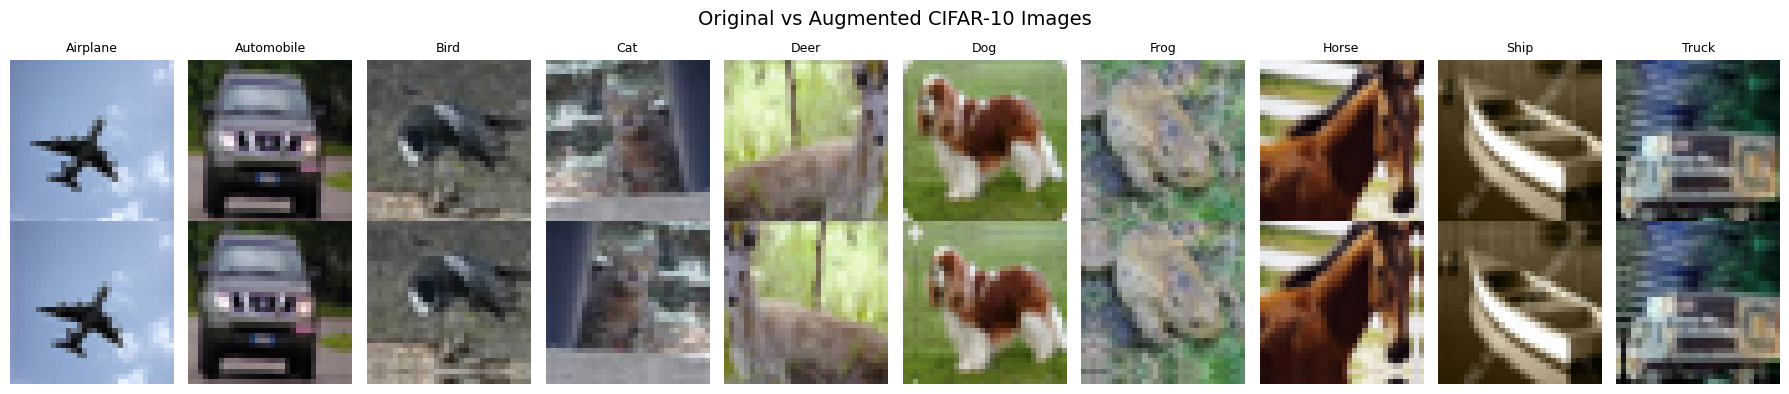

In [69]:
figure, axes = plt.subplots(
    2,
    NUM_CLASSES,
    figsize=(18, 4)
)

for class_id, class_name in enumerate(class_names):

    class_indices = np.where(
        y_train_split.reshape(-1) == class_id
    )[0]

    image_index = class_indices[0]

    original_image = x_train_gan[
        image_index
    ]

    label = y_train_split[
        image_index
    ]

    augmented_image, _ = augment_cifar_image(
        original_image,
        label
    )

    original_image = denormalise_gan_images(
        tf.expand_dims(
            original_image,
            axis=0
        )
    )[0].numpy()

    augmented_image = denormalise_gan_images(
        tf.expand_dims(
            augmented_image,
            axis=0
        )
    )[0].numpy()

    # Original row
    axes[0, class_id].imshow(
        np.clip(
            original_image,
            0.0,
            1.0
        )
    )

    axes[0, class_id].set_title(
        class_name.capitalize(),
        fontsize=9
    )

    axes[0, class_id].axis("off")

    # Augmented row
    axes[1, class_id].imshow(
        np.clip(
            augmented_image,
            0.0,
            1.0
        )
    )

    axes[1, class_id].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    fontsize=11
)

axes[1, 0].set_ylabel(
    "Augmented",
    fontsize=11
)

plt.suptitle(
    "Original vs Augmented CIFAR-10 Images",
    fontsize=14
)

plt.tight_layout()
plt.show()

The augmented examples retain the original CIFAR-10 classes while introducing small changes in orientation and position. The transformations are kept mild because overly strong augmentation could distort the small 32 × 32 images and make the class harder to recognise.

## 8.5 Building Fresh Experiment 4 Models

Experiment 4 uses the same model configuration as Experiment 2. Fresh generator and discriminator models are created with new weights so that the comparison measures the effect of augmentation rather than additional training of the previous model.

In [70]:
EXP4_LATENT_DIM = EXP2_LATENT_DIM
EXP4_EPOCHS = BASE_EPOCHS
EXP4_REAL_LABEL_VALUE = EXP2_REAL_LABEL_VALUE

exp4_generator = build_cgan_generator(
    latent_dim=EXP4_LATENT_DIM,
    improved=True,
    model_name="exp4_generator"
)

exp4_discriminator = build_cgan_discriminator(
    model_name="exp4_discriminator"
)

exp4_generator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

exp4_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

exp4_train_step = create_cgan_train_step(
    generator=exp4_generator,
    discriminator=exp4_discriminator,
    generator_optimizer=exp4_generator_optimizer,
    discriminator_optimizer=exp4_discriminator_optimizer,
    latent_dim=EXP4_LATENT_DIM,
    real_label_value=EXP4_REAL_LABEL_VALUE
)

## 8.6 Testing and Training Experiment 4

In [71]:
(
    exp4_generator_losses,
    exp4_discriminator_losses
) = train_cgan(
    dataset=exp4_dataset,
    epochs=EXP4_EPOCHS,
    train_step=exp4_train_step,
    experiment_name="Experiment 4"
)

Experiment 4 | Epoch 1/50 - Generator: 2.4645 - Discriminator: 0.7688
Experiment 4 | Epoch 2/50 - Generator: 2.4664 - Discriminator: 0.7430
Experiment 4 | Epoch 3/50 - Generator: 2.1894 - Discriminator: 0.8573
Experiment 4 | Epoch 4/50 - Generator: 2.2054 - Discriminator: 0.8367
Experiment 4 | Epoch 5/50 - Generator: 2.0725 - Discriminator: 0.9034
Experiment 4 | Epoch 6/50 - Generator: 2.1215 - Discriminator: 0.8526
Experiment 4 | Epoch 7/50 - Generator: 2.1377 - Discriminator: 0.8621
Experiment 4 | Epoch 8/50 - Generator: 2.0764 - Discriminator: 0.8851
Experiment 4 | Epoch 9/50 - Generator: 1.9265 - Discriminator: 0.9378
Experiment 4 | Epoch 10/50 - Generator: 1.8898 - Discriminator: 0.9601
Experiment 4 | Epoch 11/50 - Generator: 1.7351 - Discriminator: 1.0079
Experiment 4 | Epoch 12/50 - Generator: 1.7305 - Discriminator: 0.9942
Experiment 4 | Epoch 13/50 - Generator: 1.7234 - Discriminator: 1.0003
Experiment 4 | Epoch 14/50 - Generator: 1.6828 - Discriminator: 1.0114
Experiment 4 | 

### Experiment 4: Training Loss

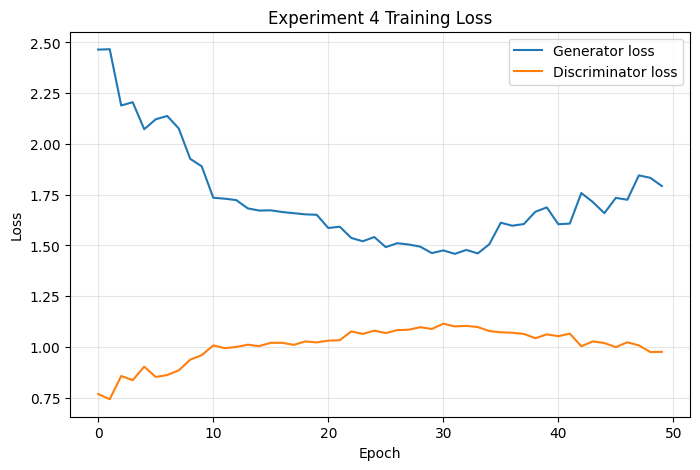

In [72]:
plot_training_losses(
    exp4_generator_losses,
    exp4_discriminator_losses,
    "Experiment 4 Training Loss"
)

### Experiment 4 — Model Training Results

* **Generator loss:** started high at around **2.46**, then decreased steadily to about **1.46–1.50** by epochs 30–34. This shows that the generator improved strongly during the first half of training.
* **Discriminator loss:** increased from around **0.77** to approximately **1.10**, meaning the discriminator found it harder to distinguish real from generated images as training progressed.
* **Most stable period:** around **epochs 20–34**, where generator loss stayed near **1.5–1.6** and discriminator loss around **1.05–1.11**. This suggests a relatively balanced adversarial stage.
* **Later epochs:** after about epoch 35, generator loss began rising again while discriminator loss gradually decreased. This indicates that the discriminator started regaining some advantage.
* **Overall:** the training pattern is similar to Experiment 2, but the losses remain reasonably close for a long middle section. Since Experiment 4 uses the selected Experiment 2 configuration with **data augmentation**, this suggests the model was still able to learn effectively even with the more varied training inputs.

**Conclusion:** Experiment 4 trained stably overall, with the strongest balance occurring around the middle of training. The later increase in generator loss suggests that improvement may have started to slow toward the end, so the generated samples and FID score are needed to determine whether data augmentation actually improved image quality.


### Experiment 4: Samples

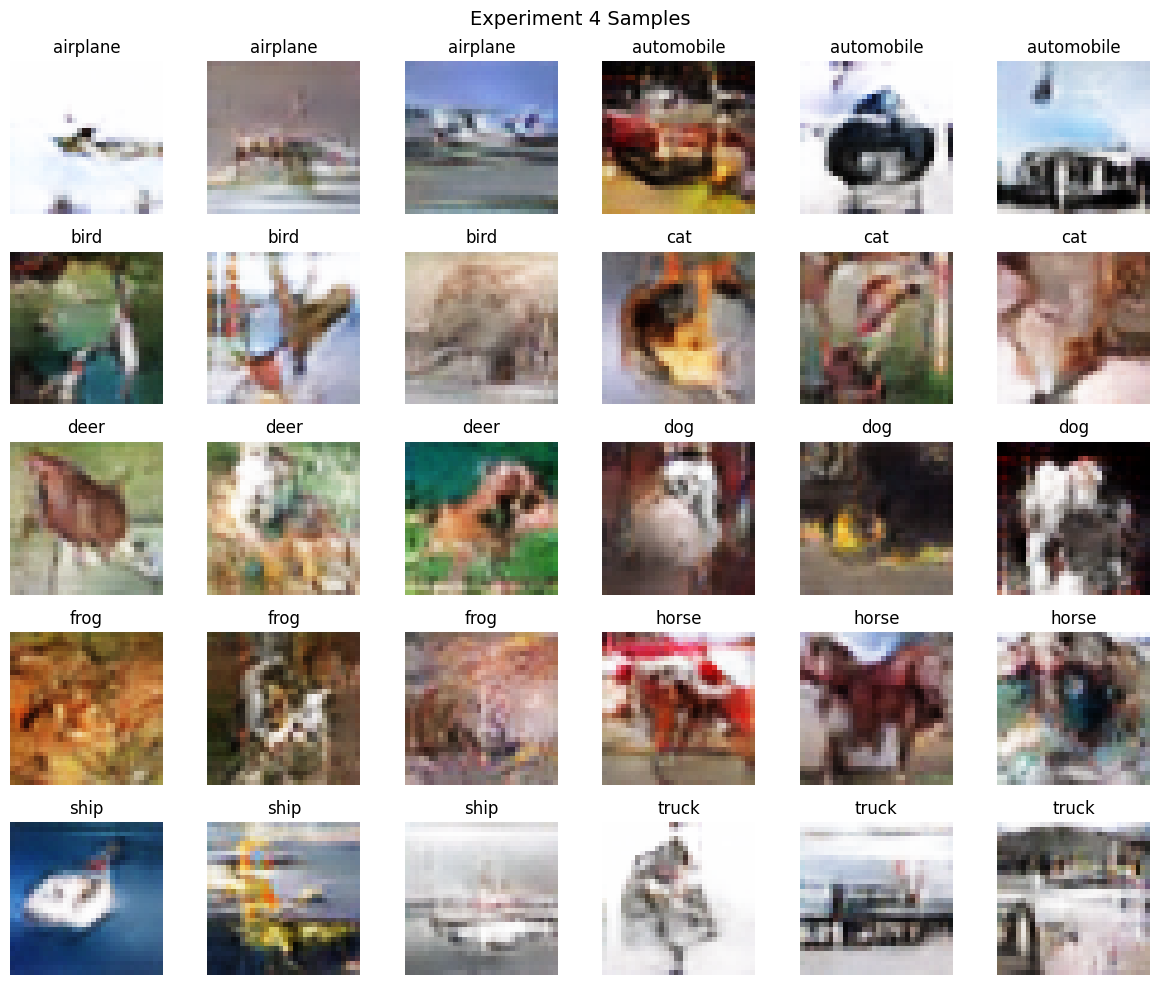

In [73]:
exp4_generator.save_weights(
    OUTPUT_ROOT
    / "exp4_generator.weights.h5"
)

show_generated_images_per_class(
    generator=exp4_generator,
    latent_dim=EXP4_LATENT_DIM,
    images_per_class=3,
    title="Experiment 4 Samples"
)

### Experiment 4: FID Score

In [74]:
(
    exp4_generated_images,
    exp4_generated_labels
) = generate_conditional_images(
    exp4_generator,
    EXP4_LATENT_DIM,
    images_per_class=500,
    seed=SEED
)

exp4_generated_features = extract_fid_features(
    exp4_generated_images
)

exp4_fid = calculate_fid_from_features(
    real_fid_features,
    exp4_generated_features
)

print(
    f"Experiment 4 FID: "
    f"{exp4_fid:.4f}"
)

Experiment 4 FID: 46.9750


### Experiment 4 — Model Evaluation Results

* **Generated samples:** The model produces recognizable class-related features across many CIFAR-10 classes. Airplanes, deer, horses and ships are especially clear, although some animal classes are still blurry or ambiguous.
* **FID score:** Experiment 4 achieved **46.9750**.
* Compared with the **Baseline Conditional DCGAN (55.1430)**, Experiment 4 improves the FID by **8.1680 points**.
* Compared with **Experiment 2 (48.7743)**, Experiment 4 further improves the FID by **1.7993 points**.
* Since **lower FID is better**, this indicates that adding data augmentation to the Experiment 2 configuration improved the overall similarity between generated and real CIFAR-10 images.

**Overall:** Experiment 4 improved on both the original baseline and Experiment 2, suggesting that **data augmentation provided an additional improvement without changing the core Experiment 2 model configuration**.


| **Model / Change**                                        |   **FID ↓** |
| --------------------------------------------------------- | ----------: |
| Baseline Conditional DCGAN                                |     55.1430 |
| Experiment 2 — Improved Generator + Label Smoothing (0.8) |     48.7743 |
| **Experiment 4 — Experiment 2 + Data Augmentation**       | **46.9750** |

### Experiment 4: Generating 20 images for each class

In [75]:
(
    exp4_20_images,
    exp4_20_labels
) = generate_conditional_images(
    generator=exp4_generator,
    latent_dim=EXP4_LATENT_DIM,
    images_per_class=20,
    seed=2026
)

print(
    "Generated images shape:",
    exp4_20_images.shape
)

print(
    "Generated labels shape:",
    exp4_20_labels.shape
)

print(
    "Images per class:",
    np.bincount(
        exp4_20_labels,
        minlength=NUM_CLASSES
    )
)

Generated images shape: (200, 32, 32, 3)
Generated labels shape: (200,)
Images per class: [20 20 20 20 20 20 20 20 20 20]


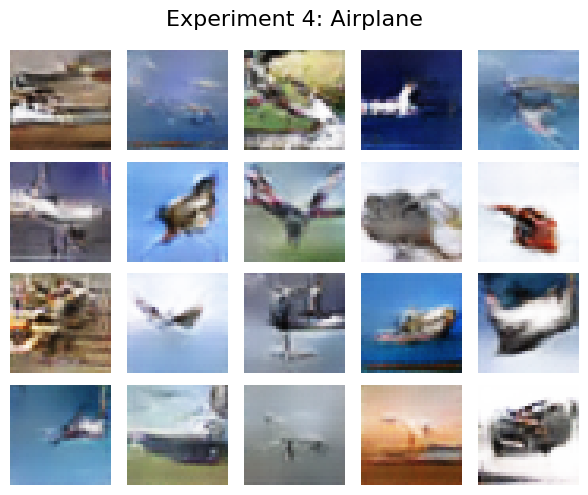

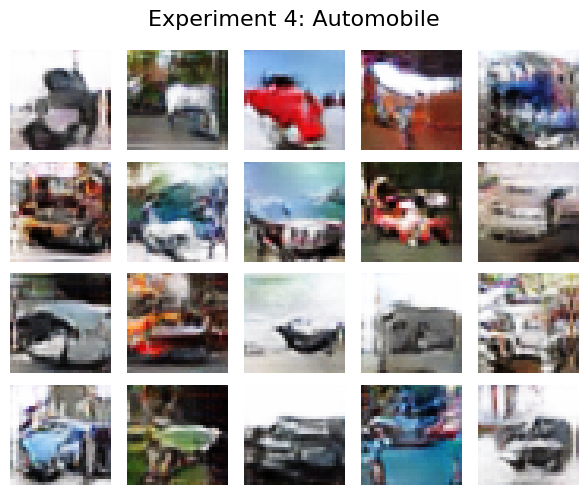

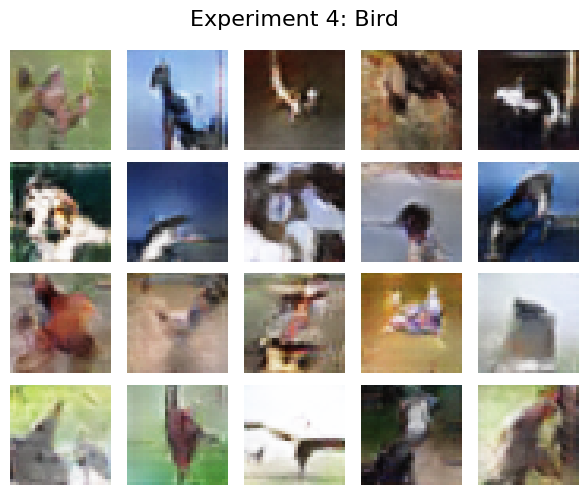

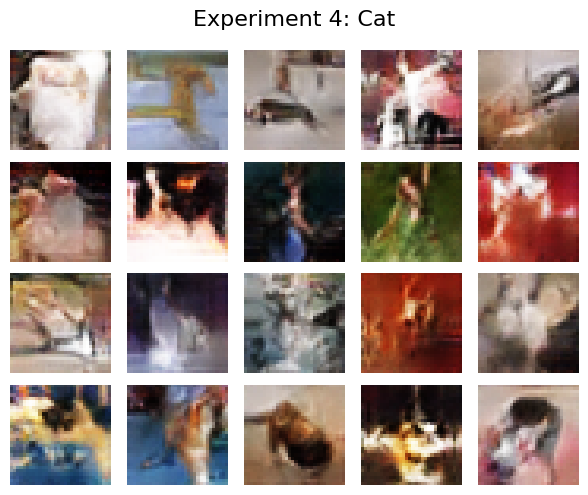

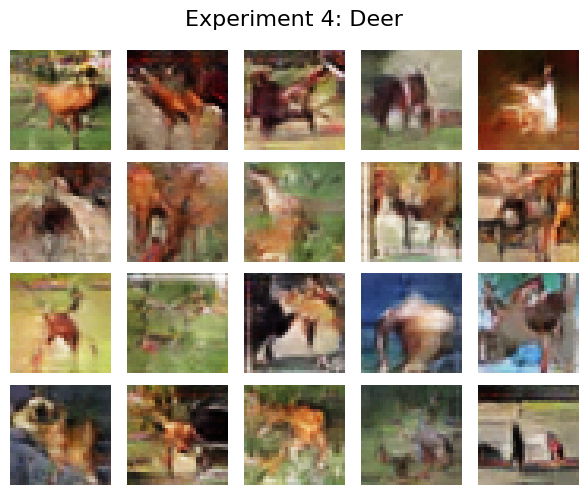

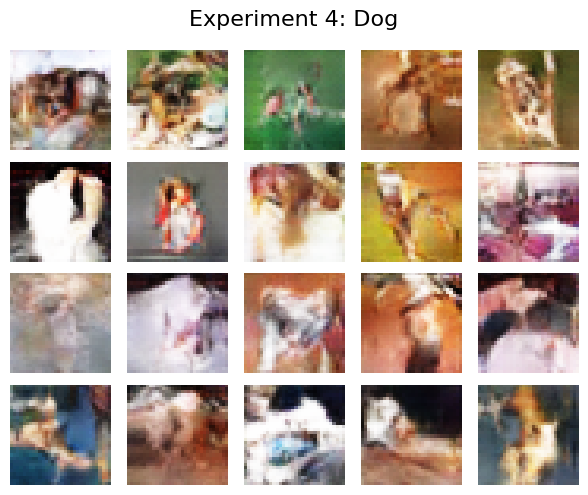

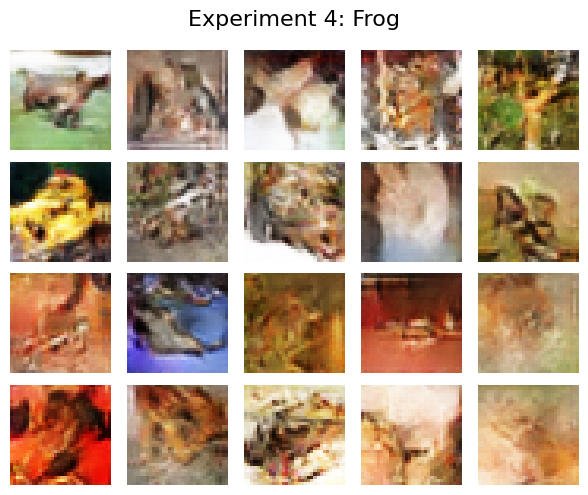

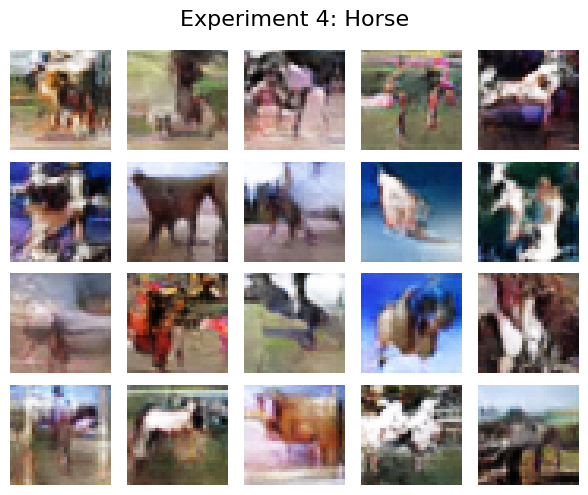

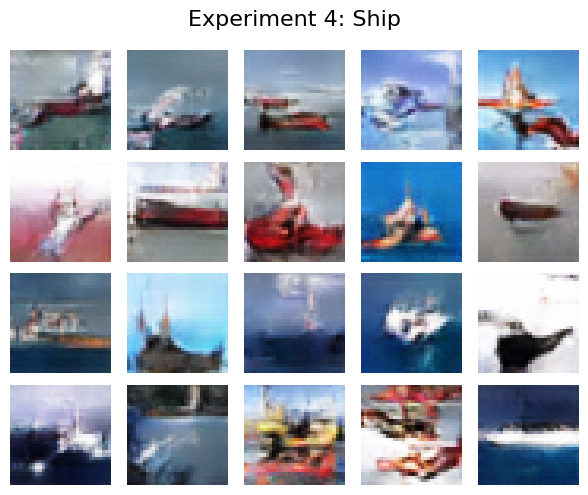

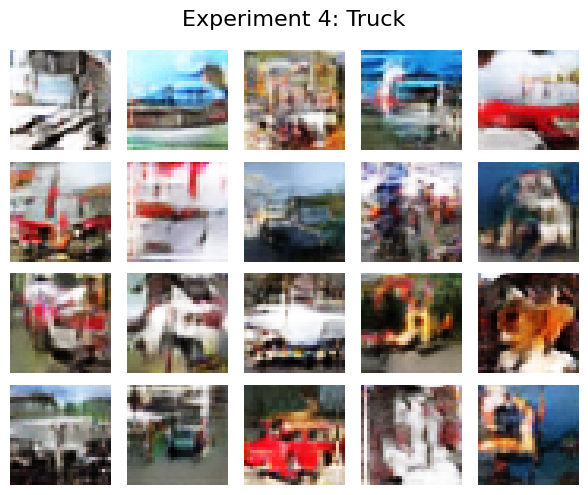

Saved 10 class grids to: C:\Users\User\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\experiment_4_grids


In [76]:
exp4_grid_directory = (
    OUTPUT_ROOT
    / "experiment_4_grids"
)

exp4_grid_directory.mkdir(
    parents=True,
    exist_ok=True
)

for class_id, class_name in enumerate(
    class_names
):

    class_images = exp4_20_images[
        exp4_20_labels == class_id
    ]

    figure, axes = plt.subplots(
        4,
        5,
        figsize=(6, 5)
    )

    for image_index, axis in enumerate(
        axes.flatten()
    ):

        axis.imshow(
            np.clip(
                class_images[image_index],
                0.0,
                1.0
            )
        )

        axis.axis("off")

    figure.suptitle(
        f"Experiment 4: "
        f"{class_name.capitalize()}",
        fontsize=16
    )

    plt.tight_layout()

    grid_file_path = (
        exp4_grid_directory
        / (
            f"exp4_{class_id}_"
            f"{class_name}_grid.png"
        )
    )

    plt.savefig(
        grid_file_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(
        figure
    )

print(
    "Saved 10 class grids to:",
    exp4_grid_directory.resolve()
)

### Experiment 4 — Visual Evaluation

| CIFAR-10 Class |   Clear | Marginal | Nonsense |   Total |
| -------------- | ------: | -------: | -------: | ------: |
| Airplane       |      12 |        6 |        2 |      20 |
| Automobile     |      13 |        5 |        2 |      20 |
| Bird           |      10 |        7 |        3 |      20 |
| Cat            |       7 |        8 |        5 |      20 |
| Deer           |      14 |        5 |        1 |      20 |
| Dog            |       9 |        7 |        4 |      20 |
| Frog           |       6 |        8 |        6 |      20 |
| Horse          |      13 |        6 |        1 |      20 |
| Ship           |      14 |        5 |        1 |      20 |
| Truck          |      11 |        6 |        3 |      20 |
| **TOTAL**      | **109** |   **63** |   **28** | **200** |
                                                                    


- Clear: 54.4%
- Marginal: 31.5%
- Nonsense: 14.0%

The strongest Experiment 4 classes are deer, ship, automobile and horse. Cat and especially frog remain difficult, with many outputs containing only general animal-like or texture-like features rather than a clearly identifiable object.

# Comparison of Experiments 2 and 4


| Model                                                         |   Clear ↑ |  Marginal | Nonsense ↓ |       FID ↓ |
| ------------------------------------------------------------- | --------: | --------: | ---------: | ----------: |
| Experiment 2: Improved Generator + Label Smoothing (0.8) | **58.0%** | **30.5%** |  **11.5%** |     48.7743 |
| Experiment 4: Experiment 2 + Data Augmentation               |     54.5% |     31.5% |      14.0% | **46.9750** |

### Visual Evaluation

| Experiment                                                    | Visual Evaluation                                                                                                                                                                                                                                                                    |
| ------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **Experiment 2 — Improved Generator + Label Smoothing (0.8)** | Produced the **higher proportion of clearly recognisable images (58.0%)** and fewer nonsense outputs (11.5%). Images showed good variation across classes, although difficult animal classes such as cat, dog and frog remained less consistent.                                     |
| **Experiment 4 — + Data Augmentation**                        | Generated several strong examples, particularly for **deer, ship, automobile and horse**. However, overall Clear images decreased to **54.5%**, while Nonsense images increased to **14.0%**. Therefore, augmentation did not consistently improve individual image recognisability. |

# Effects of Data Augmentation

### Why Experiment 4 was selected for the next stage

* **Better FID score:** FID improved from **48.7743 to 46.9750**, indicating that the generated-image distribution became slightly closer to the real CIFAR-10 distribution.
* **Visual improvement was not consistent:** The Clear rate decreased from **58.0% to 54.5%**, while the Nonsense rate increased from **11.5% to 14.0%**.
* **Mixed effect of augmentation:** This shows that augmentation improved the **quantitative distribution-level metric**, but did not directly improve human recognisability of individual generated images.
* **Still worth continuing:** Since the FID improvement suggests that augmentation provided some benefit, Experiment 4 was retained to investigate whether **longer training** could allow the model to learn more effectively from the augmented data.

### Conclusion

**Data augmentation produced a mixed result.** Experiment 4 achieved a lower FID score of **46.9750**, improving on Experiment 2's **48.7743**, but its visual evaluation was slightly weaker, with fewer Clear and more Nonsense images. Therefore, augmentation alone did **not conclusively improve overall image quality**. However, because it improved the FID score, **Experiment 4 was carried forward to Experiment 5**, where the training duration was increased from **50 to 100 epochs** to determine whether additional training could better utilise the augmented data.

# 9. Final Experiment: Effect of Longer Training

## 9.1 Purpose

Experiment 4 was selected as the best model based on the combined FID and visual evaluation results.

All previous experiments were trained for 50 epochs. Therefore, this final experiment investigates whether simply allowing the best model to train for longer can further improve image generation quality.

The Experiment 4 architecture and hyperparameters are kept unchanged, while the number of training epochs is increased from **50 to 100**.

This allows the effect of training duration to be evaluated independently.

### Controlled Comparison

| Setting | Experiment 4 | 100-Epoch Experiment |
|---|---:|---:|
| Latent dimension | 100 | 100 |
| Generator architecture | Improved | Improved |
| Label smoothing | 0.8 | 0.8 |
| Generator learning rate | 0.0002 | 0.0002 |
| Discriminator learning rate | 0.0002 | 0.0002 |
| Data augmentation | Yes | Yes |
| **Epochs** | **50** | **100** |

Only the **training duration** is changed.

In [78]:
EXP5_LATENT_DIM = EXP4_LATENT_DIM
EXP5_EPOCHS = 100
EXP5_REAL_LABEL_VALUE = EXP4_REAL_LABEL_VALUE

exp5_generator = build_cgan_generator(
    latent_dim=EXP5_LATENT_DIM,
    improved=True,
    model_name="exp5_generator"
)

exp5_discriminator = build_cgan_discriminator(
    model_name="exp5_discriminator"
)

exp5_generator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

exp5_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1
)

exp5_train_step = create_cgan_train_step(
    generator=exp5_generator,
    discriminator=exp5_discriminator,
    generator_optimizer=exp5_generator_optimizer,
    discriminator_optimizer=exp5_discriminator_optimizer,
    latent_dim=EXP5_LATENT_DIM,
    real_label_value=EXP5_REAL_LABEL_VALUE
)

(
    exp5_generator_losses,
    exp5_discriminator_losses
) = train_cgan(
    dataset=exp4_dataset,
    epochs=EXP5_EPOCHS,
    train_step=exp5_train_step,
    experiment_name="Experiment 5"
)

Experiment 5 | Epoch 1/100 - Generator: 2.3644 - Discriminator: 0.8154
Experiment 5 | Epoch 2/100 - Generator: 2.1123 - Discriminator: 0.8232
Experiment 5 | Epoch 3/100 - Generator: 2.0577 - Discriminator: 0.8816
Experiment 5 | Epoch 4/100 - Generator: 2.0438 - Discriminator: 0.8926
Experiment 5 | Epoch 5/100 - Generator: 1.9693 - Discriminator: 0.8990
Experiment 5 | Epoch 6/100 - Generator: 2.0634 - Discriminator: 0.8872
Experiment 5 | Epoch 7/100 - Generator: 2.1503 - Discriminator: 0.8495
Experiment 5 | Epoch 8/100 - Generator: 2.1818 - Discriminator: 0.8612
Experiment 5 | Epoch 9/100 - Generator: 2.0554 - Discriminator: 0.9116
Experiment 5 | Epoch 10/100 - Generator: 1.9181 - Discriminator: 0.9303
Experiment 5 | Epoch 11/100 - Generator: 1.8855 - Discriminator: 0.9578
Experiment 5 | Epoch 12/100 - Generator: 1.7200 - Discriminator: 1.0014
Experiment 5 | Epoch 13/100 - Generator: 1.6546 - Discriminator: 1.0252
Experiment 5 | Epoch 14/100 - Generator: 1.5921 - Discriminator: 1.0396
E

In [82]:
exp5_generator.save_weights(
    OUTPUT_ROOT / "exp5_generator.weights.h5"
)

In [104]:
exp5_discriminator.save_weights(
    OUTPUT_ROOT / "exp5_discriminator.weights.h5"
)

### Experiment 5: Training Loss

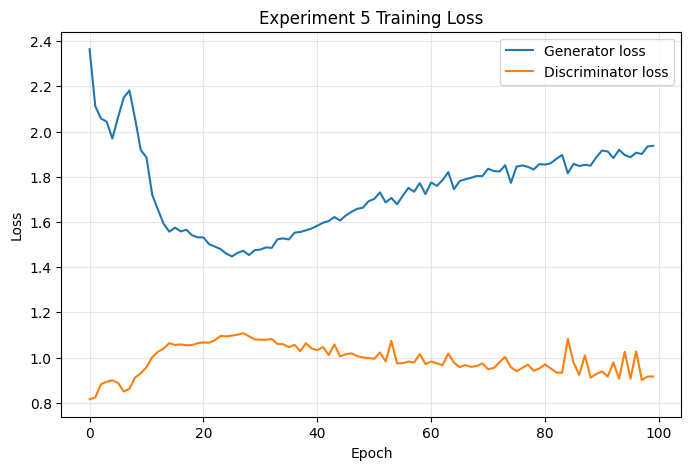

In [83]:
plot_training_losses(
    exp5_generator_losses,
    exp5_discriminator_losses,
    "Experiment 5 Training Loss"
)

### Experiment 5 — Model Training Results

* **First stage (Epochs 1–25):** Generator loss decreased strongly from **2.3644 to 1.4598**, while discriminator loss increased from **0.8154 to 1.0936**. This suggests the generator was improving and becoming more successful at challenging the discriminator.
* **Best balance around Epochs 25–35:** Generator loss reached its lowest region at approximately **1.45–1.50**, while discriminator loss stayed around **1.08–1.11**. The two networks were competing relatively steadily at this stage.
* **After around Epoch 35:** The trend begins to reverse. Generator loss gradually increases while discriminator loss generally decreases.
* **By Epoch 100:** Generator loss increased to **1.9370**, while discriminator loss decreased to **0.9160**. This indicates that the discriminator was gradually gaining an advantage over the generator.
* The fluctuations near the later epochs are normal for adversarial training, but the **consistent opposite movement** of the two losses is more important than the individual spikes.

### What does the graph tell us?

Increasing training from **50 to 100 epochs did not produce continuous improvement**. The model initially improved, but after roughly **25–35 epochs**, the adversarial balance began shifting toward the discriminator.

Therefore, **more epochs do not automatically mean a better GAN**. The loss graph suggests that Experiment 5 may have been trained beyond its most balanced region.

However, **we should not conclude yet that 100 epochs made the final model worse from the loss alone**. GAN losses do not directly measure image quality.

**Next:** compare Experiment 5's **generated samples and FID score with Experiment 4**. That will tell us whether the extra 50 epochs actually improved or worsened the final generated images.



### Experiment 5: Samples

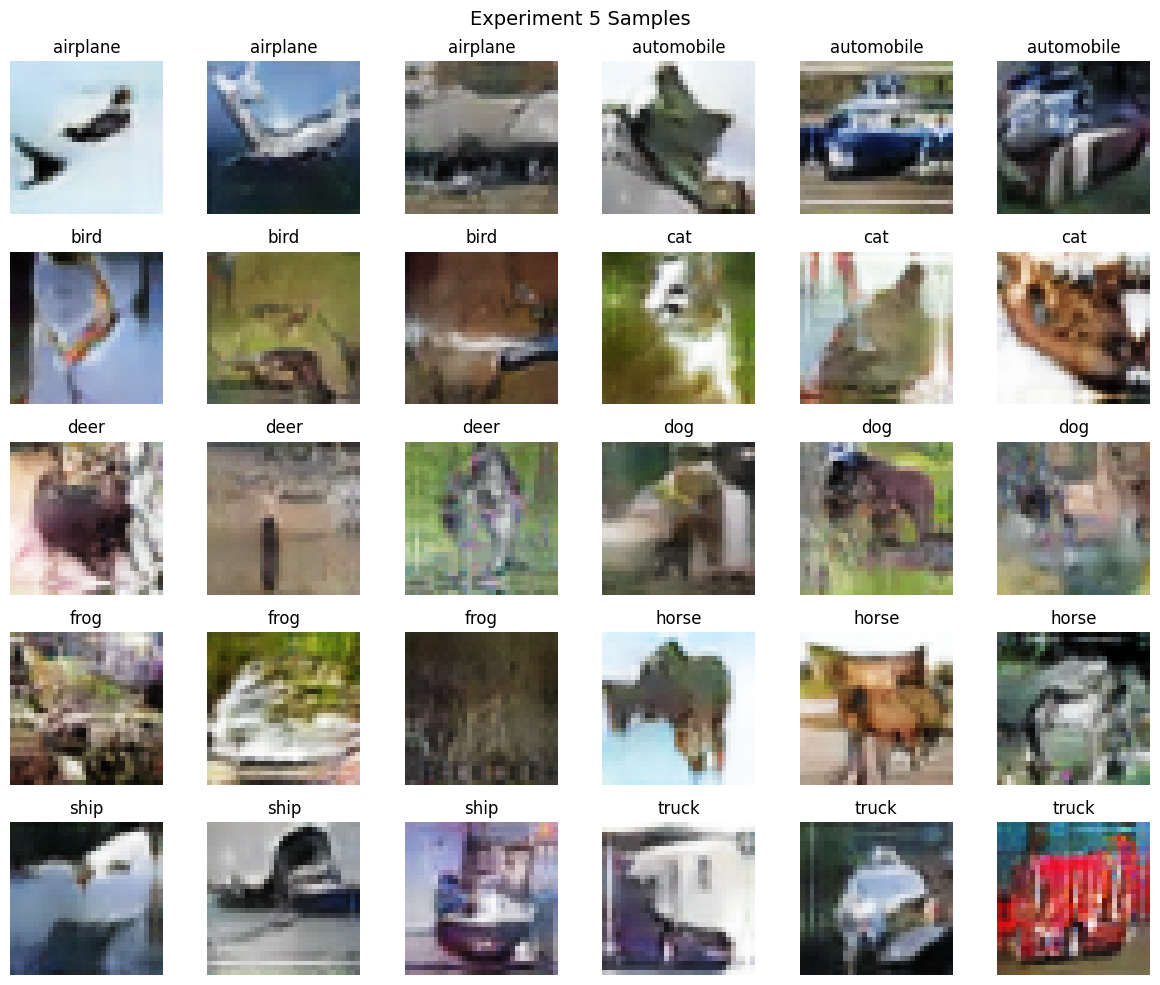

In [84]:
show_generated_images_per_class(
    generator=exp5_generator,
    latent_dim=EXP5_LATENT_DIM,
    images_per_class=3,
    title="Experiment 5 Samples"
)

### Experiment 5: FID Score

In [85]:
(
    exp5_generated_images,
    exp5_generated_labels
) = generate_conditional_images(
    exp5_generator,
    EXP5_LATENT_DIM,
    images_per_class=500,
    seed=SEED
)

exp5_generated_features = extract_fid_features(
    exp5_generated_images
)

exp5_fid = calculate_fid_from_features(
    real_fid_features,
    exp5_generated_features
)

print(
    f"Experiment 5 FID: "
    f"{exp5_fid:.4f}"
)

Experiment 5 FID: 39.0489


## Experiment 5 — Model Evaluation Results (FID)

### Visual Evaluation

* The generated images show **clearer object structures** across many classes after extending training to **100 epochs**.
* Several **airplanes, automobiles, horses, ships and trucks** are visually recognisable and match their intended labels.
* Compared with Experiment 4, many samples have **stronger object shapes and more defined features**, although some classes such as birds, frogs and deer remain blurry or ambiguous.
* Importantly, the model still produces **varied images within each class**, suggesting that the additional training did not simply cause obvious mode collapse.

### FID Score

**Experiment 5 FID = 39.0489**

| Model / Change                                            |       FID ↓ |
| --------------------------------------------------------- | ----------: |
| Baseline Conditional DCGAN                                |     55.1430 |
| Experiment 2 — Improved Generator + Label Smoothing (0.8) |     48.7743 |
| Experiment 4 — Experiment 2 + Data Augmentation           |     46.9750 |
| **Experiment 5 — Experiment 4 + 100 Epochs**              | **39.0489** |

The FID decreased from **46.9750 in Experiment 4 to 39.0489 in Experiment 5**, an improvement of about **16.9%**. It is also about **29.2% lower than the baseline FID of 55.1430**.

### Experiment 5: Generating 20 images for each class

In [87]:
(
    exp5_20_images,
    exp5_20_labels
) = generate_conditional_images(
    generator=exp5_generator,
    latent_dim=EXP5_LATENT_DIM,
    images_per_class=20,
    seed=2026
)

print(
    "Generated images shape:",
    exp5_20_images.shape
)

print(
    "Generated labels shape:",
    exp5_20_labels.shape
)

print(
    "Images per class:",
    np.bincount(
        exp5_20_labels,
        minlength=NUM_CLASSES
    )
)

Generated images shape: (200, 32, 32, 3)
Generated labels shape: (200,)
Images per class: [20 20 20 20 20 20 20 20 20 20]


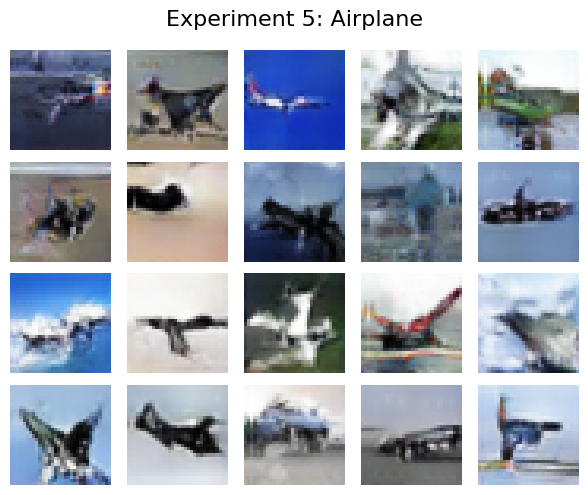

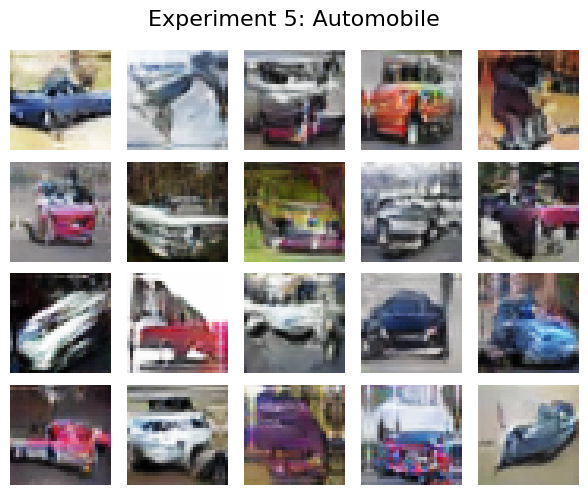

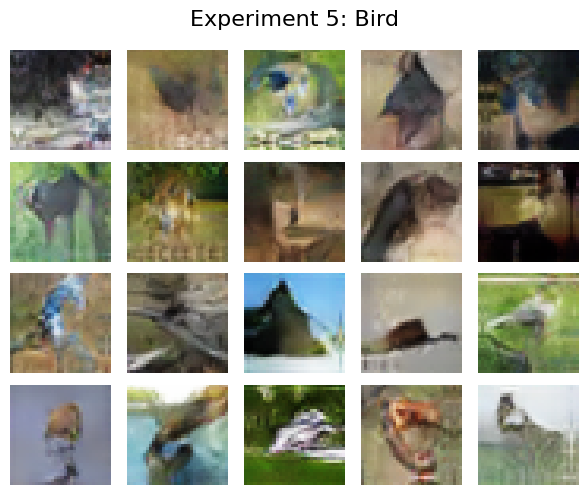

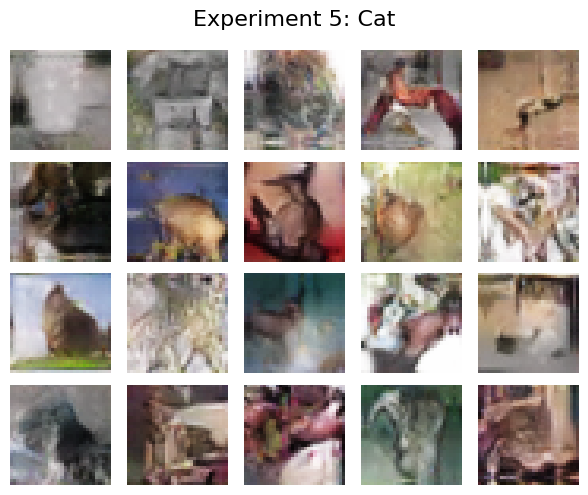

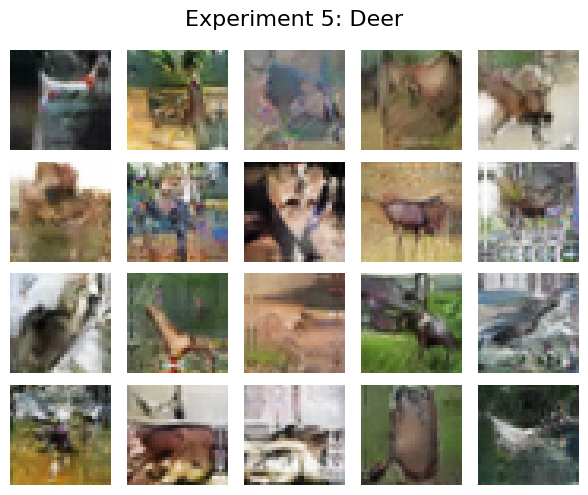

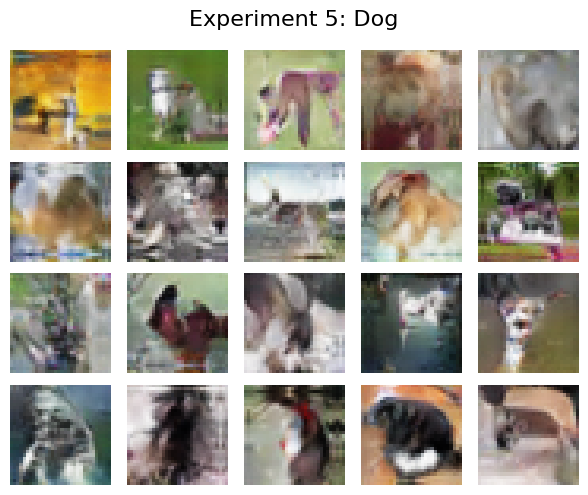

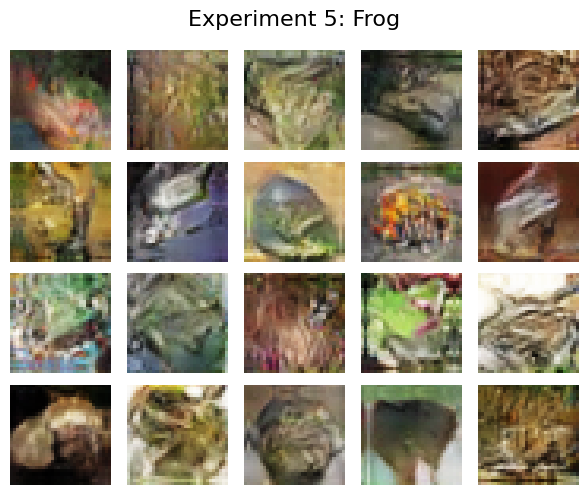

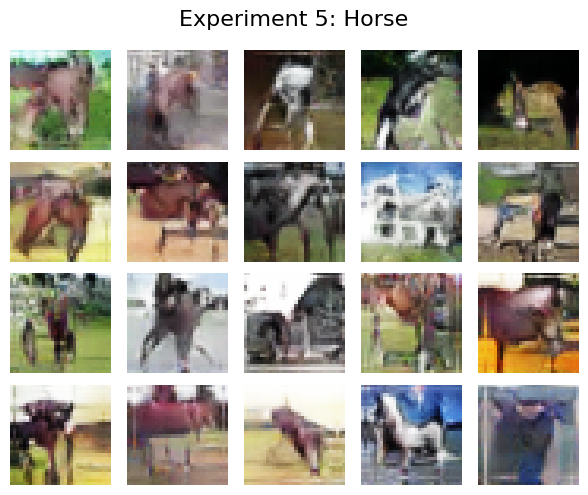

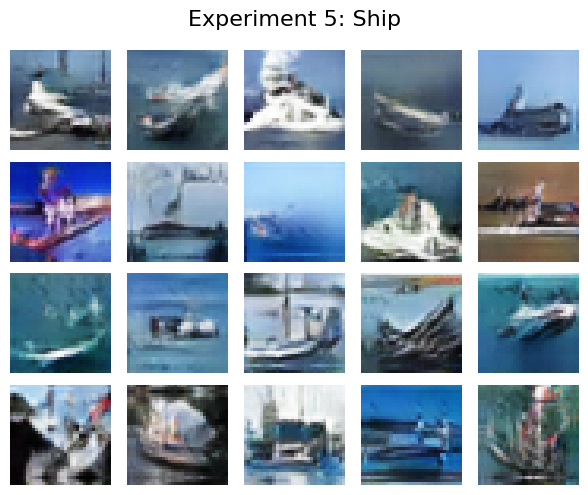

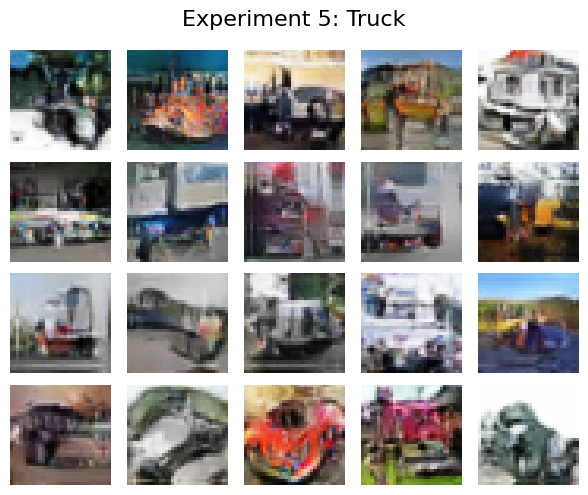

Saved 10 class grids to: C:\Users\User\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\experiment_5_grids


In [88]:
exp5_grid_directory = (
    OUTPUT_ROOT
    / "experiment_5_grids"
)

exp5_grid_directory.mkdir(
    parents=True,
    exist_ok=True
)

for class_id, class_name in enumerate(
    class_names
):

    class_images = exp5_20_images[
        exp5_20_labels == class_id
    ]

    figure, axes = plt.subplots(
        4,
        5,
        figsize=(6, 5)
    )

    for image_index, axis in enumerate(
        axes.flatten()
    ):

        axis.imshow(
            np.clip(
                class_images[image_index],
                0.0,
                1.0
            )
        )

        axis.axis("off")

    figure.suptitle(
        f"Experiment 5: "
        f"{class_name.capitalize()}",
        fontsize=16
    )

    plt.tight_layout()

    grid_file_path = (
        exp5_grid_directory
        / (
            f"exp5_{class_id}_"
            f"{class_name}_grid.png"
        )
    )

    plt.savefig(
        grid_file_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(
        figure
    )

print(
    "Saved 10 class grids to:",
    exp5_grid_directory.resolve()
)

### Experiment 5 — Visual Evaluation

| CIFAR-10 Class |   Clear | Marginal | Nonsense |   Total |
| -------------- | ------: | -------: | -------: | ------: |
| Airplane       |      15 |        4 |        1 |      20 |
| Automobile     |      15 |        4 |        1 |      20 |
| Bird           |      11 |        7 |        2 |      20 |
| Cat            |       7 |        8 |        5 |      20 |
| Deer           |      12 |        6 |        2 |      20 |
| Dog            |      11 |        6 |        3 |      20 |
| Frog           |      10 |        7 |        3 |      20 |
| Horse          |      15 |        4 |        1 |      20 |
| Ship           |  **17** |        3 |        0 |      20 |
| Truck          |      14 |        5 |        1 |      20 |
| **TOTAL**      | **127** |   **54** |   **19** | **200** |


- Clear: 63.5%
- Marginal: 27.0%
- Nonsense: 9.5%
  
A particularly noticeable strength is ship, where almost all generated images have recognizable watercraft structure. Airplane, automobile and horse are also strong. Cat remains the weakest class, showing that additional training did not solve every class equally.

# Comparison of Experiments 4 and 5


| Model                                             |   Clear ↑ |  Marginal | Nonsense ↓ |       FID ↓ |
| ------------------------------------------------- | --------: | --------: | ---------: | ----------: |
| Experiment 4 — Data Augmentation (50 Epochs)      |     54.5% |     31.5% |      14.0% |     46.9750 |
| Experiment 5 — Data Augmentation + 100 Epochs | **63.5%** | **27.0%** |   **9.5%** | **39.0489** |

### Visual Evaluation

| Experiment                                        | Visual Evaluation                                                                                                                                                                                                                                                             |
| ------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Experiment 4 — Data Augmentation (50 Epochs)**  | Generated several recognisable images, particularly for **deer, ship, automobile and horse**. However, only 54.5% of the 200 images were rated Clear, while 14.0% were Nonsense. Difficult animal classes such as **cat and frog** remained inconsistent.                     |
| **Experiment 5 — Data Augmentation + 100 Epochs** | Longer training produced **more clearly recognisable outputs across the classes**. Clear images increased to 63.5%, while Nonsense images decreased to only 9.5%. **Ship, airplane, automobile and horse** were particularly recognisable, although cat remained challenging. |

## Overfitting Check — Experiment 5

Since Experiment 5 was trained for **100 epochs**, possible overfitting was considered before selecting it as the final model.

- Generator loss was lowest around the middle epochs, then gradually increased towards Epoch 100.
- However, GAN losses do not behave like normal training/validation losses, so this alone does **not confirm overfitting**.
- FID improved from **46.9750 (Exp 4)** to **39.0489 (Exp 5)**.
- Visual evaluation also improved:
  - Clear: **54.5% → 63.5%**
  - Nonsense: **14.0% → 9.5%**
- Generated images remained varied across classes, with no obvious severe mode collapse.

**Conclusion:**  
There is no strong evidence of overfitting. Although later training showed diminishing improvement in the loss curves, both FID and visual evaluation improved. Therefore, **Experiment 5 was selected as the final model**.

# Final Selection — Experiment 5 (Data Augmentation + 100 Epochs)

### Why Experiment 5 was selected

* **Best visual recognisability:** Increasing training from 50 to 100 epochs increased the Clear rate from **54.5% to 63.5%**.
* **Fewer failed outputs:** The Nonsense rate decreased from **14.0% to 9.5%**, indicating fewer completely unrecognisable generated images.
* **Substantial FID improvement:** FID decreased from **46.9750 to 39.0489**, showing that Experiment 5's generated-image distribution was closer to the real CIFAR-10 distribution.
* **Additional training benefited the augmented model:** Experiment 4 showed that augmentation alone gave mixed results. Training the augmented model for longer allowed it to learn more effectively from the increased variation in the training data.
* **Both evaluation methods agree:** Unlike the Experiment 2 → 4 comparison, Experiment 5 improved in **both visual evaluation and FID**, providing stronger evidence of an overall improvement.

### Conclusion

**Increasing the training duration from 50 to 100 epochs improved the augmented model.** Experiment 5 achieved a substantially lower FID of **39.0489** while also increasing Clear images from **54.5% to 63.5%** and reducing Nonsense images from **14.0% to 9.5%**. Since both quantitative and visual evaluation show improvement, **Experiment 5 was selected as the final Conditional DCGAN model**.

## Final Evaluation on Unseen Test Data

In [93]:
# -------------------------------------------------
# Prepare CIFAR-10 Test Set for Final Evaluation
# -------------------------------------------------

test_images_final = x_test_raw.astype(
    "float32"
) / 255.0

test_labels_final = y_test_raw.reshape(-1)

print(
    "Final test images:",
    test_images_final.shape
)

print(
    "Final test labels:",
    test_labels_final.shape
)

print(
    "Test images per class:",
    np.bincount(
        test_labels_final,
        minlength=NUM_CLASSES
    )
)

Final test images: (10000, 32, 32, 3)
Final test labels: (10000,)
Test images per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [94]:
# -------------------------------------------------
# Extract Test Set FID Features in Batches
# -------------------------------------------------

TEST_FID_BATCH_SIZE = 500

test_fid_feature_batches = []

for start_index in range(
    0,
    len(test_images_final),
    TEST_FID_BATCH_SIZE
):

    end_index = min(
        start_index + TEST_FID_BATCH_SIZE,
        len(test_images_final)
    )

    batch_images = test_images_final[
        start_index:end_index
    ]

    batch_features = extract_fid_features(
        batch_images
    )

    test_fid_feature_batches.append(
        batch_features
    )

test_fid_features = np.concatenate(
    test_fid_feature_batches,
    axis=0
)

print(
    "Test FID features:",
    test_fid_features.shape
)

Test FID features: (10000, 2048)


In [95]:
# -------------------------------------------------
# Generate 10,000 Images from Final Experiment 5
# -------------------------------------------------

FINAL_TEST_IMAGES_PER_CLASS = 1000

(
    exp5_test_images,
    exp5_test_labels
) = generate_conditional_images(
    generator=exp5_generator,
    latent_dim=EXP5_LATENT_DIM,
    images_per_class=FINAL_TEST_IMAGES_PER_CLASS,
    seed=2026
)

print(
    "Generated test images:",
    exp5_test_images.shape
)

print(
    "Generated test labels:",
    exp5_test_labels.shape
)

print(
    "Generated images per class:",
    np.bincount(
        exp5_test_labels,
        minlength=NUM_CLASSES
    )
)

Generated test images: (10000, 32, 32, 3)
Generated test labels: (10000,)
Generated images per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [96]:
# -------------------------------------------------
# Extract Experiment 5 FID Features in Batches
# -------------------------------------------------

EXP5_TEST_FID_BATCH_SIZE = 500

exp5_test_feature_batches = []

for start_index in range(
    0,
    len(exp5_test_images),
    EXP5_TEST_FID_BATCH_SIZE
):

    end_index = min(
        start_index + EXP5_TEST_FID_BATCH_SIZE,
        len(exp5_test_images)
    )

    batch_images = exp5_test_images[
        start_index:end_index
    ]

    batch_features = extract_fid_features(
        batch_images
    )

    exp5_test_feature_batches.append(
        batch_features
    )

exp5_test_fid_features = np.concatenate(
    exp5_test_feature_batches,
    axis=0
)

print(
    "Experiment 5 test FID features:",
    exp5_test_fid_features.shape
)

Experiment 5 test FID features: (10000, 2048)


In [97]:
# -------------------------------------------------
# Calculate Overall Final Test FID
# -------------------------------------------------

final_test_fid = calculate_fid_from_features(
    test_fid_features,
    exp5_test_fid_features
)

print(
    "Final Experiment 5 Test FID:",
    float(final_test_fid)
)

Final Experiment 5 Test FID: 33.69163677817823


### Final Test Result

The final Experiment 5 model was evaluated using 10,000 generated images against the 10,000 unseen CIFAR-10 test images.

Final Test FID: 33.6916

The relatively low FID indicates that the generated images have a reasonably similar feature distribution to real CIFAR-10 images. Since the test images were kept separate from model training and experiment selection, this result provides an independent evaluation of how well the final model generalises to unseen real data.

Compared with the validation FID of 39.0489, the test FID is lower at 33.6916. However, this does not mean the model improved after testing, as no further training was performed. The difference is due to evaluating against a different and larger reference dataset.

Conclusion: The final test result supports the selection of Experiment 5 and shows that its performance was not limited only to the validation data.

## Generating Final 1000 images using Experiment 5 Model

In [91]:
FINAL_IMAGES_PER_CLASS = 100

(
    final_generated_images,
    final_generated_labels
) = generate_conditional_images(
    generator=exp5_generator,
    latent_dim=EXP5_LATENT_DIM,
    images_per_class=FINAL_IMAGES_PER_CLASS,
    seed=SEED
)

print(
    "Generated images shape:",
    final_generated_images.shape
)

print(
    "Generated labels shape:",
    final_generated_labels.shape
)

print(
    "Images per class:",
    np.bincount(
        final_generated_labels,
        minlength=NUM_CLASSES
    )
)

Generated images shape: (1000, 32, 32, 3)
Generated labels shape: (1000,)
Images per class: [100 100 100 100 100 100 100 100 100 100]


In [92]:
final_output_directory = (
    OUTPUT_ROOT
    / "final_1000_generated_images"
)

final_output_directory.mkdir(
    parents=True,
    exist_ok=True
)

saved_count = 0

for class_id, class_name in enumerate(
    class_names
):

    class_directory = (
        final_output_directory
        / class_name
    )

    class_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    class_images = final_generated_images[
        final_generated_labels == class_id
    ]

    for image_index, image in enumerate(
        class_images,
        start=1
    ):

        image_path = (
            class_directory
            / f"{class_name}_{image_index:03d}.png"
        )

        plt.imsave(
            image_path,
            np.clip(
                image,
                0.0,
                1.0
            )
        )

        saved_count += 1

print(
    "Total images saved:",
    saved_count
)

print(
    "Saved to:",
    final_output_directory.resolve()
)

Total images saved: 1000
Saved to: C:\Users\User\OneDrive - Singapore Polytechnic\DELE\CA2\part_a_outputs\final_1000_generated_images


# Class Difficulty Analysis

The visual evaluation shows that some CIFAR-10 classes were easier for the final model to generate than others.

| Class          |     Clear | Difficulty | Analysis                                                                                        |
| -------------- | --------: | ---------- | ----------------------------------------------------------------------------------------------- |
| **Ship**       | **17/20** | Easiest    | Distinctive overall structure and consistent water/background patterns make it easier to learn. |
| **Airplane**   | **15/20** | Easy       | Recognisable shape and common sky backgrounds provide strong visual patterns.                   |
| **Automobile** | **15/20** | Easy       | Cars have relatively consistent shapes and distinctive object boundaries.                       |
| **Horse**      | **15/20** | Easy       | Body and leg structures were reproduced relatively consistently.                                |
| **Cat**        |  **7/20** | Hardest    | High variation in appearance and similarity to other animals made clear generation difficult.   |
| **Frog**       | **10/20** | Hard       | Small and less distinctive shapes made some outputs ambiguous.                                  |
| **Dog**        | **11/20** | Hard       | Large variation in appearance and similarity to cats caused ambiguity.                          |

### Easier Classes

**Ship, airplane, automobile and horse** were relatively easier to generate.

**Why?**

* They have more **distinctive and consistent overall shapes**.
* Ships and airplanes also often have **predictable backgrounds**, such as water or sky.
* This gives the model repeated visual patterns that are easier to learn.
* Even at the low **32×32 resolution**, their general silhouettes can still be recognised.

### Harder Classes

**Cat, dog and frog** were relatively harder to generate.

**Why?**

* Animal appearances have much more **variation in pose, shape, colour and texture**.
* Cats and dogs also share similar features, making them harder to distinguish.
* Frogs can have less consistent shapes and blend into complex natural backgrounds.
* At **32×32 resolution**, small details such as faces, ears and body features are easily lost, making these classes more ambiguous.

**Overall:** Classes with **consistent and distinctive visual patterns were easier**, while classes with **high variation and similar features were harder** for the model to learn and reproduce.


# Generating Black-and-White Images

The current models were trained to generate **RGB CIFAR-10 images**. If the task were changed to black-and-white image generation, the effect on image quality would likely involve a trade-off.

| What would change?                     | Possible Effect                                                                                                |
| -------------------------------------- | -------------------------------------------------------------------------------------------------------------- |
| **Colour information removed**         | The generator would have less visual information to learn and reproduce.                                       |
| **Greater focus on shape and texture** | The model could focus more on object structure, edges and brightness patterns.                                 |
| **Simpler output representation**      | Generating grayscale intensity is simpler than reproducing three RGB colour channels.                          |
| **Loss of useful visual cues**         | Colour differences between objects and backgrounds would disappear.                                            |
| **Low 32×32 resolution remains**       | With limited shape detail already available, removing colour could make some objects even harder to recognise. |

### Possible Positive Effect

Black-and-white generation could potentially make the **generation process simpler**. The model would no longer need to reproduce realistic combinations of RGB colours and could concentrate more on:

* object shape,
* edges,
* texture,
* light and dark regions.

This could help the model produce cleaner basic structures, particularly for classes with distinctive shapes such as **airplanes, automobiles, ships and trucks**.

### Possible Negative Effect

However, the current results suggest that **recognisability is already challenging for visually similar classes**. Removing colour could make this worse.

For example:

**Cat ↔ Dog**

Both have similar four-legged animal structures at only 32×32 resolution. Colour and texture can provide additional clues, so removing them may make generated cats and dogs even more difficult to distinguish.

Similarly:

**Ship → water/background cues**
**Airplane → sky/background cues**
**Frog → colour/texture cues**

Some of these contextual features may become less informative in grayscale.

### Expected Outcome

Therefore, I would **not automatically expect a black-and-white model to produce better-quality results**.

It may become:

**Easier to generate basic structure**
↓
because the colour information is simplified

but potentially:

**Harder to preserve class recognisability**
↓
because useful colour and contextual information is lost.

### Overall Analysis

> If the dataset were converted to black and white, the generation task would become simpler in terms of colour representation, allowing the model to focus more on shapes and textures. However, CIFAR-10 images are only 32×32 pixels, meaning that fine structural details are already limited. Colour therefore provides additional information that helps distinguish objects and backgrounds. Removing it could particularly affect visually similar classes such as cats and dogs. As a result, black-and-white generation may simplify the learning problem, but it would **not necessarily improve the recognisability or overall quality of the generated images**.